# MLP Optimize

## Notes
- This notebook aims to be the more optimized version of `MLP_Manual.ipynb` choosing the best:
    - Epoch
        - `[50, 100, 150, 200]`
    - Batch
        - `[len(data) / 100, 50, 10, 5, 2, 1]`
    - Learning Rate
        - `[1e-2, 1e-3]`
    - Weight Decay
        - `[1e-2, 1e-3]`
- About 96 runs
- The "best" run is the run with the highest $\text{F1}$.

## File Conversion

### Imports

In [1]:
# General Data
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from math import ceil
from time import perf_counter
from datetime import datetime

In [2]:
# Load the ECG
TRAIN_ECG  = np.load('train_ecg.npz')
TRAIN_ECGx = TRAIN_ECG['X']
TRAIN_ECGy = TRAIN_ECG['y']

VALID_ECG  = np.load('validation_ecg.npz')
VALID_ECGx = VALID_ECG['X']
VALID_ECGy = VALID_ECG['y']

# Convert the dictionary-like npz contents into a Pandas DataFrame
# Assumes arrays have the same lengths/shapes
df_train = pd.DataFrame(TRAIN_ECGx, columns=[f'x_{i+1}' for i in range(TRAIN_ECGx.shape[1])])
df_train['target'] = TRAIN_ECGy

df_valid = pd.DataFrame(VALID_ECGx, columns=[f'x_{i+1}' for i in range(VALID_ECGx.shape[1])])
df_valid['target'] = VALID_ECGy

In [3]:
{
    'df_train': df_train.shape,
    'df_valid': df_valid.shape,
}

{'df_train': (51182, 253), 'df_valid': (15367, 253)}

In [4]:
df_train['target'].value_counts()

target
0    46397
1     4785
Name: count, dtype: int64

In [5]:
df_valid['target'].value_counts()

target
0    13892
1     1475
Name: count, dtype: int64

## MLP NN

In [6]:
import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score, confusion_matrix, classification_report, f1_score

In [7]:
print('CUDA:', torch.version.cuda, '| Available:', torch.cuda.is_available(), '| Device:', torch.cuda.get_device_name(0))

CUDA: 13.4 | Available: True | Device: NVIDIA GeForce RTX 4070 Laptop GPU


In [8]:
SEED = 825
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED) # Set the random seed for reproducibility
device = torch.device("cuda" if torch.cuda.is_available() else "cpu") # Set the device to GPU if available, otherwise CPU

# Class wights for training set frequencies
class_counts = np.bincount(TRAIN_ECGy)
class_weights = len(TRAIN_ECGy) / (len(class_counts) * class_counts)
class_weights = torch.tensor(
    class_weights,
    dtype=torch.float32
    ).to(device)
print(f"Class weights: \n{class_weights}")

criterion      = nn.CrossEntropyLoss(weight=class_weights) # Loss Function for multi-class classification
eval_criterion = nn.CrossEntropyLoss()

Class weights: 
tensor([0.5516, 5.3482], device='cuda:0')


In [9]:
feature_cols = [c for c in df_train.columns if c != 'target']
scaler = StandardScaler().fit(df_train[feature_cols])

def to_tensor_dataset(df):
    '''
    Substitutes **W11_D2**'s `balanced_subset()` function. \n
    Converts a DataFrame into a PyTorch TensorDataset.
    '''
    # Extract features and labels
    X = torch.tensor(scaler.transform(df[feature_cols]), dtype=torch.float32)
    y = torch.tensor(df['target'].values, dtype=torch.long)
    
    return TensorDataset(X, y)

In [10]:
train_data = to_tensor_dataset(df_train)
valid_data = to_tensor_dataset(df_valid)

train_loader = DataLoader(train_data, batch_size=512, shuffle=False)
valid_loader = DataLoader(valid_data, batch_size=512, shuffle=False)

In [11]:
print(f"Train DataLoader: {len(train_loader)} batches, each with {train_loader.batch_size} samples")
print(f"Validation DataLoader: {len(valid_loader)} batches, each with {valid_loader.batch_size} samples")

Train DataLoader: 100 batches, each with 512 samples
Validation DataLoader: 31 batches, each with 512 samples


### `evaluate(model, loader)` Function

In [12]:
def evaluate(model, loader):
    model.eval()
    total, probs, labels = 0.0, [], []
    with torch.inference_mode():
        for X_batch, y_batch in loader:
            X_batch = X_batch.to(device)
            y_batch = y_batch.to(device)

            logits = model(X_batch)
            total += eval_criterion(logits, y_batch).item() * len(y_batch) # criterion(logits, y_batch).item() * len(y_batch)
            probs.append(torch.softmax(logits, dim=1)[:, 1].cpu())  # P(abnormal)
            labels.append(y_batch.cpu())
    return total / len(loader.dataset), torch.cat(probs).numpy(), torch.cat(labels).numpy()

## Parameters

In [13]:
EPOCHS       = [50, 100, 150, 200]
ALPHAS       = [1e-2, 1e-3]
WEIGHT_DECAY = [1e-2, 1e-3]

def batchSizes(data):
    return [ceil(len(data)/100), ceil(len(data)/50), ceil(len(data)/10), ceil(len(data)/5), ceil(len(data)/5), len(data)]

### `fit(model_class)` Function

In [14]:
def fit(
        model_class, 
        data,
        ITER_epochs,
        ITER_batchSize,
        ITER_alpha,
        ITER_weight_decay):
    torch.manual_seed(SEED)
    
    # Create instance of model
    model = model_class().to(device)
    loader = DataLoader(
        data, 
        batch_size=ITER_batchSize, # Full Batch
        shuffle   =False
    )
    optimizer = torch.optim.Adam(
        model.parameters(), 
        lr          =ITER_alpha,
        weight_decay=ITER_weight_decay)

    epoch_log, loss_log, = [], []
    for epoch in range(ITER_epochs):
        model.train()
        total_loss = 0
        for X_batch, y_batch in loader:
            epoch_start = perf_counter() # Start timer
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)
            
            # Backpropigation
            optimizer.zero_grad()
            outputs = model(X_batch)
            loss = criterion(outputs, y_batch)
            loss.backward()
            optimizer.step()

            total_loss += loss.item()
        loss_proportion = total_loss / len(loader)
        epoch_elapsed = perf_counter() - epoch_start # End timer
        print(f"Epoch {epoch+1}/{ITER_epochs}, Loss: {loss_proportion:.4f} | {epoch_elapsed:.3f}s")
        epoch_log.append(epoch+1)
        loss_log.append(loss_proportion)
    return model, epoch_log, loss_log

### MLP Class

In [15]:
class MLP(nn.Module):
    def __init__(self):
        super(MLP, self).__init__()
        self.flatten = nn.Flatten()       # Flattens the input tensor to a 1D tensor
        self.hidden  = nn.Linear(252, 32) # Mapping 252 input features (x_n) to 32 hidden neurons
        self.output  = nn.Linear(32, 2)   # Mapping 32 hidden neurons to 2 output classes (normal/abnormal)
    
    def forward(self, x):
        z = self.hidden(self.flatten(x))
        h = torch.relu(z)
        return self.output(h)

### Training and Validation

In [16]:
from itertools import product
import gc

In [17]:
BATCHES = batchSizes(train_data)

BATCHES, EPOCHS, ALPHAS, WEIGHT_DECAY
params = (BATCHES, EPOCHS, ALPHAS, WEIGHT_DECAY)

In [18]:
runLog = []

In [19]:
device # Check

device(type='cuda')

 ==========     ==========     ==========     ==========
ITERATION [0/96]: 10:04:04 PM
    Batch Size:   512
    Epochs:       50
    α:            0.01
    Weight Decay: 0.01
    
Epoch 1/50, Loss: 1.5839 | 0.004s
Epoch 2/50, Loss: 0.3193 | 0.002s
Epoch 3/50, Loss: 0.1844 | 0.002s
Epoch 4/50, Loss: 0.1560 | 0.002s
Epoch 5/50, Loss: 0.2878 | 0.002s
Epoch 6/50, Loss: 0.1211 | 0.008s
Epoch 7/50, Loss: 0.1780 | 0.002s
Epoch 8/50, Loss: 0.4968 | 0.002s
Epoch 9/50, Loss: 0.1523 | 0.003s
Epoch 10/50, Loss: 0.1384 | 0.004s
Epoch 11/50, Loss: 0.1041 | 0.002s
Epoch 12/50, Loss: 0.1678 | 0.002s
Epoch 13/50, Loss: 0.1464 | 0.001s
Epoch 14/50, Loss: 0.1100 | 0.003s
Epoch 15/50, Loss: 0.1353 | 0.002s
Epoch 16/50, Loss: 0.1357 | 0.003s
Epoch 17/50, Loss: 0.0953 | 0.002s
Epoch 18/50, Loss: 0.1455 | 0.003s
Epoch 19/50, Loss: 0.1119 | 0.002s
Epoch 20/50, Loss: 0.1767 | 0.003s
Epoch 21/50, Loss: 0.1451 | 0.002s
Epoch 22/50, Loss: 0.0878 | 0.002s
Epoch 23/50, Loss: 0.1959 | 0.002s
Epoch 24/50, Loss: 0.38

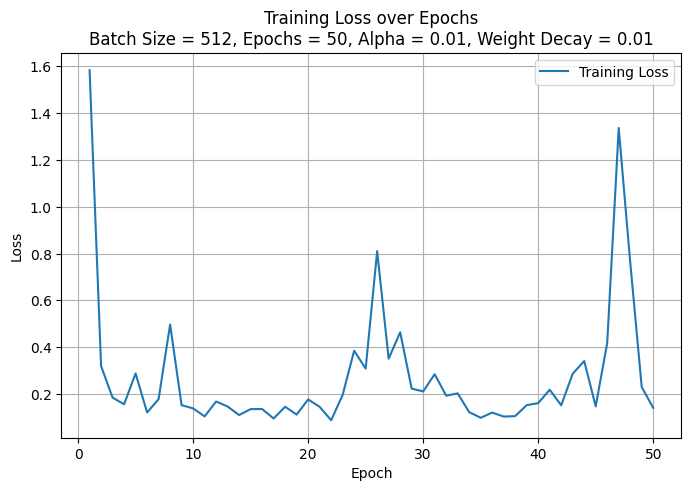

Train loss 0.0766 | Valid loss 0.6427
Valid ROC AUC: 0.911
              precision    recall  f1-score   support

           0      0.985     0.793     0.879     13892
           1      0.312     0.886     0.462      1475

    accuracy                          0.802     15367
   macro avg      0.649     0.840     0.670     15367
weighted avg      0.920     0.802     0.839     15367

[[11015  2877]
 [  168  1307]]


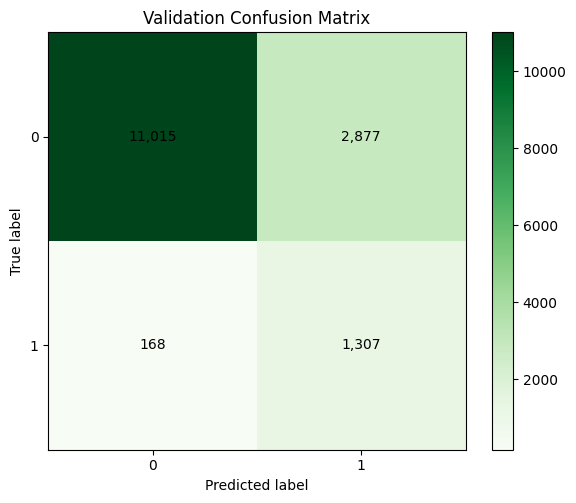

Iteration elapsed: 32.72s
 ==========     ==========     ==========     ==========
ITERATION [1/96]: 10:04:37 PM
    Batch Size:   512
    Epochs:       50
    α:            0.01
    Weight Decay: 0.001
    
Epoch 1/50, Loss: 1.8649 | 0.002s
Epoch 2/50, Loss: 0.4757 | 0.002s
Epoch 3/50, Loss: 0.2835 | 0.002s
Epoch 4/50, Loss: 0.1756 | 0.002s
Epoch 5/50, Loss: 0.1860 | 0.002s
Epoch 6/50, Loss: 0.1682 | 0.007s
Epoch 7/50, Loss: 0.1235 | 0.003s
Epoch 8/50, Loss: 0.0560 | 0.003s
Epoch 9/50, Loss: 0.0515 | 0.002s
Epoch 10/50, Loss: 0.0467 | 0.002s
Epoch 11/50, Loss: 0.0422 | 0.003s
Epoch 12/50, Loss: 0.0412 | 0.001s
Epoch 13/50, Loss: 0.0407 | 0.002s
Epoch 14/50, Loss: 0.0417 | 0.003s
Epoch 15/50, Loss: 0.0371 | 0.003s
Epoch 16/50, Loss: 0.0438 | 0.003s
Epoch 17/50, Loss: 0.0691 | 0.002s
Epoch 18/50, Loss: 0.2903 | 0.002s
Epoch 19/50, Loss: 2.2134 | 0.004s
Epoch 20/50, Loss: 1.4942 | 0.004s
Epoch 21/50, Loss: 0.4507 | 0.002s
Epoch 22/50, Loss: 0.3806 | 0.002s
Epoch 23/50, Loss: 0.1566 | 0.0

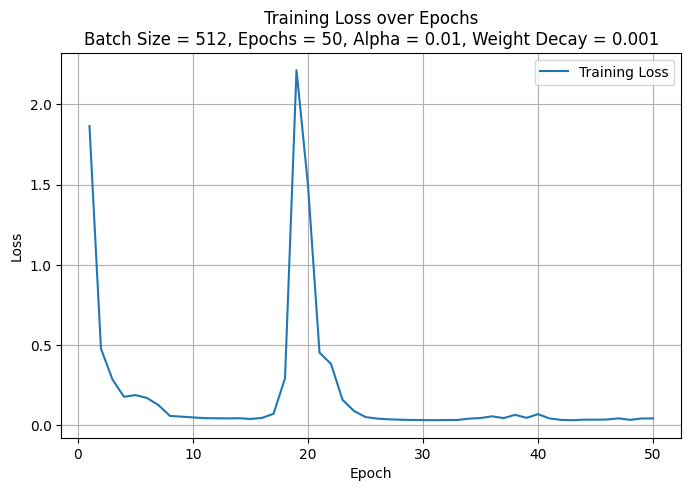

Train loss 0.0360 | Valid loss 0.4067
Valid ROC AUC: 0.969
              precision    recall  f1-score   support

           0      0.993     0.870     0.928     13892
           1      0.436     0.945     0.596      1475

    accuracy                          0.877     15367
   macro avg      0.714     0.908     0.762     15367
weighted avg      0.940     0.877     0.896     15367

[[12086  1806]
 [   81  1394]]


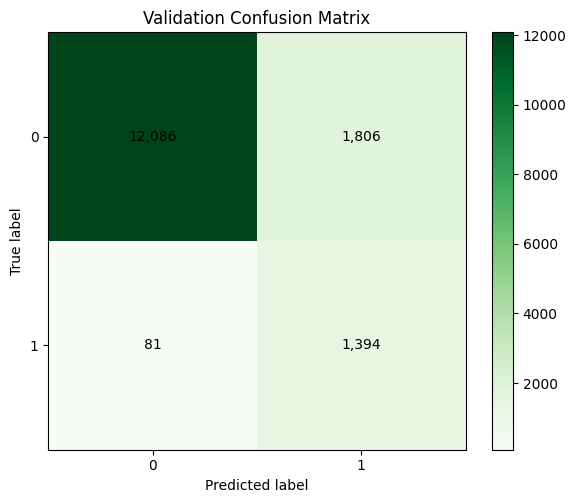

Iteration elapsed: 29.51s
 ==========     ==========     ==========     ==========
ITERATION [2/96]: 10:05:06 PM
    Batch Size:   512
    Epochs:       50
    α:            0.001
    Weight Decay: 0.01
    
Epoch 1/50, Loss: 0.6153 | 0.001s
Epoch 2/50, Loss: 0.2552 | 0.002s
Epoch 3/50, Loss: 0.1877 | 0.003s
Epoch 4/50, Loss: 0.1580 | 0.002s
Epoch 5/50, Loss: 0.1421 | 0.005s
Epoch 6/50, Loss: 0.1279 | 0.003s
Epoch 7/50, Loss: 0.1158 | 0.002s
Epoch 8/50, Loss: 0.1061 | 0.002s
Epoch 9/50, Loss: 0.0967 | 0.002s
Epoch 10/50, Loss: 0.0887 | 0.002s
Epoch 11/50, Loss: 0.0814 | 0.002s
Epoch 12/50, Loss: 0.0758 | 0.003s
Epoch 13/50, Loss: 0.0705 | 0.001s
Epoch 14/50, Loss: 0.0675 | 0.004s
Epoch 15/50, Loss: 0.0641 | 0.002s
Epoch 16/50, Loss: 0.0614 | 0.002s
Epoch 17/50, Loss: 0.0601 | 0.010s
Epoch 18/50, Loss: 0.0580 | 0.002s
Epoch 19/50, Loss: 0.0561 | 0.002s
Epoch 20/50, Loss: 0.0567 | 0.002s
Epoch 21/50, Loss: 0.0539 | 0.002s
Epoch 22/50, Loss: 0.0543 | 0.002s
Epoch 23/50, Loss: 0.0524 | 0.0

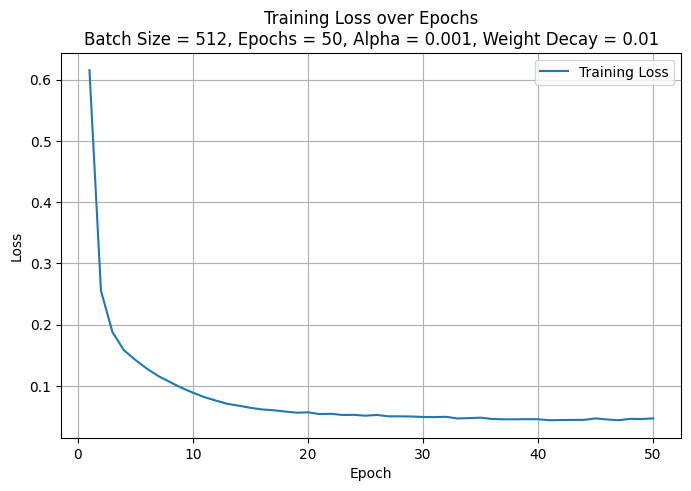

Train loss 0.0350 | Valid loss 0.3417
Valid ROC AUC: 0.962
              precision    recall  f1-score   support

           0      0.994     0.873     0.930     13892
           1      0.443     0.948     0.604      1475

    accuracy                          0.881     15367
   macro avg      0.718     0.911     0.767     15367
weighted avg      0.941     0.881     0.898     15367

[[12132  1760]
 [   76  1399]]


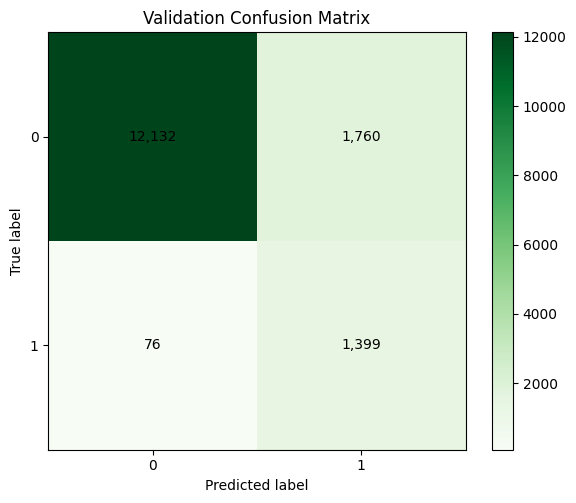

Iteration elapsed: 28.72s
 ==========     ==========     ==========     ==========
ITERATION [3/96]: 10:05:35 PM
    Batch Size:   512
    Epochs:       50
    α:            0.001
    Weight Decay: 0.001
    
Epoch 1/50, Loss: 0.6183 | 0.002s
Epoch 2/50, Loss: 0.2429 | 0.002s
Epoch 3/50, Loss: 0.1817 | 0.002s
Epoch 4/50, Loss: 0.1513 | 0.002s
Epoch 5/50, Loss: 0.1346 | 0.002s
Epoch 6/50, Loss: 0.1202 | 0.002s
Epoch 7/50, Loss: 0.1077 | 0.002s
Epoch 8/50, Loss: 0.0963 | 0.004s
Epoch 9/50, Loss: 0.0863 | 0.003s
Epoch 10/50, Loss: 0.0771 | 0.002s
Epoch 11/50, Loss: 0.0691 | 0.002s
Epoch 12/50, Loss: 0.0624 | 0.004s
Epoch 13/50, Loss: 0.0567 | 0.002s
Epoch 14/50, Loss: 0.0520 | 0.010s
Epoch 15/50, Loss: 0.0491 | 0.002s
Epoch 16/50, Loss: 0.0456 | 0.002s
Epoch 17/50, Loss: 0.0427 | 0.004s
Epoch 18/50, Loss: 0.0404 | 0.002s
Epoch 19/50, Loss: 0.0379 | 0.002s
Epoch 20/50, Loss: 0.0361 | 0.002s
Epoch 21/50, Loss: 0.0351 | 0.001s
Epoch 22/50, Loss: 0.0336 | 0.002s
Epoch 23/50, Loss: 0.0325 | 0.

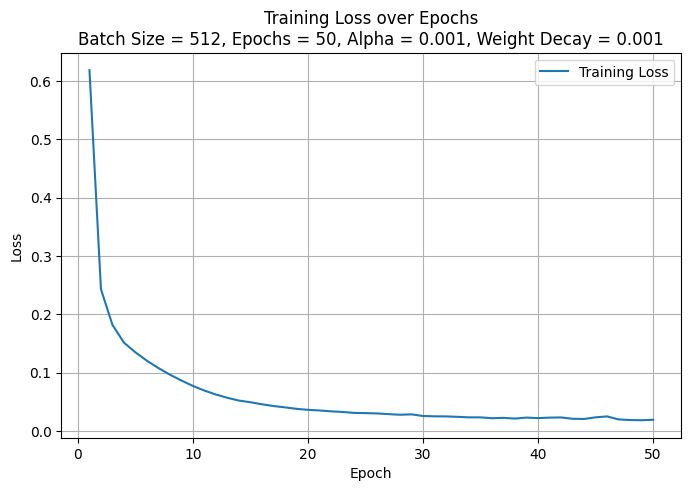

Train loss 0.0157 | Valid loss 0.6379
Valid ROC AUC: 0.938
              precision    recall  f1-score   support

           0      0.991     0.866     0.924     13892
           1      0.424     0.929     0.582      1475

    accuracy                          0.872     15367
   macro avg      0.708     0.898     0.753     15367
weighted avg      0.937     0.872     0.892     15367

[[12030  1862]
 [  104  1371]]


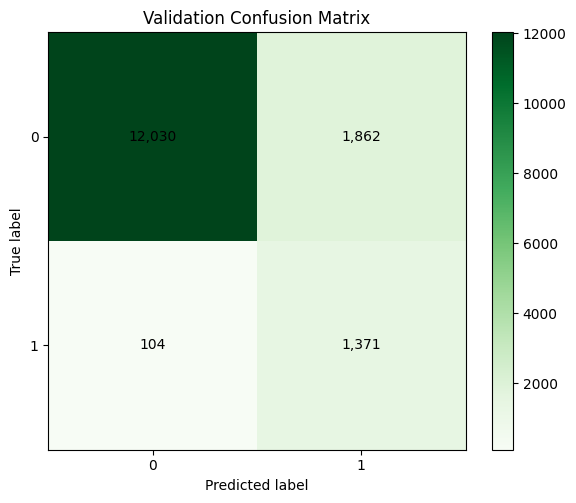

Iteration elapsed: 30.00s
 ==========     ==========     ==========     ==========
ITERATION [4/96]: 10:06:06 PM
    Batch Size:   512
    Epochs:       100
    α:            0.01
    Weight Decay: 0.01
    
Epoch 1/100, Loss: 1.5839 | 0.002s
Epoch 2/100, Loss: 0.3193 | 0.002s
Epoch 3/100, Loss: 0.1844 | 0.002s
Epoch 4/100, Loss: 0.1560 | 0.002s
Epoch 5/100, Loss: 0.2878 | 0.004s
Epoch 6/100, Loss: 0.1211 | 0.002s
Epoch 7/100, Loss: 0.1780 | 0.003s
Epoch 8/100, Loss: 0.4968 | 0.003s
Epoch 9/100, Loss: 0.1523 | 0.002s
Epoch 10/100, Loss: 0.1384 | 0.001s
Epoch 11/100, Loss: 0.1041 | 0.002s
Epoch 12/100, Loss: 0.1678 | 0.001s
Epoch 13/100, Loss: 0.1464 | 0.003s
Epoch 14/100, Loss: 0.1100 | 0.002s
Epoch 15/100, Loss: 0.1353 | 0.002s
Epoch 16/100, Loss: 0.1357 | 0.002s
Epoch 17/100, Loss: 0.0953 | 0.003s
Epoch 18/100, Loss: 0.1455 | 0.009s
Epoch 19/100, Loss: 0.1119 | 0.003s
Epoch 20/100, Loss: 0.1767 | 0.002s
Epoch 21/100, Loss: 0.1451 | 0.002s
Epoch 22/100, Loss: 0.0878 | 0.002s
Epoch 23/

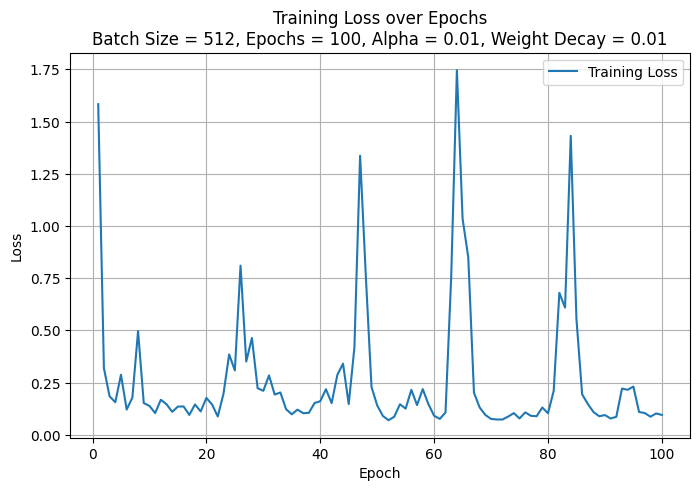

Train loss 0.0473 | Valid loss 0.2955
Valid ROC AUC: 0.944
              precision    recall  f1-score   support

           0      0.985     0.888     0.934     13892
           1      0.454     0.875     0.598      1475

    accuracy                          0.887     15367
   macro avg      0.720     0.882     0.766     15367
weighted avg      0.934     0.887     0.902     15367

[[12342  1550]
 [  185  1290]]


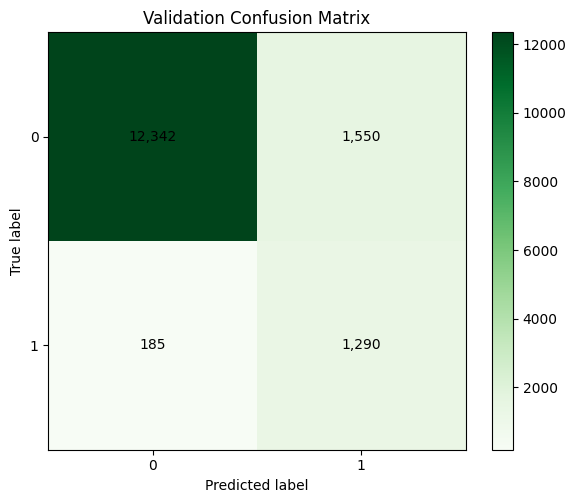

Iteration elapsed: 56.79s
 ==========     ==========     ==========     ==========
ITERATION [5/96]: 10:07:03 PM
    Batch Size:   512
    Epochs:       100
    α:            0.01
    Weight Decay: 0.001
    
Epoch 1/100, Loss: 1.8649 | 0.002s
Epoch 2/100, Loss: 0.4757 | 0.002s
Epoch 3/100, Loss: 0.2835 | 0.002s
Epoch 4/100, Loss: 0.1756 | 0.002s
Epoch 5/100, Loss: 0.1860 | 0.002s
Epoch 6/100, Loss: 0.1682 | 0.003s
Epoch 7/100, Loss: 0.1235 | 0.005s
Epoch 8/100, Loss: 0.0560 | 0.004s
Epoch 9/100, Loss: 0.0515 | 0.002s
Epoch 10/100, Loss: 0.0467 | 0.002s
Epoch 11/100, Loss: 0.0422 | 0.002s
Epoch 12/100, Loss: 0.0412 | 0.003s
Epoch 13/100, Loss: 0.0407 | 0.002s
Epoch 14/100, Loss: 0.0417 | 0.002s
Epoch 15/100, Loss: 0.0371 | 0.002s
Epoch 16/100, Loss: 0.0438 | 0.002s
Epoch 17/100, Loss: 0.0691 | 0.002s
Epoch 18/100, Loss: 0.2903 | 0.003s
Epoch 19/100, Loss: 2.2134 | 0.003s
Epoch 20/100, Loss: 1.4942 | 0.001s
Epoch 21/100, Loss: 0.4507 | 0.003s
Epoch 22/100, Loss: 0.3806 | 0.005s
Epoch 23

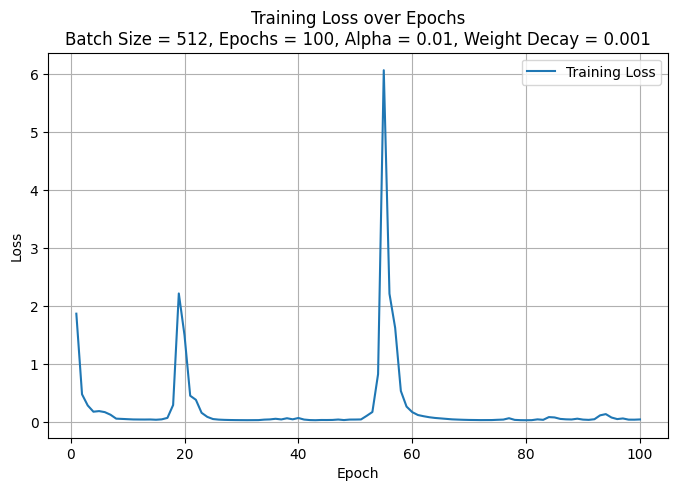

Train loss 0.0237 | Valid loss 0.5115
Valid ROC AUC: 0.949
              precision    recall  f1-score   support

           0      0.993     0.875     0.930     13892
           1      0.445     0.944     0.605      1475

    accuracy                          0.882     15367
   macro avg      0.719     0.909     0.768     15367
weighted avg      0.941     0.882     0.899     15367

[[12158  1734]
 [   83  1392]]


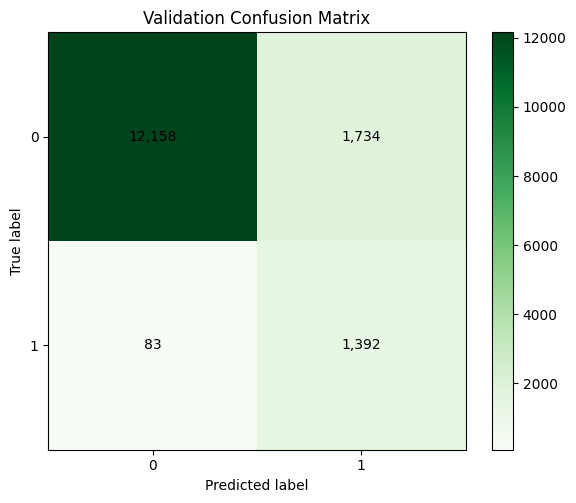

Iteration elapsed: 58.18s
 ==========     ==========     ==========     ==========
ITERATION [6/96]: 10:08:01 PM
    Batch Size:   512
    Epochs:       100
    α:            0.001
    Weight Decay: 0.01
    
Epoch 1/100, Loss: 0.6153 | 0.003s
Epoch 2/100, Loss: 0.2552 | 0.002s
Epoch 3/100, Loss: 0.1877 | 0.002s
Epoch 4/100, Loss: 0.1580 | 0.003s
Epoch 5/100, Loss: 0.1421 | 0.014s
Epoch 6/100, Loss: 0.1279 | 0.001s
Epoch 7/100, Loss: 0.1158 | 0.002s
Epoch 8/100, Loss: 0.1061 | 0.002s
Epoch 9/100, Loss: 0.0967 | 0.003s
Epoch 10/100, Loss: 0.0887 | 0.002s
Epoch 11/100, Loss: 0.0814 | 0.006s
Epoch 12/100, Loss: 0.0758 | 0.003s
Epoch 13/100, Loss: 0.0705 | 0.004s
Epoch 14/100, Loss: 0.0675 | 0.002s
Epoch 15/100, Loss: 0.0641 | 0.002s
Epoch 16/100, Loss: 0.0614 | 0.010s
Epoch 17/100, Loss: 0.0601 | 0.002s
Epoch 18/100, Loss: 0.0580 | 0.002s
Epoch 19/100, Loss: 0.0561 | 0.003s
Epoch 20/100, Loss: 0.0567 | 0.003s
Epoch 21/100, Loss: 0.0539 | 0.010s
Epoch 22/100, Loss: 0.0543 | 0.002s
Epoch 23

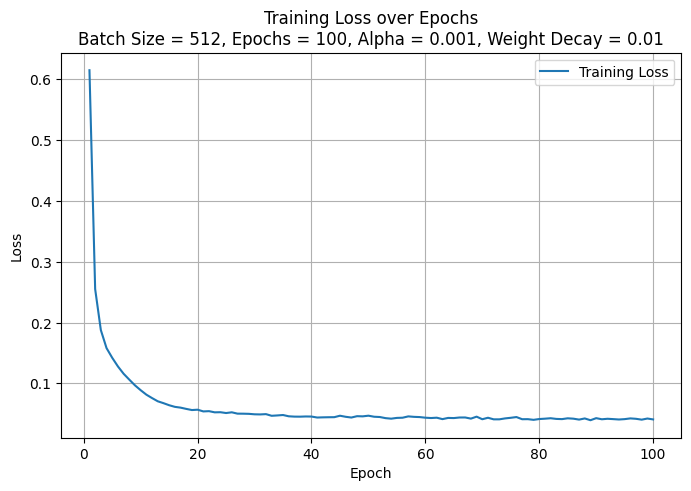

Train loss 0.0336 | Valid loss 0.3431
Valid ROC AUC: 0.952
              precision    recall  f1-score   support

           0      0.990     0.881     0.933     13892
           1      0.451     0.917     0.605      1475

    accuracy                          0.885     15367
   macro avg      0.721     0.899     0.769     15367
weighted avg      0.938     0.885     0.901     15367

[[12245  1647]
 [  122  1353]]


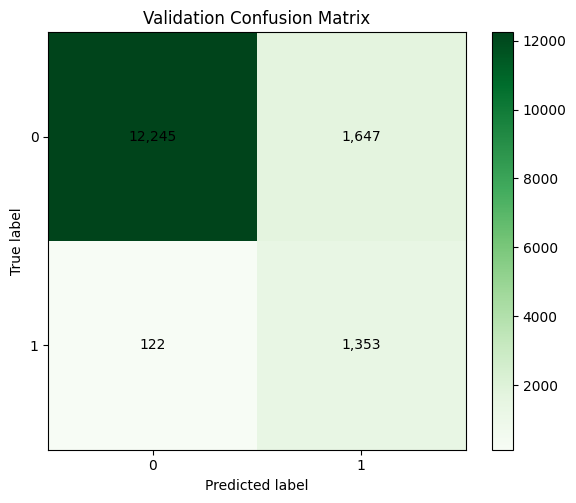

Iteration elapsed: 60.30s
 ==========     ==========     ==========     ==========
ITERATION [7/96]: 10:09:02 PM
    Batch Size:   512
    Epochs:       100
    α:            0.001
    Weight Decay: 0.001
    
Epoch 1/100, Loss: 0.6183 | 0.002s
Epoch 2/100, Loss: 0.2429 | 0.002s
Epoch 3/100, Loss: 0.1817 | 0.002s
Epoch 4/100, Loss: 0.1513 | 0.002s
Epoch 5/100, Loss: 0.1346 | 0.009s
Epoch 6/100, Loss: 0.1202 | 0.002s
Epoch 7/100, Loss: 0.1077 | 0.003s
Epoch 8/100, Loss: 0.0963 | 0.002s
Epoch 9/100, Loss: 0.0863 | 0.003s
Epoch 10/100, Loss: 0.0771 | 0.002s
Epoch 11/100, Loss: 0.0691 | 0.002s
Epoch 12/100, Loss: 0.0624 | 0.002s
Epoch 13/100, Loss: 0.0567 | 0.003s
Epoch 14/100, Loss: 0.0520 | 0.002s
Epoch 15/100, Loss: 0.0491 | 0.002s
Epoch 16/100, Loss: 0.0456 | 0.002s
Epoch 17/100, Loss: 0.0427 | 0.004s
Epoch 18/100, Loss: 0.0404 | 0.002s
Epoch 19/100, Loss: 0.0379 | 0.003s
Epoch 20/100, Loss: 0.0361 | 0.002s
Epoch 21/100, Loss: 0.0351 | 0.002s
Epoch 22/100, Loss: 0.0336 | 0.002s
Epoch 2

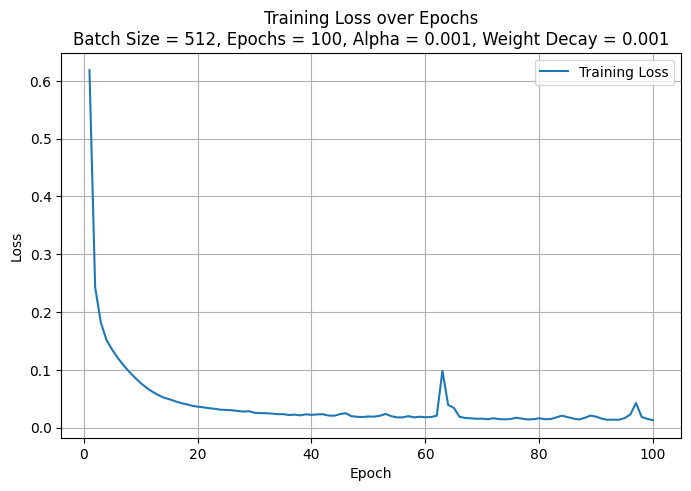

Train loss 0.0127 | Valid loss 0.6177
Valid ROC AUC: 0.941
              precision    recall  f1-score   support

           0      0.991     0.870     0.926     13892
           1      0.429     0.923     0.586      1475

    accuracy                          0.875     15367
   macro avg      0.710     0.896     0.756     15367
weighted avg      0.937     0.875     0.894     15367

[[12081  1811]
 [  114  1361]]


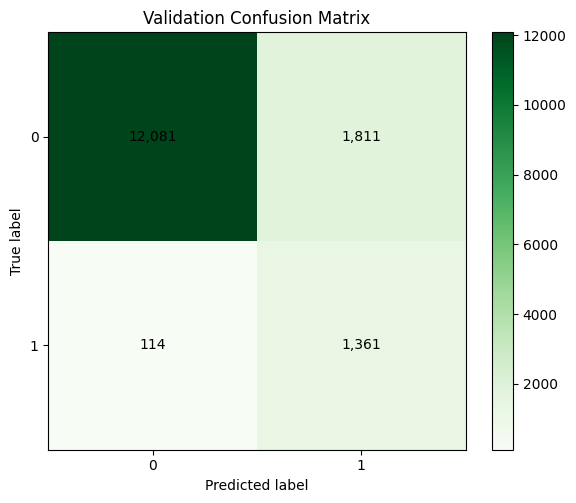

Iteration elapsed: 63.07s
 ==========     ==========     ==========     ==========
ITERATION [8/96]: 10:10:05 PM
    Batch Size:   512
    Epochs:       150
    α:            0.01
    Weight Decay: 0.01
    
Epoch 1/150, Loss: 1.5839 | 0.011s
Epoch 2/150, Loss: 0.3193 | 0.002s
Epoch 3/150, Loss: 0.1844 | 0.002s
Epoch 4/150, Loss: 0.1560 | 0.003s
Epoch 5/150, Loss: 0.2878 | 0.010s
Epoch 6/150, Loss: 0.1211 | 0.002s
Epoch 7/150, Loss: 0.1780 | 0.002s
Epoch 8/150, Loss: 0.4968 | 0.010s
Epoch 9/150, Loss: 0.1523 | 0.002s
Epoch 10/150, Loss: 0.1384 | 0.002s
Epoch 11/150, Loss: 0.1041 | 0.002s
Epoch 12/150, Loss: 0.1678 | 0.002s
Epoch 13/150, Loss: 0.1464 | 0.005s
Epoch 14/150, Loss: 0.1100 | 0.009s
Epoch 15/150, Loss: 0.1353 | 0.002s
Epoch 16/150, Loss: 0.1357 | 0.002s
Epoch 17/150, Loss: 0.0953 | 0.002s
Epoch 18/150, Loss: 0.1455 | 0.004s
Epoch 19/150, Loss: 0.1119 | 0.003s
Epoch 20/150, Loss: 0.1767 | 0.003s
Epoch 21/150, Loss: 0.1451 | 0.001s
Epoch 22/150, Loss: 0.0878 | 0.001s
Epoch 23/

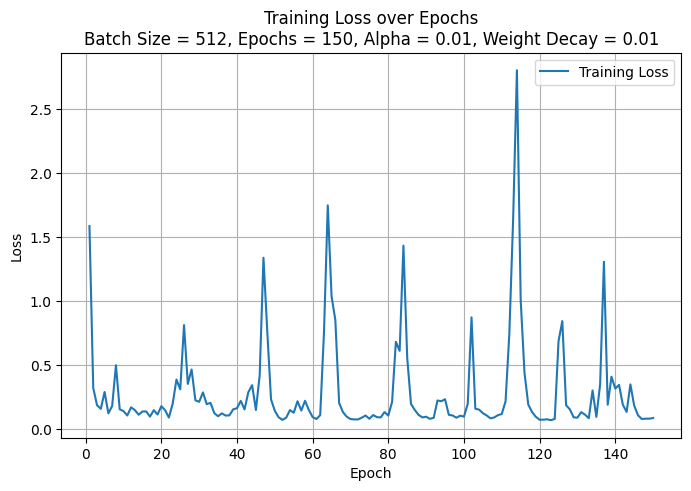

Train loss 0.0928 | Valid loss 0.4522
Valid ROC AUC: 0.969
              precision    recall  f1-score   support

           0      0.995     0.801     0.888     13892
           1      0.340     0.965     0.503      1475

    accuracy                          0.817     15367
   macro avg      0.668     0.883     0.695     15367
weighted avg      0.932     0.817     0.851     15367

[[11128  2764]
 [   52  1423]]


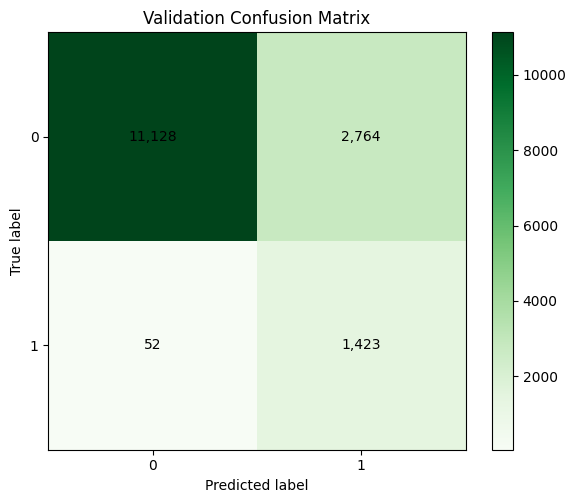

Iteration elapsed: 96.65s
 ==========     ==========     ==========     ==========
ITERATION [9/96]: 10:11:42 PM
    Batch Size:   512
    Epochs:       150
    α:            0.01
    Weight Decay: 0.001
    
Epoch 1/150, Loss: 1.8649 | 0.003s
Epoch 2/150, Loss: 0.4757 | 0.002s
Epoch 3/150, Loss: 0.2835 | 0.004s
Epoch 4/150, Loss: 0.1756 | 0.002s
Epoch 5/150, Loss: 0.1860 | 0.003s
Epoch 6/150, Loss: 0.1682 | 0.002s
Epoch 7/150, Loss: 0.1235 | 0.003s
Epoch 8/150, Loss: 0.0560 | 0.001s
Epoch 9/150, Loss: 0.0515 | 0.008s
Epoch 10/150, Loss: 0.0467 | 0.005s
Epoch 11/150, Loss: 0.0422 | 0.003s
Epoch 12/150, Loss: 0.0412 | 0.002s
Epoch 13/150, Loss: 0.0407 | 0.002s
Epoch 14/150, Loss: 0.0417 | 0.002s
Epoch 15/150, Loss: 0.0371 | 0.002s
Epoch 16/150, Loss: 0.0438 | 0.004s
Epoch 17/150, Loss: 0.0691 | 0.002s
Epoch 18/150, Loss: 0.2903 | 0.001s
Epoch 19/150, Loss: 2.2134 | 0.002s
Epoch 20/150, Loss: 1.4942 | 0.002s
Epoch 21/150, Loss: 0.4507 | 0.002s
Epoch 22/150, Loss: 0.3806 | 0.002s
Epoch 23

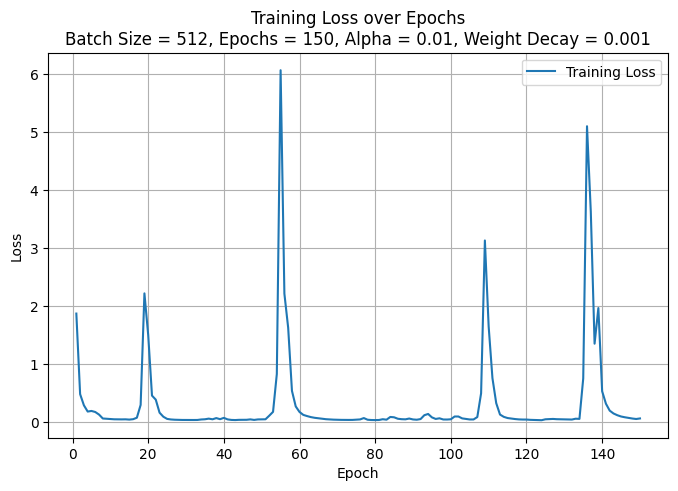

Train loss 0.0307 | Valid loss 1.0727
Valid ROC AUC: 0.973
              precision    recall  f1-score   support

           0      0.997     0.863     0.925     13892
           1      0.430     0.972     0.596      1475

    accuracy                          0.874     15367
   macro avg      0.713     0.917     0.761     15367
weighted avg      0.942     0.874     0.893     15367

[[11991  1901]
 [   42  1433]]


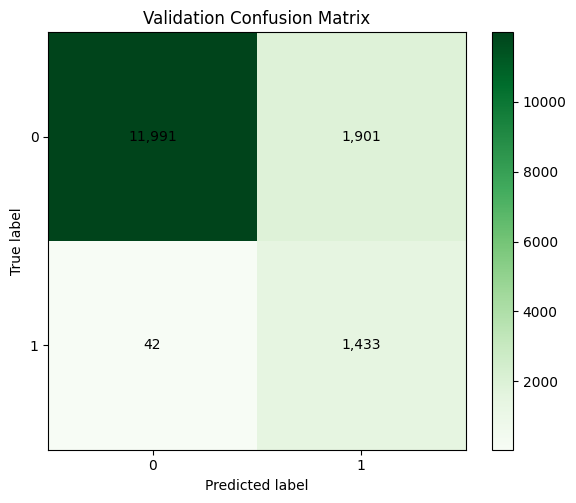

Iteration elapsed: 92.67s
 ==========     ==========     ==========     ==========
ITERATION [10/96]: 10:13:15 PM
    Batch Size:   512
    Epochs:       150
    α:            0.001
    Weight Decay: 0.01
    
Epoch 1/150, Loss: 0.6153 | 0.002s
Epoch 2/150, Loss: 0.2552 | 0.001s
Epoch 3/150, Loss: 0.1877 | 0.002s
Epoch 4/150, Loss: 0.1580 | 0.009s
Epoch 5/150, Loss: 0.1421 | 0.002s
Epoch 6/150, Loss: 0.1279 | 0.002s
Epoch 7/150, Loss: 0.1158 | 0.002s
Epoch 8/150, Loss: 0.1061 | 0.004s
Epoch 9/150, Loss: 0.0967 | 0.002s
Epoch 10/150, Loss: 0.0887 | 0.002s
Epoch 11/150, Loss: 0.0814 | 0.002s
Epoch 12/150, Loss: 0.0758 | 0.001s
Epoch 13/150, Loss: 0.0705 | 0.004s
Epoch 14/150, Loss: 0.0675 | 0.002s
Epoch 15/150, Loss: 0.0641 | 0.003s
Epoch 16/150, Loss: 0.0614 | 0.003s
Epoch 17/150, Loss: 0.0601 | 0.003s
Epoch 18/150, Loss: 0.0580 | 0.002s
Epoch 19/150, Loss: 0.0561 | 0.002s
Epoch 20/150, Loss: 0.0567 | 0.003s
Epoch 21/150, Loss: 0.0539 | 0.011s
Epoch 22/150, Loss: 0.0543 | 0.002s
Epoch 2

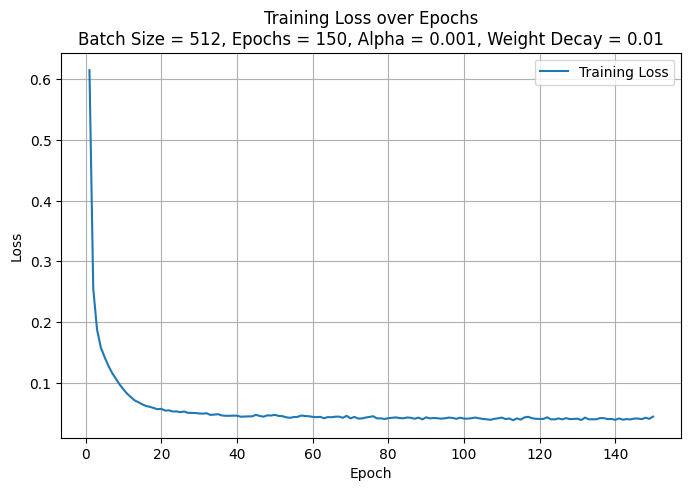

Train loss 0.0388 | Valid loss 0.3803
Valid ROC AUC: 0.947
              precision    recall  f1-score   support

           0      0.989     0.861     0.921     13892
           1      0.411     0.911     0.566      1475

    accuracy                          0.866     15367
   macro avg      0.700     0.886     0.744     15367
weighted avg      0.934     0.866     0.887     15367

[[11965  1927]
 [  131  1344]]


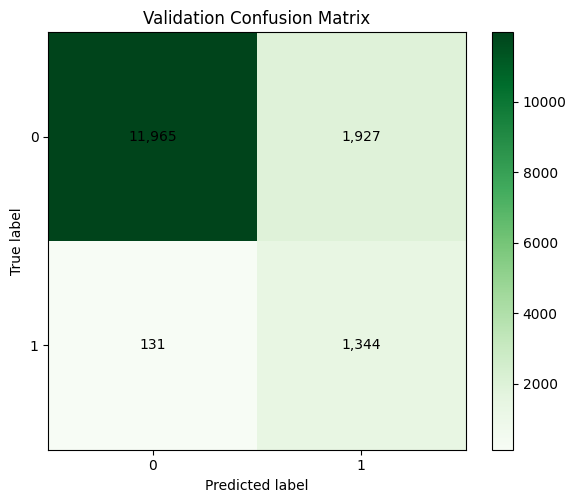

Iteration elapsed: 93.55s
 ==========     ==========     ==========     ==========
ITERATION [11/96]: 10:14:48 PM
    Batch Size:   512
    Epochs:       150
    α:            0.001
    Weight Decay: 0.001
    
Epoch 1/150, Loss: 0.6183 | 0.007s
Epoch 2/150, Loss: 0.2429 | 0.005s
Epoch 3/150, Loss: 0.1817 | 0.003s
Epoch 4/150, Loss: 0.1513 | 0.002s
Epoch 5/150, Loss: 0.1346 | 0.003s
Epoch 6/150, Loss: 0.1202 | 0.002s
Epoch 7/150, Loss: 0.1077 | 0.002s
Epoch 8/150, Loss: 0.0963 | 0.002s
Epoch 9/150, Loss: 0.0863 | 0.002s
Epoch 10/150, Loss: 0.0771 | 0.002s
Epoch 11/150, Loss: 0.0691 | 0.002s
Epoch 12/150, Loss: 0.0624 | 0.004s
Epoch 13/150, Loss: 0.0567 | 0.002s
Epoch 14/150, Loss: 0.0520 | 0.002s
Epoch 15/150, Loss: 0.0491 | 0.002s
Epoch 16/150, Loss: 0.0456 | 0.002s
Epoch 17/150, Loss: 0.0427 | 0.001s
Epoch 18/150, Loss: 0.0404 | 0.003s
Epoch 19/150, Loss: 0.0379 | 0.003s
Epoch 20/150, Loss: 0.0361 | 0.008s
Epoch 21/150, Loss: 0.0351 | 0.002s
Epoch 22/150, Loss: 0.0336 | 0.004s
Epoch 

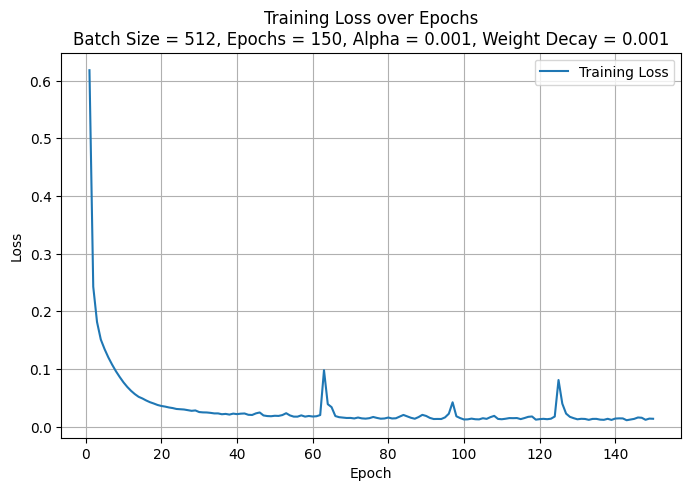

Train loss 0.0146 | Valid loss 0.6230
Valid ROC AUC: 0.919
              precision    recall  f1-score   support

           0      0.972     0.873     0.920     13892
           1      0.389     0.765     0.516      1475

    accuracy                          0.862     15367
   macro avg      0.681     0.819     0.718     15367
weighted avg      0.916     0.862     0.881     15367

[[12121  1771]
 [  347  1128]]


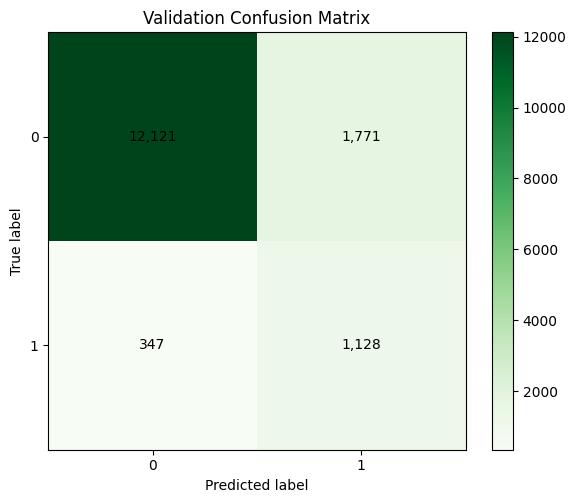

Iteration elapsed: 96.53s
 ==========     ==========     ==========     ==========
ITERATION [12/96]: 10:16:25 PM
    Batch Size:   512
    Epochs:       200
    α:            0.01
    Weight Decay: 0.01
    
Epoch 1/200, Loss: 1.5839 | 0.001s
Epoch 2/200, Loss: 0.3193 | 0.002s
Epoch 3/200, Loss: 0.1844 | 0.004s
Epoch 4/200, Loss: 0.1560 | 0.001s
Epoch 5/200, Loss: 0.2878 | 0.009s
Epoch 6/200, Loss: 0.1211 | 0.002s
Epoch 7/200, Loss: 0.1780 | 0.002s
Epoch 8/200, Loss: 0.4968 | 0.005s
Epoch 9/200, Loss: 0.1523 | 0.001s
Epoch 10/200, Loss: 0.1384 | 0.003s
Epoch 11/200, Loss: 0.1041 | 0.002s
Epoch 12/200, Loss: 0.1678 | 0.002s
Epoch 13/200, Loss: 0.1464 | 0.001s
Epoch 14/200, Loss: 0.1100 | 0.003s
Epoch 15/200, Loss: 0.1353 | 0.010s
Epoch 16/200, Loss: 0.1357 | 0.002s
Epoch 17/200, Loss: 0.0953 | 0.002s
Epoch 18/200, Loss: 0.1455 | 0.002s
Epoch 19/200, Loss: 0.1119 | 0.002s
Epoch 20/200, Loss: 0.1767 | 0.002s
Epoch 21/200, Loss: 0.1451 | 0.003s
Epoch 22/200, Loss: 0.0878 | 0.001s
Epoch 23

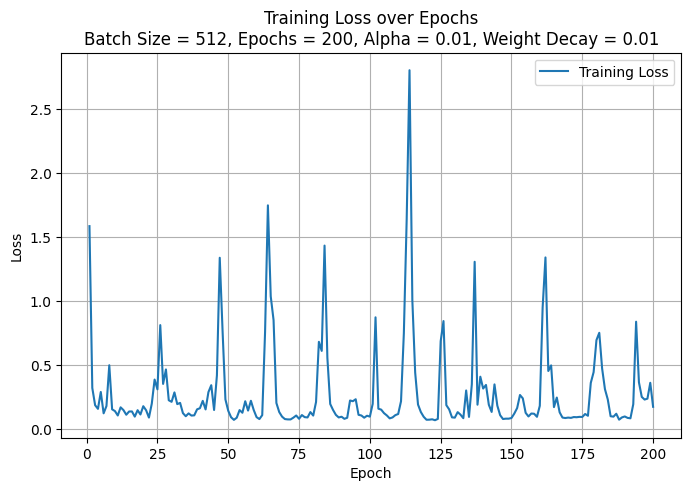

Train loss 0.1032 | Valid loss 0.9098
Valid ROC AUC: 0.881
              precision    recall  f1-score   support

           0      0.986     0.765     0.862     13892
           1      0.289     0.899     0.437      1475

    accuracy                          0.778     15367
   macro avg      0.638     0.832     0.650     15367
weighted avg      0.919     0.778     0.821     15367

[[10631  3261]
 [  149  1326]]


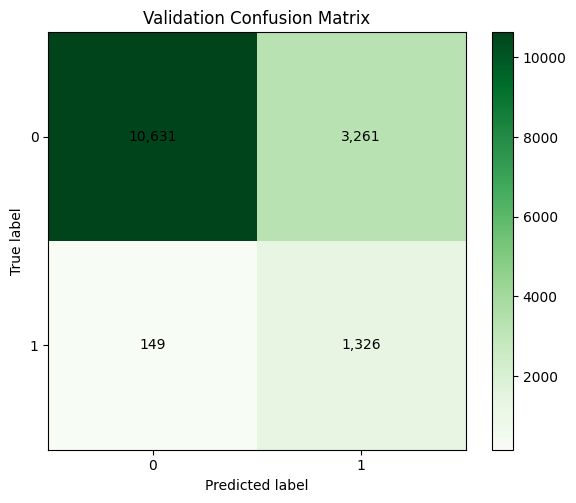

Iteration elapsed: 123.72s
 ==========     ==========     ==========     ==========
ITERATION [13/96]: 10:18:29 PM
    Batch Size:   512
    Epochs:       200
    α:            0.01
    Weight Decay: 0.001
    
Epoch 1/200, Loss: 1.8649 | 0.003s
Epoch 2/200, Loss: 0.4757 | 0.007s
Epoch 3/200, Loss: 0.2835 | 0.004s
Epoch 4/200, Loss: 0.1756 | 0.002s
Epoch 5/200, Loss: 0.1860 | 0.002s
Epoch 6/200, Loss: 0.1682 | 0.002s
Epoch 7/200, Loss: 0.1235 | 0.002s
Epoch 8/200, Loss: 0.0560 | 0.006s
Epoch 9/200, Loss: 0.0515 | 0.004s
Epoch 10/200, Loss: 0.0467 | 0.002s
Epoch 11/200, Loss: 0.0422 | 0.003s
Epoch 12/200, Loss: 0.0412 | 0.004s
Epoch 13/200, Loss: 0.0407 | 0.002s
Epoch 14/200, Loss: 0.0417 | 0.002s
Epoch 15/200, Loss: 0.0371 | 0.003s
Epoch 16/200, Loss: 0.0438 | 0.003s
Epoch 17/200, Loss: 0.0691 | 0.008s
Epoch 18/200, Loss: 0.2903 | 0.003s
Epoch 19/200, Loss: 2.2134 | 0.004s
Epoch 20/200, Loss: 1.4942 | 0.002s
Epoch 21/200, Loss: 0.4507 | 0.001s
Epoch 22/200, Loss: 0.3806 | 0.009s
Epoch 

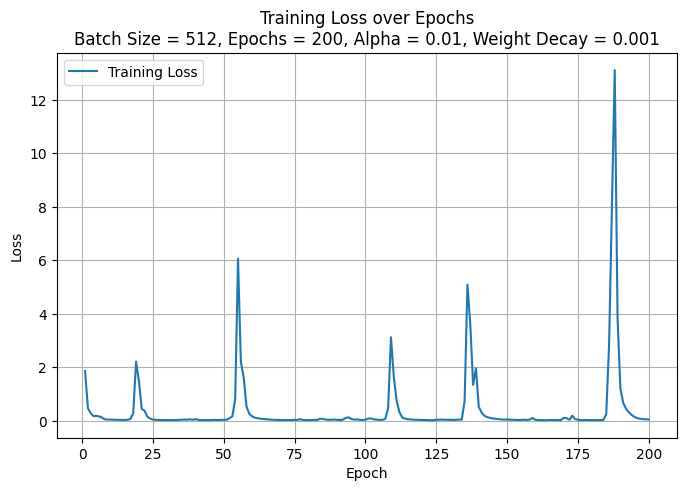

Train loss 0.0482 | Valid loss 2.0736
Valid ROC AUC: 0.932
              precision    recall  f1-score   support

           0      0.996     0.855     0.920     13892
           1      0.415     0.971     0.582      1475

    accuracy                          0.866     15367
   macro avg      0.706     0.913     0.751     15367
weighted avg      0.941     0.866     0.888     15367

[[11877  2015]
 [   43  1432]]


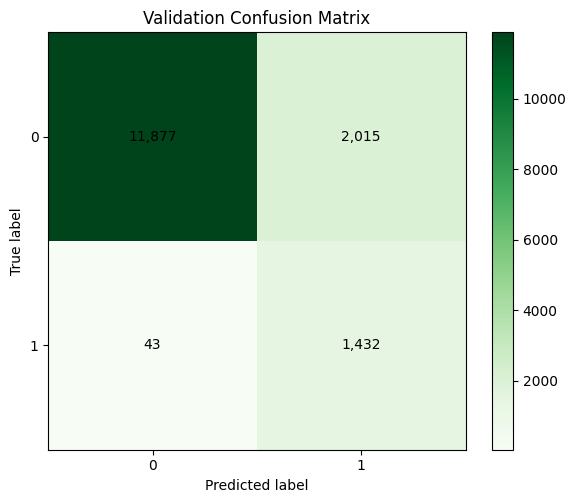

Iteration elapsed: 115.61s
 ==========     ==========     ==========     ==========
ITERATION [14/96]: 10:20:25 PM
    Batch Size:   512
    Epochs:       200
    α:            0.001
    Weight Decay: 0.01
    
Epoch 1/200, Loss: 0.6153 | 0.003s
Epoch 2/200, Loss: 0.2552 | 0.003s
Epoch 3/200, Loss: 0.1877 | 0.003s
Epoch 4/200, Loss: 0.1580 | 0.003s
Epoch 5/200, Loss: 0.1421 | 0.002s
Epoch 6/200, Loss: 0.1279 | 0.001s
Epoch 7/200, Loss: 0.1158 | 0.009s
Epoch 8/200, Loss: 0.1061 | 0.003s
Epoch 9/200, Loss: 0.0967 | 0.004s
Epoch 10/200, Loss: 0.0887 | 0.002s
Epoch 11/200, Loss: 0.0814 | 0.002s
Epoch 12/200, Loss: 0.0758 | 0.002s
Epoch 13/200, Loss: 0.0705 | 0.005s
Epoch 14/200, Loss: 0.0675 | 0.002s
Epoch 15/200, Loss: 0.0641 | 0.001s
Epoch 16/200, Loss: 0.0614 | 0.010s
Epoch 17/200, Loss: 0.0601 | 0.001s
Epoch 18/200, Loss: 0.0580 | 0.003s
Epoch 19/200, Loss: 0.0561 | 0.001s
Epoch 20/200, Loss: 0.0567 | 0.003s
Epoch 21/200, Loss: 0.0539 | 0.002s
Epoch 22/200, Loss: 0.0543 | 0.003s
Epoch 

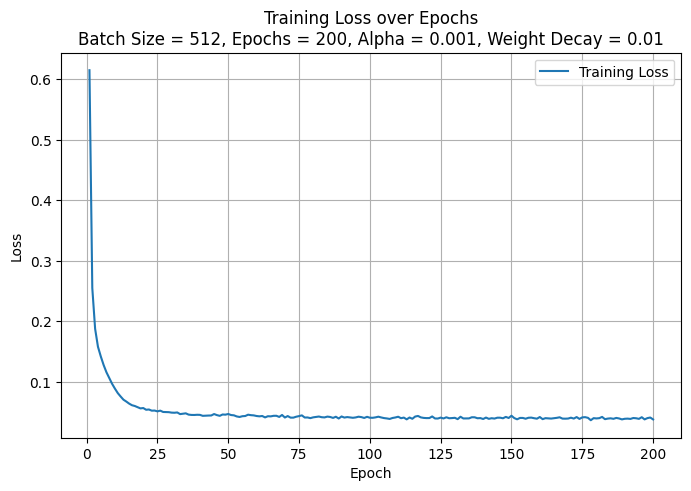

Train loss 0.0329 | Valid loss 0.3623
Valid ROC AUC: 0.947
              precision    recall  f1-score   support

           0      0.990     0.880     0.932     13892
           1      0.448     0.916     0.602      1475

    accuracy                          0.884     15367
   macro avg      0.719     0.898     0.767     15367
weighted avg      0.938     0.884     0.900     15367

[[12228  1664]
 [  124  1351]]


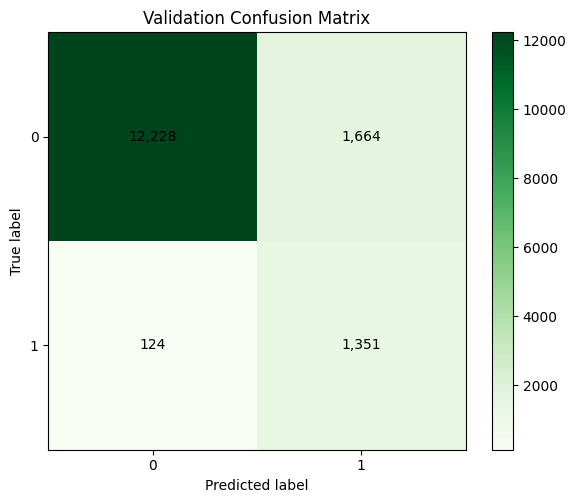

Iteration elapsed: 114.70s
 ==========     ==========     ==========     ==========
ITERATION [15/96]: 10:22:20 PM
    Batch Size:   512
    Epochs:       200
    α:            0.001
    Weight Decay: 0.001
    
Epoch 1/200, Loss: 0.6183 | 0.002s
Epoch 2/200, Loss: 0.2429 | 0.003s
Epoch 3/200, Loss: 0.1817 | 0.002s
Epoch 4/200, Loss: 0.1513 | 0.002s
Epoch 5/200, Loss: 0.1346 | 0.002s
Epoch 6/200, Loss: 0.1202 | 0.002s
Epoch 7/200, Loss: 0.1077 | 0.005s
Epoch 8/200, Loss: 0.0963 | 0.006s
Epoch 9/200, Loss: 0.0863 | 0.002s
Epoch 10/200, Loss: 0.0771 | 0.003s
Epoch 11/200, Loss: 0.0691 | 0.007s
Epoch 12/200, Loss: 0.0624 | 0.003s
Epoch 13/200, Loss: 0.0567 | 0.001s
Epoch 14/200, Loss: 0.0520 | 0.002s
Epoch 15/200, Loss: 0.0491 | 0.001s
Epoch 16/200, Loss: 0.0456 | 0.002s
Epoch 17/200, Loss: 0.0427 | 0.003s
Epoch 18/200, Loss: 0.0404 | 0.002s
Epoch 19/200, Loss: 0.0379 | 0.002s
Epoch 20/200, Loss: 0.0361 | 0.002s
Epoch 21/200, Loss: 0.0351 | 0.003s
Epoch 22/200, Loss: 0.0336 | 0.001s
Epoch

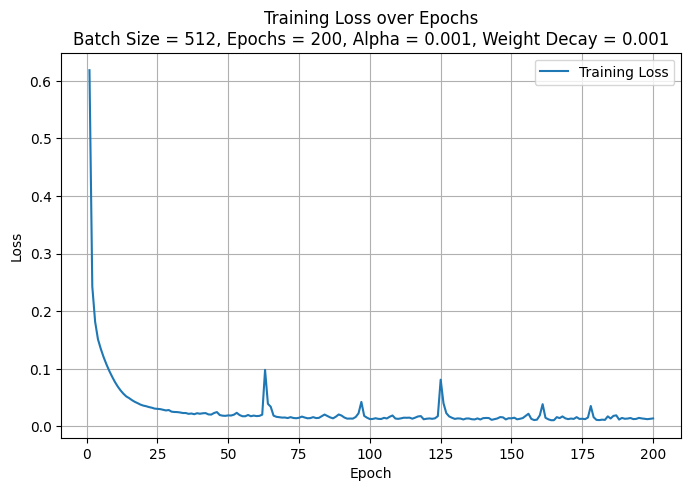

Train loss 0.0109 | Valid loss 0.6427
Valid ROC AUC: 0.920
              precision    recall  f1-score   support

           0      0.970     0.873     0.919     13892
           1      0.385     0.748     0.508      1475

    accuracy                          0.861     15367
   macro avg      0.678     0.810     0.714     15367
weighted avg      0.914     0.861     0.880     15367

[[12129  1763]
 [  372  1103]]


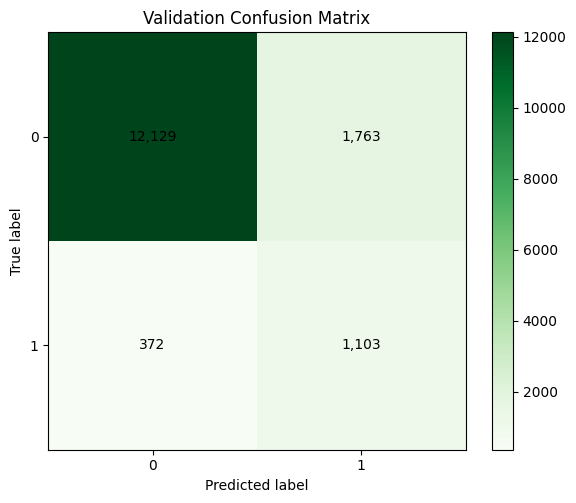

Iteration elapsed: 115.34s
 ==========     ==========     ==========     ==========
ITERATION [16/96]: 10:24:15 PM
    Batch Size:   1024
    Epochs:       50
    α:            0.01
    Weight Decay: 0.01
    
Epoch 1/50, Loss: 2.2052 | 0.003s
Epoch 2/50, Loss: 0.9369 | 0.003s
Epoch 3/50, Loss: 0.2511 | 0.011s
Epoch 4/50, Loss: 0.1521 | 0.003s
Epoch 5/50, Loss: 0.1309 | 0.002s
Epoch 6/50, Loss: 0.1177 | 0.002s
Epoch 7/50, Loss: 0.1089 | 0.002s
Epoch 8/50, Loss: 0.1050 | 0.006s
Epoch 9/50, Loss: 0.1109 | 0.005s
Epoch 10/50, Loss: 0.1047 | 0.002s
Epoch 11/50, Loss: 0.1167 | 0.002s
Epoch 12/50, Loss: 0.1011 | 0.002s
Epoch 13/50, Loss: 0.1001 | 0.007s
Epoch 14/50, Loss: 0.0900 | 0.006s
Epoch 15/50, Loss: 0.1014 | 0.003s
Epoch 16/50, Loss: 0.1172 | 0.005s
Epoch 17/50, Loss: 0.4379 | 0.002s
Epoch 18/50, Loss: 0.3083 | 0.002s
Epoch 19/50, Loss: 0.1636 | 0.004s
Epoch 20/50, Loss: 0.0975 | 0.003s
Epoch 21/50, Loss: 0.0769 | 0.007s
Epoch 22/50, Loss: 0.0937 | 0.005s
Epoch 23/50, Loss: 0.0803 | 0

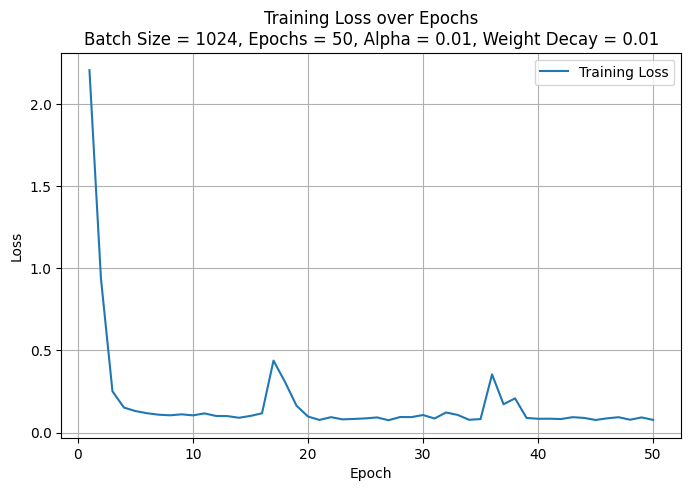

Train loss 0.0899 | Valid loss 0.5678
Valid ROC AUC: 0.849
              precision    recall  f1-score   support

           0      0.961     0.789     0.866     13892
           1      0.260     0.697     0.378      1475

    accuracy                          0.780     15367
   macro avg      0.610     0.743     0.622     15367
weighted avg      0.894     0.780     0.820     15367

[[10961  2931]
 [  447  1028]]


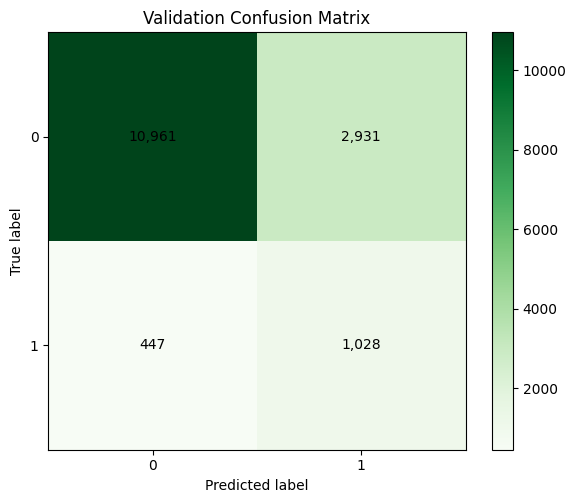

Iteration elapsed: 24.69s
 ==========     ==========     ==========     ==========
ITERATION [17/96]: 10:24:40 PM
    Batch Size:   1024
    Epochs:       50
    α:            0.01
    Weight Decay: 0.001
    
Epoch 1/50, Loss: 2.1266 | 0.005s
Epoch 2/50, Loss: 1.5272 | 0.011s
Epoch 3/50, Loss: 0.2009 | 0.004s
Epoch 4/50, Loss: 0.1151 | 0.002s
Epoch 5/50, Loss: 0.0998 | 0.002s
Epoch 6/50, Loss: 0.0865 | 0.002s
Epoch 7/50, Loss: 0.0800 | 0.003s
Epoch 8/50, Loss: 0.0728 | 0.008s
Epoch 9/50, Loss: 0.0681 | 0.005s
Epoch 10/50, Loss: 0.0628 | 0.002s
Epoch 11/50, Loss: 0.0592 | 0.003s
Epoch 12/50, Loss: 0.0552 | 0.002s
Epoch 13/50, Loss: 0.0530 | 0.010s
Epoch 14/50, Loss: 0.0500 | 0.002s
Epoch 15/50, Loss: 0.0495 | 0.002s
Epoch 16/50, Loss: 0.0469 | 0.002s
Epoch 17/50, Loss: 0.0455 | 0.002s
Epoch 18/50, Loss: 0.0446 | 0.003s
Epoch 19/50, Loss: 0.0414 | 0.002s
Epoch 20/50, Loss: 0.0379 | 0.005s
Epoch 21/50, Loss: 0.0587 | 0.005s
Epoch 22/50, Loss: 0.0631 | 0.002s
Epoch 23/50, Loss: 0.0718 | 0

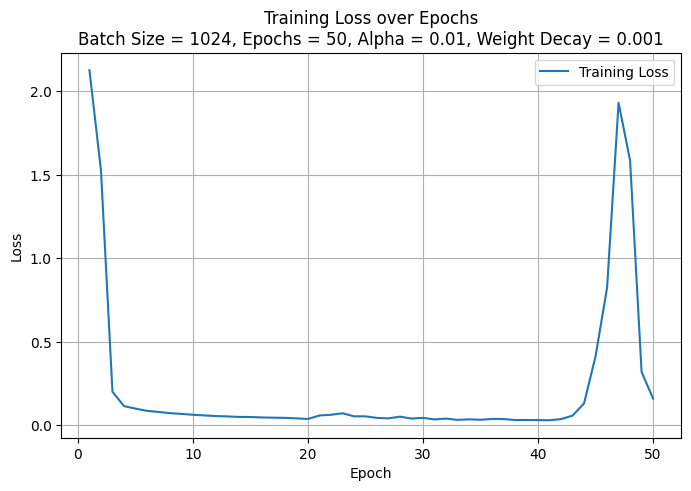

Train loss 0.1087 | Valid loss 2.6375
Valid ROC AUC: 0.920
              precision    recall  f1-score   support

           0      0.991     0.752     0.855     13892
           1      0.286     0.934     0.438      1475

    accuracy                          0.770     15367
   macro avg      0.638     0.843     0.646     15367
weighted avg      0.923     0.770     0.815     15367

[[10447  3445]
 [   97  1378]]


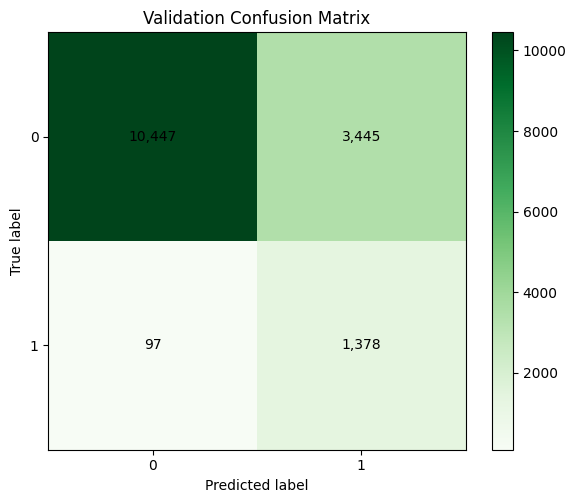

Iteration elapsed: 25.08s
 ==========     ==========     ==========     ==========
ITERATION [18/96]: 10:25:06 PM
    Batch Size:   1024
    Epochs:       50
    α:            0.001
    Weight Decay: 0.01
    
Epoch 1/50, Loss: 0.6376 | 0.003s
Epoch 2/50, Loss: 0.2935 | 0.006s
Epoch 3/50, Loss: 0.2325 | 0.002s
Epoch 4/50, Loss: 0.1930 | 0.004s
Epoch 5/50, Loss: 0.1694 | 0.004s
Epoch 6/50, Loss: 0.1528 | 0.003s
Epoch 7/50, Loss: 0.1401 | 0.002s
Epoch 8/50, Loss: 0.1295 | 0.004s
Epoch 9/50, Loss: 0.1206 | 0.006s
Epoch 10/50, Loss: 0.1122 | 0.012s
Epoch 11/50, Loss: 0.1059 | 0.002s
Epoch 12/50, Loss: 0.0986 | 0.003s
Epoch 13/50, Loss: 0.0940 | 0.002s
Epoch 14/50, Loss: 0.0878 | 0.003s
Epoch 15/50, Loss: 0.0842 | 0.002s
Epoch 16/50, Loss: 0.0791 | 0.002s
Epoch 17/50, Loss: 0.0762 | 0.002s
Epoch 18/50, Loss: 0.0725 | 0.003s
Epoch 19/50, Loss: 0.0702 | 0.005s
Epoch 20/50, Loss: 0.0666 | 0.003s
Epoch 21/50, Loss: 0.0653 | 0.004s
Epoch 22/50, Loss: 0.0620 | 0.008s
Epoch 23/50, Loss: 0.0604 | 0

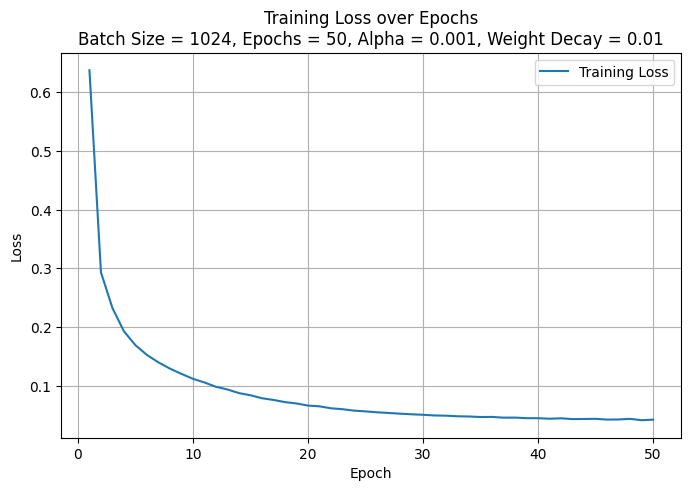

Train loss 0.0357 | Valid loss 0.3500
Valid ROC AUC: 0.952
              precision    recall  f1-score   support

           0      0.993     0.880     0.933     13892
           1      0.454     0.939     0.612      1475

    accuracy                          0.886     15367
   macro avg      0.723     0.909     0.772     15367
weighted avg      0.941     0.886     0.902     15367

[[12223  1669]
 [   90  1385]]


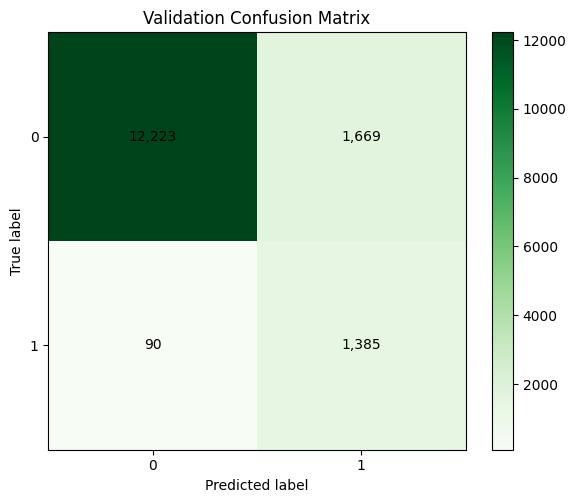

Iteration elapsed: 24.42s
 ==========     ==========     ==========     ==========
ITERATION [19/96]: 10:25:30 PM
    Batch Size:   1024
    Epochs:       50
    α:            0.001
    Weight Decay: 0.001
    
Epoch 1/50, Loss: 0.6346 | 0.003s
Epoch 2/50, Loss: 0.2883 | 0.002s
Epoch 3/50, Loss: 0.2271 | 0.010s
Epoch 4/50, Loss: 0.1880 | 0.003s
Epoch 5/50, Loss: 0.1633 | 0.002s
Epoch 6/50, Loss: 0.1456 | 0.002s
Epoch 7/50, Loss: 0.1316 | 0.002s
Epoch 8/50, Loss: 0.1197 | 0.002s
Epoch 9/50, Loss: 0.1093 | 0.002s
Epoch 10/50, Loss: 0.1002 | 0.006s
Epoch 11/50, Loss: 0.0920 | 0.003s
Epoch 12/50, Loss: 0.0849 | 0.004s
Epoch 13/50, Loss: 0.0785 | 0.002s
Epoch 14/50, Loss: 0.0728 | 0.002s
Epoch 15/50, Loss: 0.0676 | 0.002s
Epoch 16/50, Loss: 0.0629 | 0.003s
Epoch 17/50, Loss: 0.0587 | 0.006s
Epoch 18/50, Loss: 0.0549 | 0.003s
Epoch 19/50, Loss: 0.0514 | 0.008s
Epoch 20/50, Loss: 0.0486 | 0.007s
Epoch 21/50, Loss: 0.0459 | 0.009s
Epoch 22/50, Loss: 0.0434 | 0.006s
Epoch 23/50, Loss: 0.0416 | 

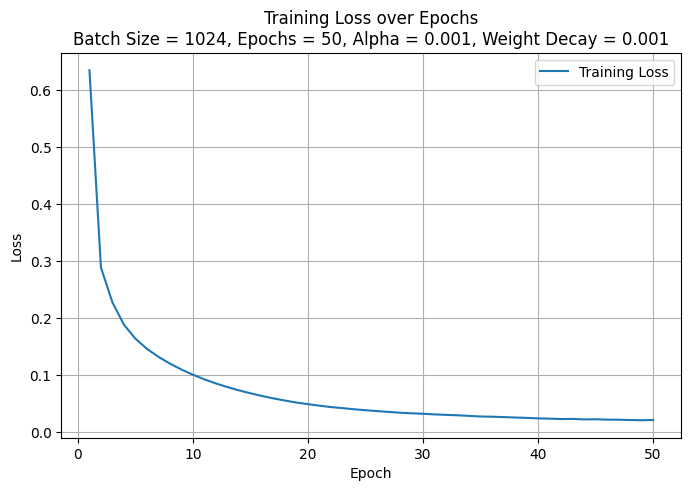

Train loss 0.0154 | Valid loss 0.4604
Valid ROC AUC: 0.955
              precision    recall  f1-score   support

           0      0.994     0.879     0.933     13892
           1      0.456     0.954     0.617      1475

    accuracy                          0.886     15367
   macro avg      0.725     0.916     0.775     15367
weighted avg      0.943     0.886     0.903     15367

[[12212  1680]
 [   68  1407]]


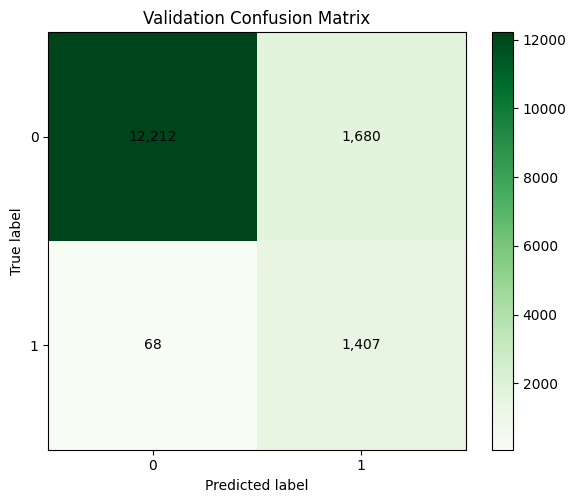

Iteration elapsed: 25.20s
 ==========     ==========     ==========     ==========
ITERATION [20/96]: 10:25:56 PM
    Batch Size:   1024
    Epochs:       100
    α:            0.01
    Weight Decay: 0.01
    
Epoch 1/100, Loss: 2.2052 | 0.004s
Epoch 2/100, Loss: 0.9369 | 0.004s
Epoch 3/100, Loss: 0.2511 | 0.002s
Epoch 4/100, Loss: 0.1521 | 0.002s
Epoch 5/100, Loss: 0.1309 | 0.002s
Epoch 6/100, Loss: 0.1177 | 0.002s
Epoch 7/100, Loss: 0.1089 | 0.005s
Epoch 8/100, Loss: 0.1050 | 0.003s
Epoch 9/100, Loss: 0.1109 | 0.002s
Epoch 10/100, Loss: 0.1047 | 0.002s
Epoch 11/100, Loss: 0.1167 | 0.002s
Epoch 12/100, Loss: 0.1011 | 0.002s
Epoch 13/100, Loss: 0.1001 | 0.005s
Epoch 14/100, Loss: 0.0900 | 0.003s
Epoch 15/100, Loss: 0.1014 | 0.002s
Epoch 16/100, Loss: 0.1172 | 0.002s
Epoch 17/100, Loss: 0.4379 | 0.002s
Epoch 18/100, Loss: 0.3083 | 0.002s
Epoch 19/100, Loss: 0.1636 | 0.006s
Epoch 20/100, Loss: 0.0975 | 0.004s
Epoch 21/100, Loss: 0.0769 | 0.002s
Epoch 22/100, Loss: 0.0937 | 0.003s
Epoch 2

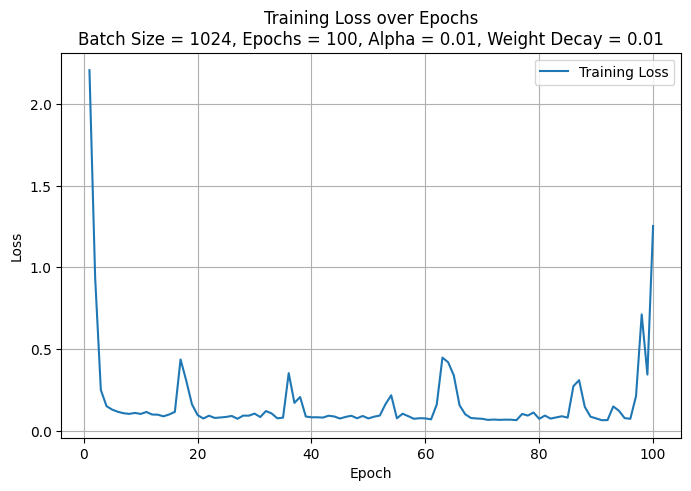

Train loss 0.8539 | Valid loss 5.8960
Valid ROC AUC: 0.787
              precision    recall  f1-score   support

           0      0.971     0.472     0.636     13892
           1      0.149     0.867     0.254      1475

    accuracy                          0.510     15367
   macro avg      0.560     0.670     0.445     15367
weighted avg      0.892     0.510     0.599     15367

[[6562 7330]
 [ 196 1279]]


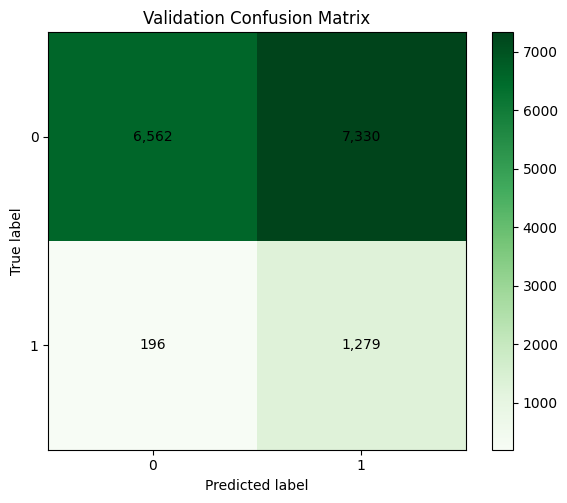

Iteration elapsed: 48.18s
 ==========     ==========     ==========     ==========
ITERATION [21/96]: 10:26:44 PM
    Batch Size:   1024
    Epochs:       100
    α:            0.01
    Weight Decay: 0.001
    
Epoch 1/100, Loss: 2.1266 | 0.010s
Epoch 2/100, Loss: 1.5272 | 0.003s
Epoch 3/100, Loss: 0.2009 | 0.002s
Epoch 4/100, Loss: 0.1151 | 0.002s
Epoch 5/100, Loss: 0.0998 | 0.002s
Epoch 6/100, Loss: 0.0865 | 0.002s
Epoch 7/100, Loss: 0.0800 | 0.006s
Epoch 8/100, Loss: 0.0728 | 0.002s
Epoch 9/100, Loss: 0.0681 | 0.004s
Epoch 10/100, Loss: 0.0628 | 0.002s
Epoch 11/100, Loss: 0.0592 | 0.002s
Epoch 12/100, Loss: 0.0552 | 0.007s
Epoch 13/100, Loss: 0.0530 | 0.003s
Epoch 14/100, Loss: 0.0500 | 0.002s
Epoch 15/100, Loss: 0.0495 | 0.005s
Epoch 16/100, Loss: 0.0469 | 0.002s
Epoch 17/100, Loss: 0.0455 | 0.003s
Epoch 18/100, Loss: 0.0446 | 0.002s
Epoch 19/100, Loss: 0.0414 | 0.010s
Epoch 20/100, Loss: 0.0379 | 0.005s
Epoch 21/100, Loss: 0.0587 | 0.002s
Epoch 22/100, Loss: 0.0631 | 0.002s
Epoch 

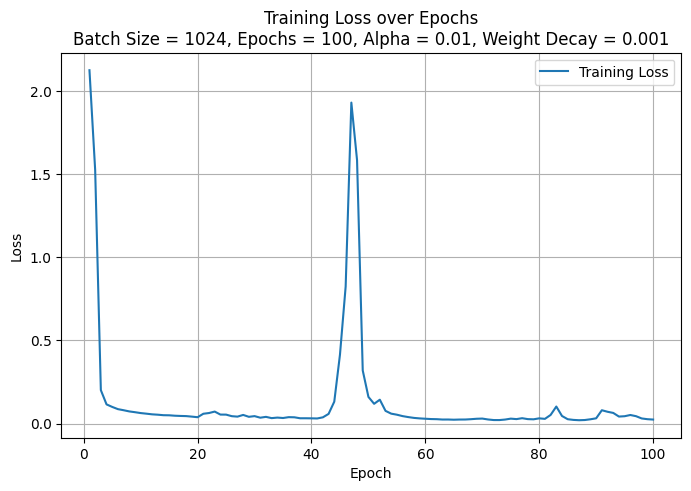

Train loss 0.0134 | Valid loss 0.4233
Valid ROC AUC: 0.955
              precision    recall  f1-score   support

           0      0.993     0.880     0.933     13892
           1      0.455     0.943     0.614      1475

    accuracy                          0.886     15367
   macro avg      0.724     0.912     0.774     15367
weighted avg      0.942     0.886     0.903     15367

[[12229  1663]
 [   84  1391]]


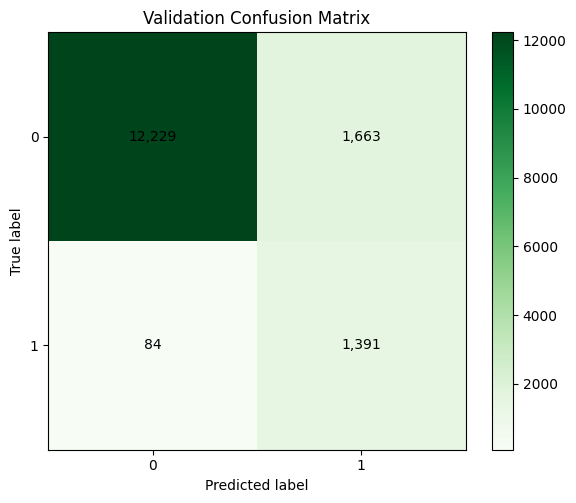

Iteration elapsed: 48.12s
 ==========     ==========     ==========     ==========
ITERATION [22/96]: 10:27:33 PM
    Batch Size:   1024
    Epochs:       100
    α:            0.001
    Weight Decay: 0.01
    
Epoch 1/100, Loss: 0.6376 | 0.005s
Epoch 2/100, Loss: 0.2935 | 0.003s
Epoch 3/100, Loss: 0.2325 | 0.006s
Epoch 4/100, Loss: 0.1930 | 0.007s
Epoch 5/100, Loss: 0.1694 | 0.003s
Epoch 6/100, Loss: 0.1528 | 0.002s
Epoch 7/100, Loss: 0.1401 | 0.002s
Epoch 8/100, Loss: 0.1295 | 0.002s
Epoch 9/100, Loss: 0.1206 | 0.006s
Epoch 10/100, Loss: 0.1122 | 0.002s
Epoch 11/100, Loss: 0.1059 | 0.002s
Epoch 12/100, Loss: 0.0986 | 0.011s
Epoch 13/100, Loss: 0.0940 | 0.003s
Epoch 14/100, Loss: 0.0878 | 0.003s
Epoch 15/100, Loss: 0.0842 | 0.002s
Epoch 16/100, Loss: 0.0791 | 0.003s
Epoch 17/100, Loss: 0.0762 | 0.007s
Epoch 18/100, Loss: 0.0725 | 0.002s
Epoch 19/100, Loss: 0.0702 | 0.004s
Epoch 20/100, Loss: 0.0666 | 0.004s
Epoch 21/100, Loss: 0.0653 | 0.002s
Epoch 22/100, Loss: 0.0620 | 0.002s
Epoch 

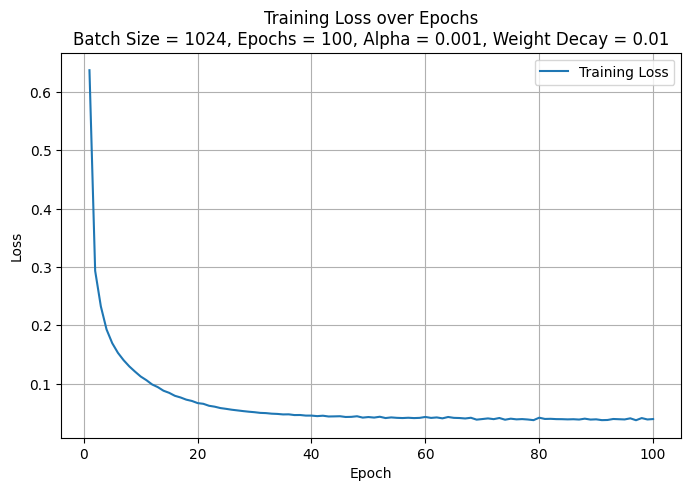

Train loss 0.0321 | Valid loss 0.3488
Valid ROC AUC: 0.952
              precision    recall  f1-score   support

           0      0.993     0.877     0.931     13892
           1      0.448     0.938     0.606      1475

    accuracy                          0.883     15367
   macro avg      0.720     0.908     0.769     15367
weighted avg      0.940     0.883     0.900     15367

[[12189  1703]
 [   92  1383]]


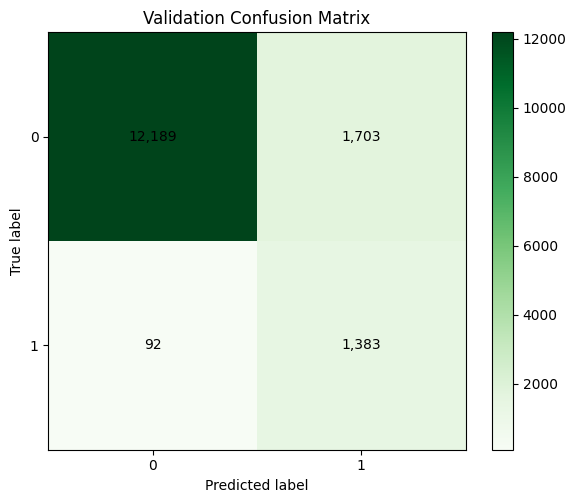

Iteration elapsed: 48.12s
 ==========     ==========     ==========     ==========
ITERATION [23/96]: 10:28:21 PM
    Batch Size:   1024
    Epochs:       100
    α:            0.001
    Weight Decay: 0.001
    
Epoch 1/100, Loss: 0.6346 | 0.002s
Epoch 2/100, Loss: 0.2883 | 0.004s
Epoch 3/100, Loss: 0.2271 | 0.002s
Epoch 4/100, Loss: 0.1880 | 0.002s
Epoch 5/100, Loss: 0.1633 | 0.003s
Epoch 6/100, Loss: 0.1456 | 0.002s
Epoch 7/100, Loss: 0.1316 | 0.003s
Epoch 8/100, Loss: 0.1197 | 0.007s
Epoch 9/100, Loss: 0.1093 | 0.003s
Epoch 10/100, Loss: 0.1002 | 0.002s
Epoch 11/100, Loss: 0.0920 | 0.003s
Epoch 12/100, Loss: 0.0849 | 0.002s
Epoch 13/100, Loss: 0.0785 | 0.002s
Epoch 14/100, Loss: 0.0728 | 0.002s
Epoch 15/100, Loss: 0.0676 | 0.011s
Epoch 16/100, Loss: 0.0629 | 0.002s
Epoch 17/100, Loss: 0.0587 | 0.003s
Epoch 18/100, Loss: 0.0549 | 0.002s
Epoch 19/100, Loss: 0.0514 | 0.002s
Epoch 20/100, Loss: 0.0486 | 0.004s
Epoch 21/100, Loss: 0.0459 | 0.003s
Epoch 22/100, Loss: 0.0434 | 0.002s
Epoch

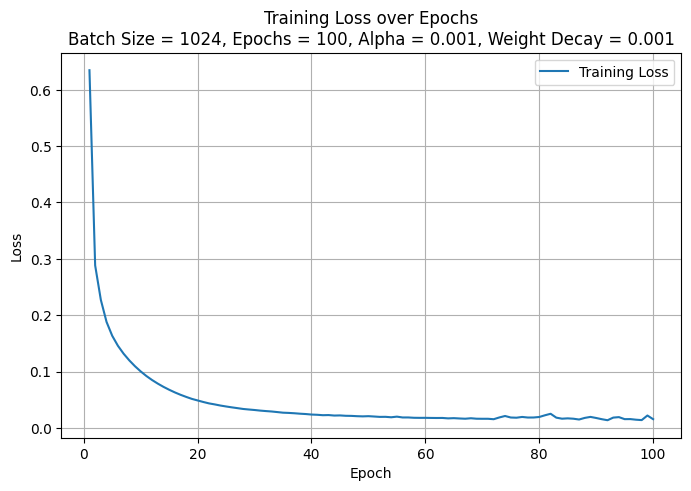

Train loss 0.0145 | Valid loss 0.5942
Valid ROC AUC: 0.946
              precision    recall  f1-score   support

           0      0.992     0.873     0.929     13892
           1      0.438     0.934     0.596      1475

    accuracy                          0.879     15367
   macro avg      0.715     0.903     0.762     15367
weighted avg      0.939     0.879     0.897     15367

[[12126  1766]
 [   98  1377]]


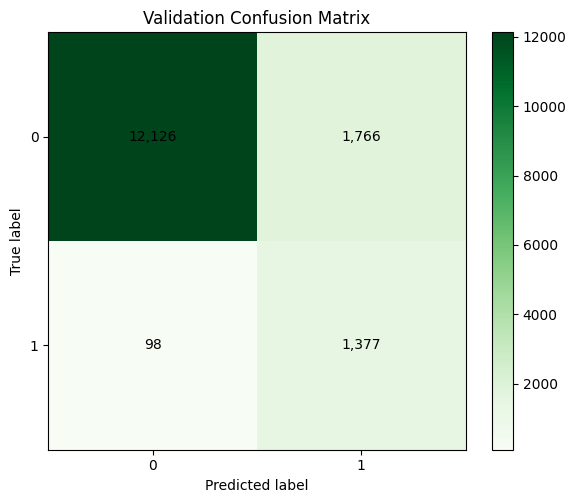

Iteration elapsed: 47.33s
 ==========     ==========     ==========     ==========
ITERATION [24/96]: 10:29:09 PM
    Batch Size:   1024
    Epochs:       150
    α:            0.01
    Weight Decay: 0.01
    
Epoch 1/150, Loss: 2.2052 | 0.004s
Epoch 2/150, Loss: 0.9369 | 0.002s
Epoch 3/150, Loss: 0.2511 | 0.004s
Epoch 4/150, Loss: 0.1521 | 0.004s
Epoch 5/150, Loss: 0.1309 | 0.002s
Epoch 6/150, Loss: 0.1177 | 0.003s
Epoch 7/150, Loss: 0.1089 | 0.003s
Epoch 8/150, Loss: 0.1050 | 0.002s
Epoch 9/150, Loss: 0.1109 | 0.002s
Epoch 10/150, Loss: 0.1047 | 0.003s
Epoch 11/150, Loss: 0.1167 | 0.010s
Epoch 12/150, Loss: 0.1011 | 0.003s
Epoch 13/150, Loss: 0.1001 | 0.002s
Epoch 14/150, Loss: 0.0900 | 0.002s
Epoch 15/150, Loss: 0.1014 | 0.002s
Epoch 16/150, Loss: 0.1172 | 0.003s
Epoch 17/150, Loss: 0.4379 | 0.010s
Epoch 18/150, Loss: 0.3083 | 0.002s
Epoch 19/150, Loss: 0.1636 | 0.002s
Epoch 20/150, Loss: 0.0975 | 0.002s
Epoch 21/150, Loss: 0.0769 | 0.005s
Epoch 22/150, Loss: 0.0937 | 0.002s
Epoch 2

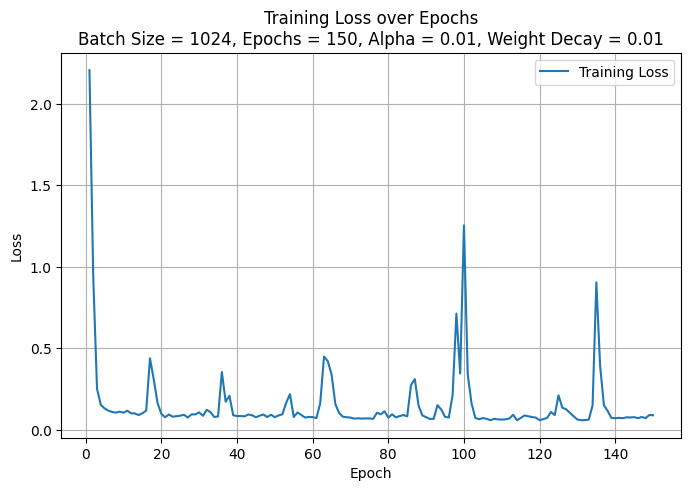

Train loss 0.0746 | Valid loss 0.3062
Valid ROC AUC: 0.911
              precision    recall  f1-score   support

           0      0.968     0.890     0.927     13892
           1      0.411     0.724     0.525      1475

    accuracy                          0.874     15367
   macro avg      0.690     0.807     0.726     15367
weighted avg      0.915     0.874     0.889     15367

[[12363  1529]
 [  407  1068]]


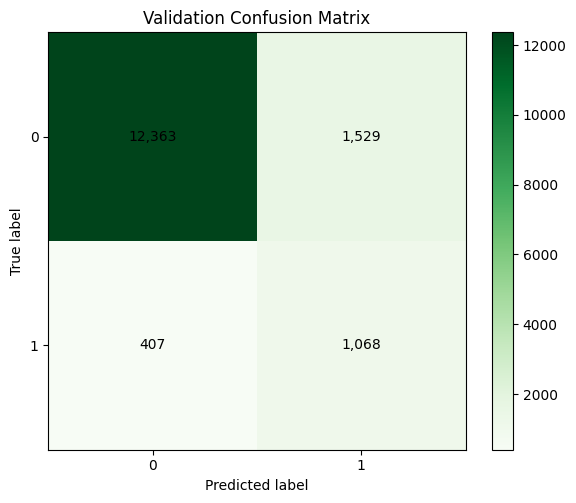

Iteration elapsed: 71.39s
 ==========     ==========     ==========     ==========
ITERATION [25/96]: 10:30:20 PM
    Batch Size:   1024
    Epochs:       150
    α:            0.01
    Weight Decay: 0.001
    
Epoch 1/150, Loss: 2.1266 | 0.006s
Epoch 2/150, Loss: 1.5272 | 0.006s
Epoch 3/150, Loss: 0.2009 | 0.003s
Epoch 4/150, Loss: 0.1151 | 0.002s
Epoch 5/150, Loss: 0.0998 | 0.003s
Epoch 6/150, Loss: 0.0865 | 0.002s
Epoch 7/150, Loss: 0.0800 | 0.002s
Epoch 8/150, Loss: 0.0728 | 0.004s
Epoch 9/150, Loss: 0.0681 | 0.004s
Epoch 10/150, Loss: 0.0628 | 0.004s
Epoch 11/150, Loss: 0.0592 | 0.005s
Epoch 12/150, Loss: 0.0552 | 0.004s
Epoch 13/150, Loss: 0.0530 | 0.003s
Epoch 14/150, Loss: 0.0500 | 0.011s
Epoch 15/150, Loss: 0.0495 | 0.003s
Epoch 16/150, Loss: 0.0469 | 0.005s
Epoch 17/150, Loss: 0.0455 | 0.002s
Epoch 18/150, Loss: 0.0446 | 0.002s
Epoch 19/150, Loss: 0.0414 | 0.011s
Epoch 20/150, Loss: 0.0379 | 0.002s
Epoch 21/150, Loss: 0.0587 | 0.002s
Epoch 22/150, Loss: 0.0631 | 0.004s
Epoch 

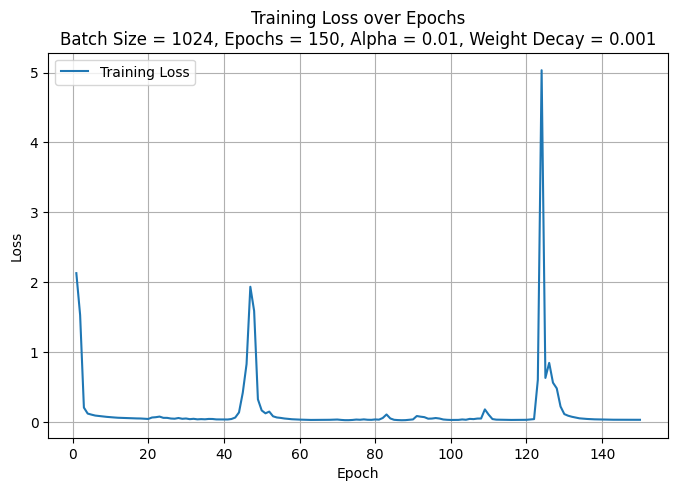

Train loss 0.0241 | Valid loss 0.7455
Valid ROC AUC: 0.945
              precision    recall  f1-score   support

           0      0.994     0.861     0.923     13892
           1      0.420     0.948     0.582      1475

    accuracy                          0.869     15367
   macro avg      0.707     0.905     0.752     15367
weighted avg      0.939     0.869     0.890     15367

[[11961  1931]
 [   76  1399]]


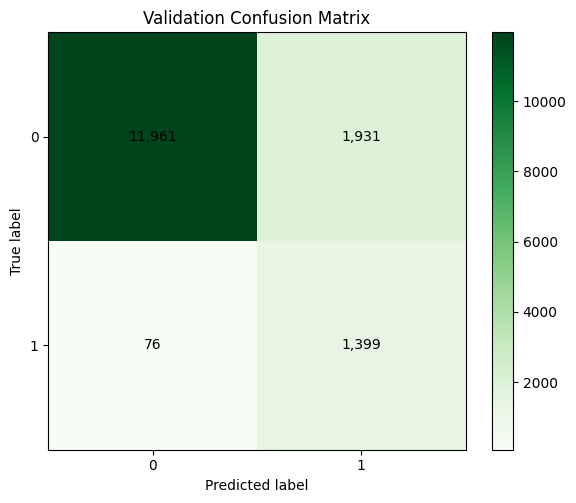

Iteration elapsed: 71.81s
 ==========     ==========     ==========     ==========
ITERATION [26/96]: 10:31:32 PM
    Batch Size:   1024
    Epochs:       150
    α:            0.001
    Weight Decay: 0.01
    
Epoch 1/150, Loss: 0.6376 | 0.002s
Epoch 2/150, Loss: 0.2935 | 0.007s
Epoch 3/150, Loss: 0.2325 | 0.003s
Epoch 4/150, Loss: 0.1930 | 0.003s
Epoch 5/150, Loss: 0.1694 | 0.003s
Epoch 6/150, Loss: 0.1528 | 0.010s
Epoch 7/150, Loss: 0.1401 | 0.002s
Epoch 8/150, Loss: 0.1295 | 0.002s
Epoch 9/150, Loss: 0.1206 | 0.002s
Epoch 10/150, Loss: 0.1122 | 0.004s
Epoch 11/150, Loss: 0.1059 | 0.003s
Epoch 12/150, Loss: 0.0986 | 0.008s
Epoch 13/150, Loss: 0.0940 | 0.002s
Epoch 14/150, Loss: 0.0878 | 0.002s
Epoch 15/150, Loss: 0.0842 | 0.003s
Epoch 16/150, Loss: 0.0791 | 0.003s
Epoch 17/150, Loss: 0.0762 | 0.003s
Epoch 18/150, Loss: 0.0725 | 0.009s
Epoch 19/150, Loss: 0.0702 | 0.002s
Epoch 20/150, Loss: 0.0666 | 0.003s
Epoch 21/150, Loss: 0.0653 | 0.003s
Epoch 22/150, Loss: 0.0620 | 0.002s
Epoch 

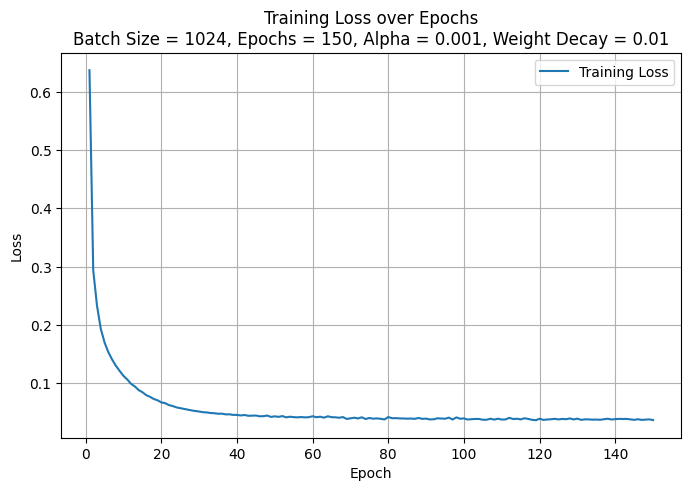

Train loss 0.0302 | Valid loss 0.3416
Valid ROC AUC: 0.955
              precision    recall  f1-score   support

           0      0.993     0.876     0.931     13892
           1      0.447     0.944     0.606      1475

    accuracy                          0.882     15367
   macro avg      0.720     0.910     0.769     15367
weighted avg      0.941     0.882     0.900     15367

[[12167  1725]
 [   83  1392]]


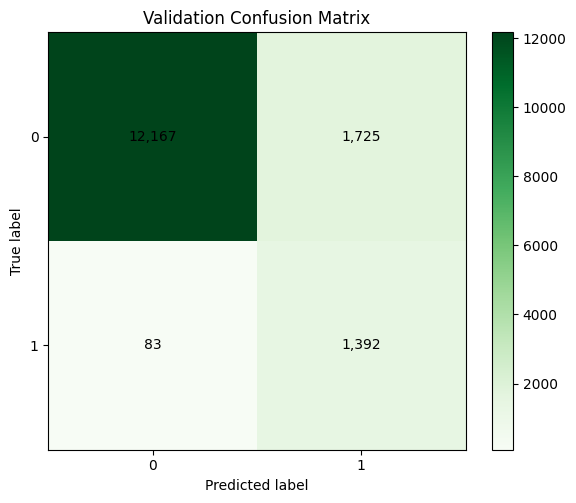

Iteration elapsed: 71.69s
 ==========     ==========     ==========     ==========
ITERATION [27/96]: 10:32:44 PM
    Batch Size:   1024
    Epochs:       150
    α:            0.001
    Weight Decay: 0.001
    
Epoch 1/150, Loss: 0.6346 | 0.002s
Epoch 2/150, Loss: 0.2883 | 0.002s
Epoch 3/150, Loss: 0.2271 | 0.002s
Epoch 4/150, Loss: 0.1880 | 0.003s
Epoch 5/150, Loss: 0.1633 | 0.006s
Epoch 6/150, Loss: 0.1456 | 0.002s
Epoch 7/150, Loss: 0.1316 | 0.002s
Epoch 8/150, Loss: 0.1197 | 0.003s
Epoch 9/150, Loss: 0.1093 | 0.003s
Epoch 10/150, Loss: 0.1002 | 0.004s
Epoch 11/150, Loss: 0.0920 | 0.002s
Epoch 12/150, Loss: 0.0849 | 0.003s
Epoch 13/150, Loss: 0.0785 | 0.002s
Epoch 14/150, Loss: 0.0728 | 0.002s
Epoch 15/150, Loss: 0.0676 | 0.002s
Epoch 16/150, Loss: 0.0629 | 0.003s
Epoch 17/150, Loss: 0.0587 | 0.003s
Epoch 18/150, Loss: 0.0549 | 0.002s
Epoch 19/150, Loss: 0.0514 | 0.003s
Epoch 20/150, Loss: 0.0486 | 0.002s
Epoch 21/150, Loss: 0.0459 | 0.002s
Epoch 22/150, Loss: 0.0434 | 0.011s
Epoch

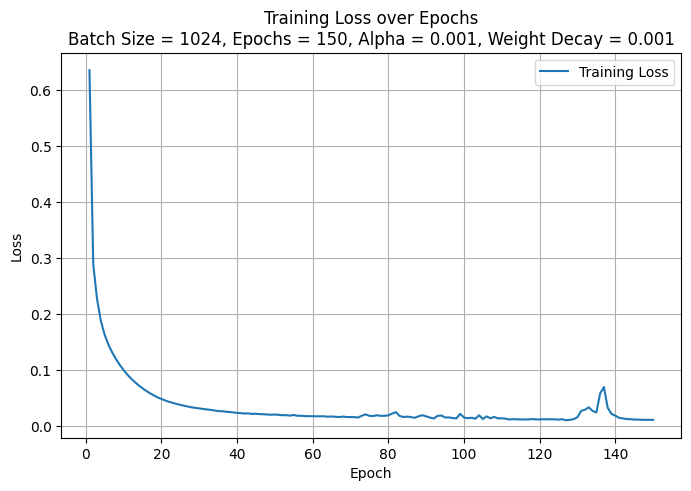

Train loss 0.0082 | Valid loss 0.5325
Valid ROC AUC: 0.948
              precision    recall  f1-score   support

           0      0.992     0.886     0.936     13892
           1      0.465     0.932     0.620      1475

    accuracy                          0.890     15367
   macro avg      0.728     0.909     0.778     15367
weighted avg      0.941     0.890     0.906     15367

[[12309  1583]
 [  100  1375]]


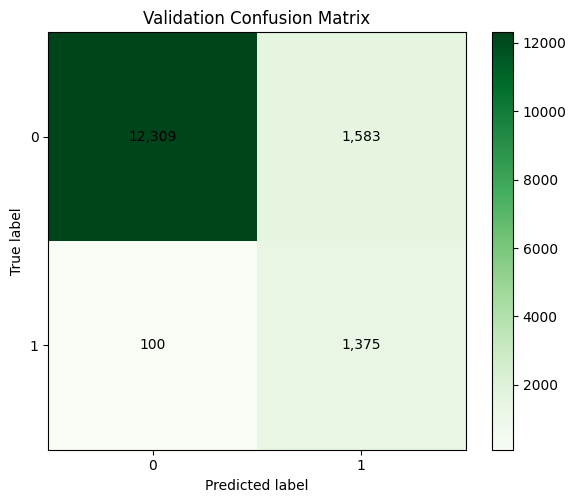

Iteration elapsed: 70.94s
 ==========     ==========     ==========     ==========
ITERATION [28/96]: 10:33:55 PM
    Batch Size:   1024
    Epochs:       200
    α:            0.01
    Weight Decay: 0.01
    
Epoch 1/200, Loss: 2.2052 | 0.004s
Epoch 2/200, Loss: 0.9369 | 0.007s
Epoch 3/200, Loss: 0.2511 | 0.005s
Epoch 4/200, Loss: 0.1521 | 0.006s
Epoch 5/200, Loss: 0.1309 | 0.012s
Epoch 6/200, Loss: 0.1177 | 0.002s
Epoch 7/200, Loss: 0.1089 | 0.002s
Epoch 8/200, Loss: 0.1050 | 0.005s
Epoch 9/200, Loss: 0.1109 | 0.002s
Epoch 10/200, Loss: 0.1047 | 0.004s
Epoch 11/200, Loss: 0.1167 | 0.003s
Epoch 12/200, Loss: 0.1011 | 0.002s
Epoch 13/200, Loss: 0.1001 | 0.002s
Epoch 14/200, Loss: 0.0900 | 0.002s
Epoch 15/200, Loss: 0.1014 | 0.003s
Epoch 16/200, Loss: 0.1172 | 0.003s
Epoch 17/200, Loss: 0.4379 | 0.003s
Epoch 18/200, Loss: 0.3083 | 0.004s
Epoch 19/200, Loss: 0.1636 | 0.002s
Epoch 20/200, Loss: 0.0975 | 0.002s
Epoch 21/200, Loss: 0.0769 | 0.003s
Epoch 22/200, Loss: 0.0937 | 0.002s
Epoch 2

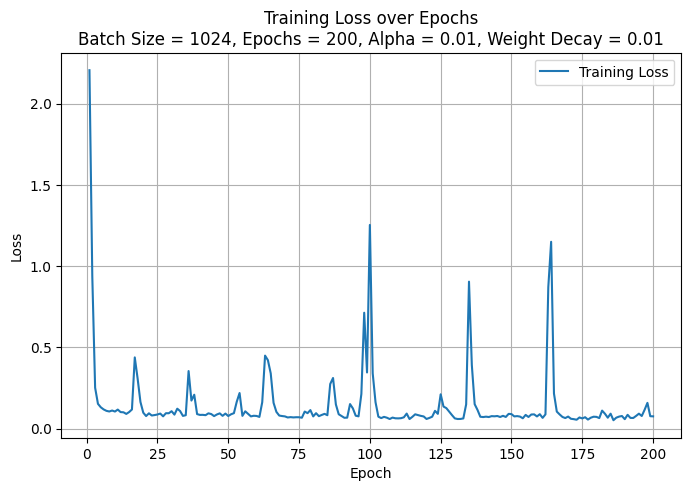

Train loss 0.0599 | Valid loss 0.4771
Valid ROC AUC: 0.909
              precision    recall  f1-score   support

           0      0.979     0.813     0.888     13892
           1      0.322     0.833     0.464      1475

    accuracy                          0.815     15367
   macro avg      0.650     0.823     0.676     15367
weighted avg      0.916     0.815     0.848     15367

[[11300  2592]
 [  246  1229]]


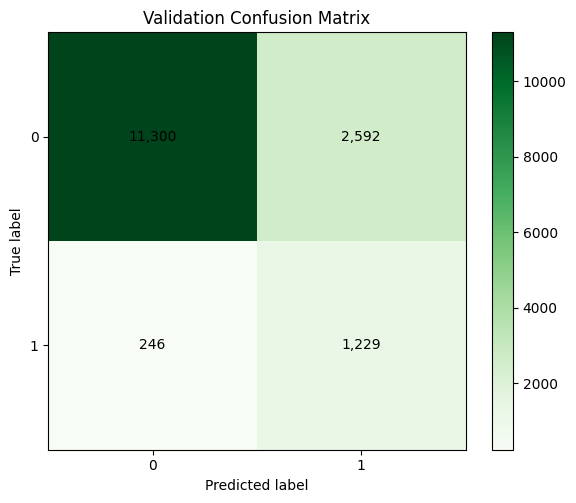

Iteration elapsed: 101.02s
 ==========     ==========     ==========     ==========
ITERATION [29/96]: 10:35:37 PM
    Batch Size:   1024
    Epochs:       200
    α:            0.01
    Weight Decay: 0.001
    
Epoch 1/200, Loss: 2.1266 | 0.003s
Epoch 2/200, Loss: 1.5272 | 0.002s
Epoch 3/200, Loss: 0.2009 | 0.003s
Epoch 4/200, Loss: 0.1151 | 0.002s
Epoch 5/200, Loss: 0.0998 | 0.010s
Epoch 6/200, Loss: 0.0865 | 0.004s
Epoch 7/200, Loss: 0.0800 | 0.010s
Epoch 8/200, Loss: 0.0728 | 0.012s
Epoch 9/200, Loss: 0.0681 | 0.008s
Epoch 10/200, Loss: 0.0628 | 0.011s
Epoch 11/200, Loss: 0.0592 | 0.009s
Epoch 12/200, Loss: 0.0552 | 0.003s
Epoch 13/200, Loss: 0.0530 | 0.003s
Epoch 14/200, Loss: 0.0500 | 0.002s
Epoch 15/200, Loss: 0.0495 | 0.002s
Epoch 16/200, Loss: 0.0469 | 0.006s
Epoch 17/200, Loss: 0.0455 | 0.003s
Epoch 18/200, Loss: 0.0446 | 0.003s
Epoch 19/200, Loss: 0.0414 | 0.003s
Epoch 20/200, Loss: 0.0379 | 0.002s
Epoch 21/200, Loss: 0.0587 | 0.003s
Epoch 22/200, Loss: 0.0631 | 0.002s
Epoch

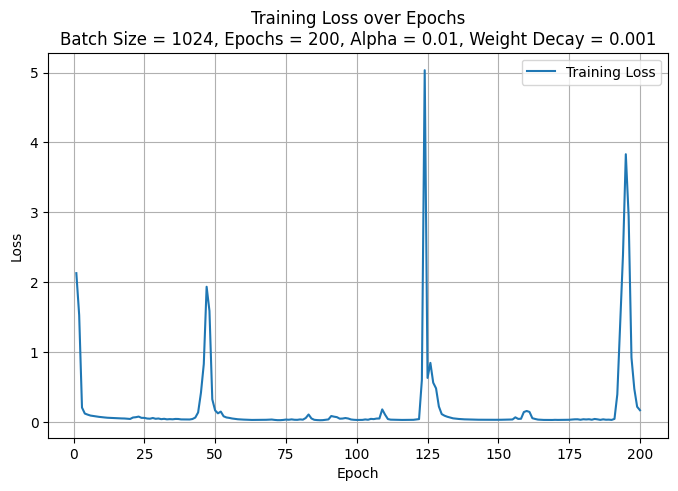

Train loss 0.0993 | Valid loss 2.8869
Valid ROC AUC: 0.928
              precision    recall  f1-score   support

           0      0.994     0.789     0.880     13892
           1      0.324     0.952     0.484      1475

    accuracy                          0.805     15367
   macro avg      0.659     0.871     0.682     15367
weighted avg      0.929     0.805     0.842     15367

[[10965  2927]
 [   71  1404]]


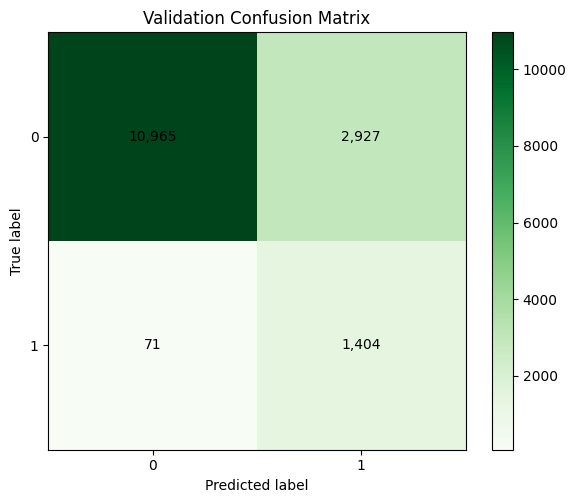

Iteration elapsed: 108.47s
 ==========     ==========     ==========     ==========
ITERATION [30/96]: 10:37:25 PM
    Batch Size:   1024
    Epochs:       200
    α:            0.001
    Weight Decay: 0.01
    
Epoch 1/200, Loss: 0.6376 | 0.002s
Epoch 2/200, Loss: 0.2935 | 0.005s
Epoch 3/200, Loss: 0.2325 | 0.002s
Epoch 4/200, Loss: 0.1930 | 0.002s
Epoch 5/200, Loss: 0.1694 | 0.003s
Epoch 6/200, Loss: 0.1528 | 0.005s
Epoch 7/200, Loss: 0.1401 | 0.006s
Epoch 8/200, Loss: 0.1295 | 0.003s
Epoch 9/200, Loss: 0.1206 | 0.003s
Epoch 10/200, Loss: 0.1122 | 0.002s
Epoch 11/200, Loss: 0.1059 | 0.002s
Epoch 12/200, Loss: 0.0986 | 0.004s
Epoch 13/200, Loss: 0.0940 | 0.003s
Epoch 14/200, Loss: 0.0878 | 0.003s
Epoch 15/200, Loss: 0.0842 | 0.004s
Epoch 16/200, Loss: 0.0791 | 0.011s
Epoch 17/200, Loss: 0.0762 | 0.003s
Epoch 18/200, Loss: 0.0725 | 0.004s
Epoch 19/200, Loss: 0.0702 | 0.003s
Epoch 20/200, Loss: 0.0666 | 0.006s
Epoch 21/200, Loss: 0.0653 | 0.003s
Epoch 22/200, Loss: 0.0620 | 0.002s
Epoch

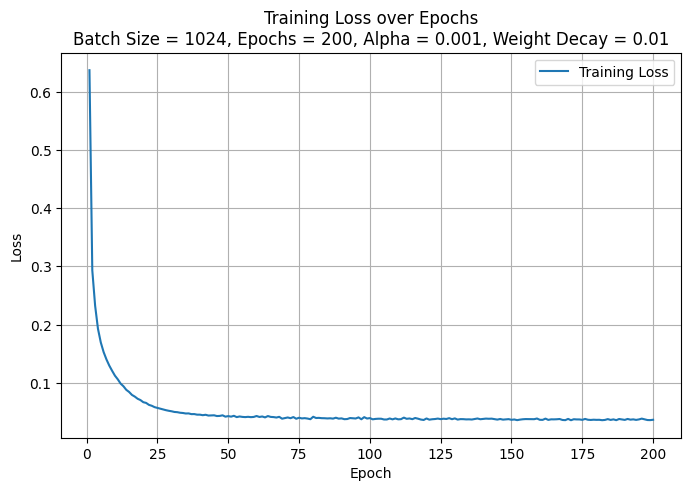

Train loss 0.0300 | Valid loss 0.3355
Valid ROC AUC: 0.951
              precision    recall  f1-score   support

           0      0.992     0.880     0.933     13892
           1      0.454     0.937     0.612      1475

    accuracy                          0.886     15367
   macro avg      0.723     0.909     0.772     15367
weighted avg      0.941     0.886     0.902     15367

[[12230  1662]
 [   93  1382]]


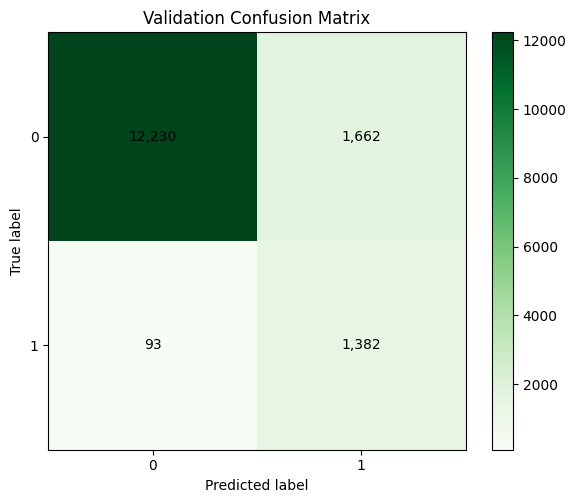

Iteration elapsed: 101.72s
 ==========     ==========     ==========     ==========
ITERATION [31/96]: 10:39:07 PM
    Batch Size:   1024
    Epochs:       200
    α:            0.001
    Weight Decay: 0.001
    
Epoch 1/200, Loss: 0.6346 | 0.010s
Epoch 2/200, Loss: 0.2883 | 0.004s
Epoch 3/200, Loss: 0.2271 | 0.002s
Epoch 4/200, Loss: 0.1880 | 0.004s
Epoch 5/200, Loss: 0.1633 | 0.003s
Epoch 6/200, Loss: 0.1456 | 0.003s
Epoch 7/200, Loss: 0.1316 | 0.009s
Epoch 8/200, Loss: 0.1197 | 0.012s
Epoch 9/200, Loss: 0.1093 | 0.002s
Epoch 10/200, Loss: 0.1002 | 0.002s
Epoch 11/200, Loss: 0.0920 | 0.002s
Epoch 12/200, Loss: 0.0849 | 0.003s
Epoch 13/200, Loss: 0.0785 | 0.003s
Epoch 14/200, Loss: 0.0728 | 0.003s
Epoch 15/200, Loss: 0.0676 | 0.003s
Epoch 16/200, Loss: 0.0629 | 0.011s
Epoch 17/200, Loss: 0.0587 | 0.003s
Epoch 18/200, Loss: 0.0549 | 0.004s
Epoch 19/200, Loss: 0.0514 | 0.004s
Epoch 20/200, Loss: 0.0486 | 0.002s
Epoch 21/200, Loss: 0.0459 | 0.003s
Epoch 22/200, Loss: 0.0434 | 0.007s
Epoc

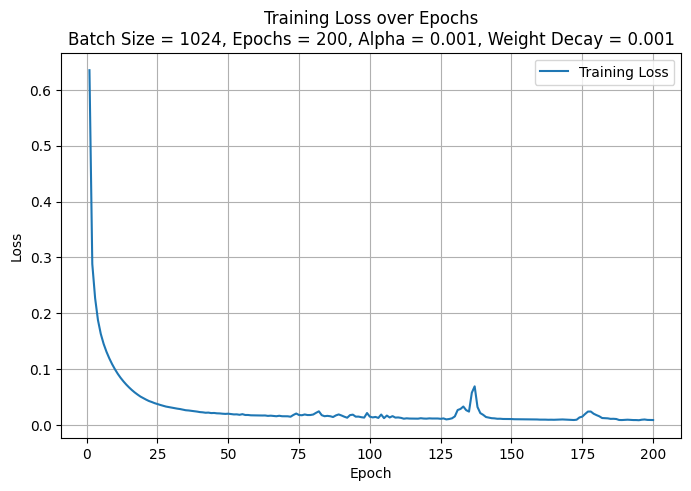

Train loss 0.0085 | Valid loss 0.5420
Valid ROC AUC: 0.943
              precision    recall  f1-score   support

           0      0.989     0.882     0.932     13892
           1      0.449     0.908     0.601      1475

    accuracy                          0.884     15367
   macro avg      0.719     0.895     0.767     15367
weighted avg      0.937     0.884     0.900     15367

[[12247  1645]
 [  135  1340]]


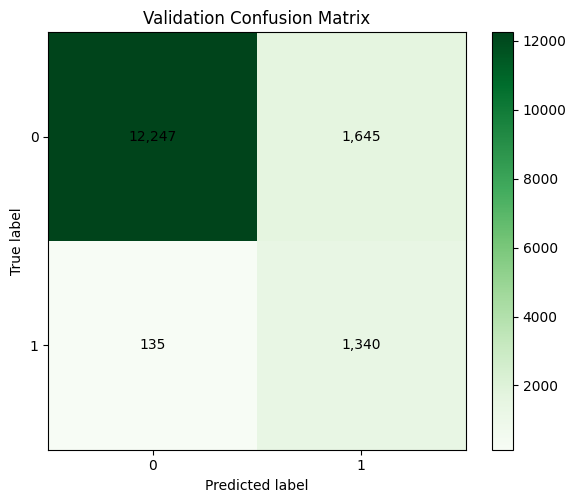

Iteration elapsed: 103.74s
 ==========     ==========     ==========     ==========
ITERATION [32/96]: 10:40:51 PM
    Batch Size:   5119
    Epochs:       50
    α:            0.01
    Weight Decay: 0.01
    
Epoch 1/50, Loss: 1.0373 | 0.012s
Epoch 2/50, Loss: 0.3788 | 0.017s
Epoch 3/50, Loss: 0.3606 | 0.006s
Epoch 4/50, Loss: 0.2107 | 0.004s
Epoch 5/50, Loss: 0.2062 | 0.005s
Epoch 6/50, Loss: 0.1617 | 0.004s
Epoch 7/50, Loss: 0.1458 | 0.004s
Epoch 8/50, Loss: 0.1257 | 0.005s
Epoch 9/50, Loss: 0.1154 | 0.012s
Epoch 10/50, Loss: 0.1078 | 0.012s
Epoch 11/50, Loss: 0.1034 | 0.012s
Epoch 12/50, Loss: 0.0972 | 0.012s
Epoch 13/50, Loss: 0.0922 | 0.010s
Epoch 14/50, Loss: 0.0895 | 0.011s
Epoch 15/50, Loss: 0.0840 | 0.005s
Epoch 16/50, Loss: 0.0794 | 0.013s
Epoch 17/50, Loss: 0.0800 | 0.012s
Epoch 18/50, Loss: 0.0747 | 0.013s
Epoch 19/50, Loss: 0.0720 | 0.008s
Epoch 20/50, Loss: 0.0690 | 0.014s
Epoch 21/50, Loss: 0.0675 | 0.010s
Epoch 22/50, Loss: 0.0634 | 0.005s
Epoch 23/50, Loss: 0.0629 | 0

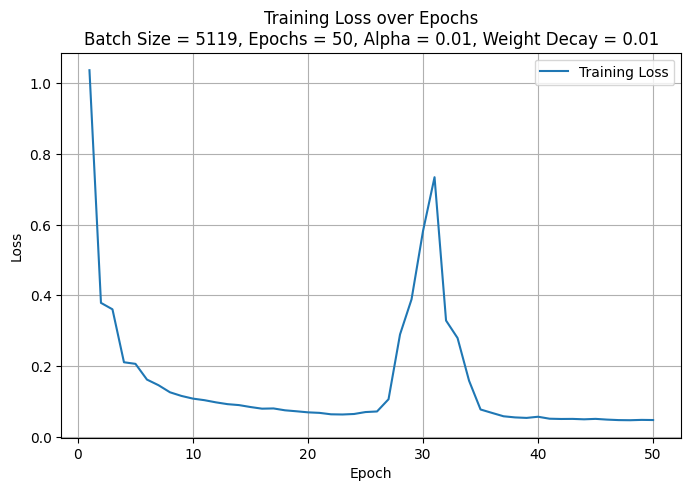

Train loss 0.0532 | Valid loss 0.3568
Valid ROC AUC: 0.962
              precision    recall  f1-score   support

           0      0.996     0.872     0.930     13892
           1      0.445     0.965     0.609      1475

    accuracy                          0.881     15367
   macro avg      0.720     0.919     0.770     15367
weighted avg      0.943     0.881     0.899     15367

[[12119  1773]
 [   52  1423]]


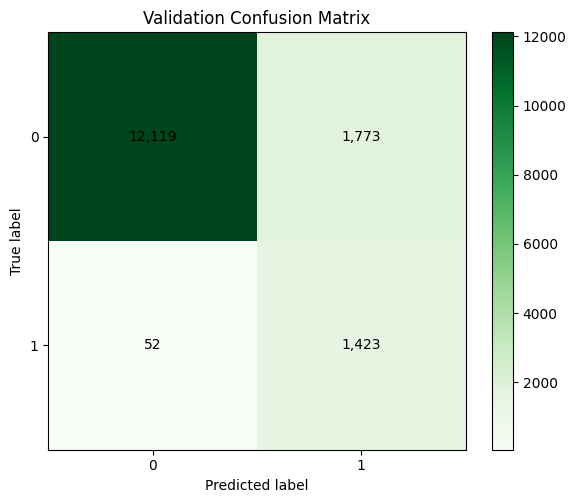

Iteration elapsed: 20.64s
 ==========     ==========     ==========     ==========
ITERATION [33/96]: 10:41:12 PM
    Batch Size:   5119
    Epochs:       50
    α:            0.01
    Weight Decay: 0.001
    
Epoch 1/50, Loss: 1.0846 | 0.007s
Epoch 2/50, Loss: 0.3822 | 0.005s
Epoch 3/50, Loss: 0.3612 | 0.005s
Epoch 4/50, Loss: 0.2311 | 0.013s
Epoch 5/50, Loss: 0.2344 | 0.005s
Epoch 6/50, Loss: 0.1683 | 0.006s
Epoch 7/50, Loss: 0.1403 | 0.012s
Epoch 8/50, Loss: 0.1203 | 0.003s
Epoch 9/50, Loss: 0.1095 | 0.006s
Epoch 10/50, Loss: 0.1036 | 0.007s
Epoch 11/50, Loss: 0.0943 | 0.003s
Epoch 12/50, Loss: 0.0872 | 0.003s
Epoch 13/50, Loss: 0.0807 | 0.008s
Epoch 14/50, Loss: 0.0751 | 0.004s
Epoch 15/50, Loss: 0.0700 | 0.005s
Epoch 16/50, Loss: 0.0657 | 0.009s
Epoch 17/50, Loss: 0.0611 | 0.012s
Epoch 18/50, Loss: 0.0580 | 0.005s
Epoch 19/50, Loss: 0.0532 | 0.004s
Epoch 20/50, Loss: 0.0519 | 0.012s
Epoch 21/50, Loss: 0.0465 | 0.004s
Epoch 22/50, Loss: 0.0446 | 0.004s
Epoch 23/50, Loss: 0.0420 | 0

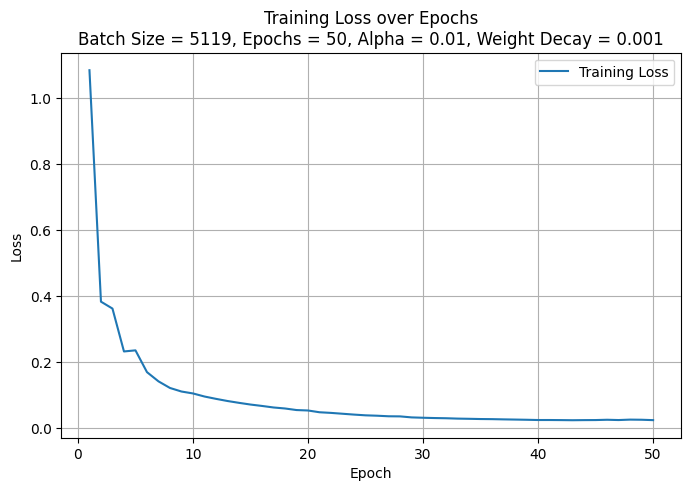

Train loss 0.0277 | Valid loss 0.5326
Valid ROC AUC: 0.958
              precision    recall  f1-score   support

           0      0.996     0.867     0.927     13892
           1      0.435     0.965     0.600      1475

    accuracy                          0.876     15367
   macro avg      0.715     0.916     0.763     15367
weighted avg      0.942     0.876     0.895     15367

[[12044  1848]
 [   52  1423]]


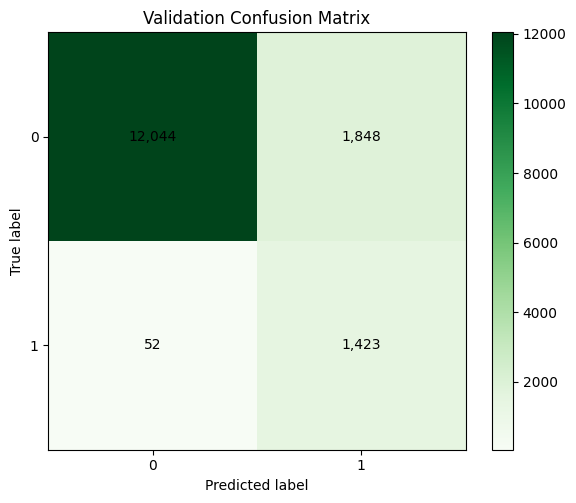

Iteration elapsed: 20.58s
 ==========     ==========     ==========     ==========
ITERATION [34/96]: 10:41:33 PM
    Batch Size:   5119
    Epochs:       50
    α:            0.001
    Weight Decay: 0.01
    
Epoch 1/50, Loss: 0.6443 | 0.009s
Epoch 2/50, Loss: 0.4472 | 0.006s
Epoch 3/50, Loss: 0.3650 | 0.003s
Epoch 4/50, Loss: 0.3143 | 0.004s
Epoch 5/50, Loss: 0.2781 | 0.004s
Epoch 6/50, Loss: 0.2520 | 0.004s
Epoch 7/50, Loss: 0.2321 | 0.008s
Epoch 8/50, Loss: 0.2161 | 0.004s
Epoch 9/50, Loss: 0.2029 | 0.013s
Epoch 10/50, Loss: 0.1917 | 0.006s
Epoch 11/50, Loss: 0.1821 | 0.010s
Epoch 12/50, Loss: 0.1736 | 0.013s
Epoch 13/50, Loss: 0.1661 | 0.013s
Epoch 14/50, Loss: 0.1592 | 0.015s
Epoch 15/50, Loss: 0.1530 | 0.004s
Epoch 16/50, Loss: 0.1473 | 0.003s
Epoch 17/50, Loss: 0.1419 | 0.004s
Epoch 18/50, Loss: 0.1370 | 0.003s
Epoch 19/50, Loss: 0.1323 | 0.004s
Epoch 20/50, Loss: 0.1279 | 0.005s
Epoch 21/50, Loss: 0.1237 | 0.005s
Epoch 22/50, Loss: 0.1199 | 0.010s
Epoch 23/50, Loss: 0.1162 | 0

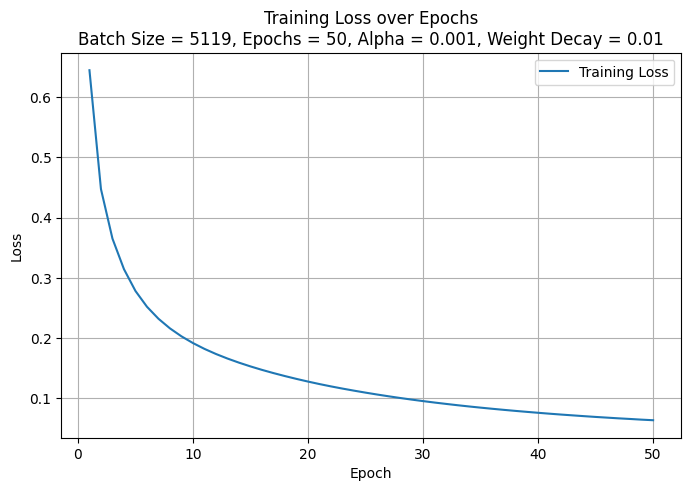

Train loss 0.0656 | Valid loss 0.3195
Valid ROC AUC: 0.964
              precision    recall  f1-score   support

           0      0.994     0.883     0.935     13892
           1      0.461     0.946     0.620      1475

    accuracy                          0.889     15367
   macro avg      0.727     0.915     0.778     15367
weighted avg      0.943     0.889     0.905     15367

[[12262  1630]
 [   79  1396]]


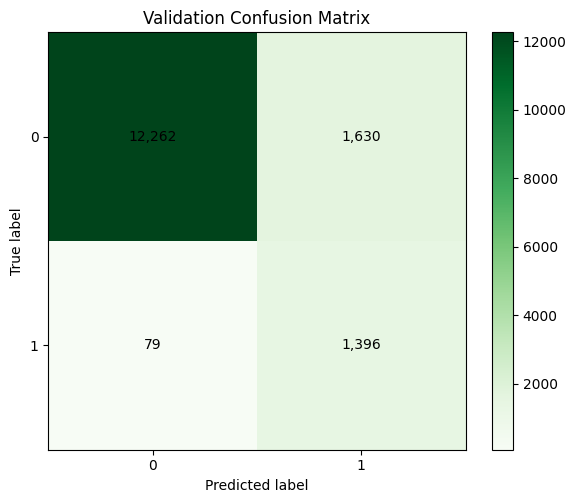

Iteration elapsed: 19.55s
 ==========     ==========     ==========     ==========
ITERATION [35/96]: 10:41:53 PM
    Batch Size:   5119
    Epochs:       50
    α:            0.001
    Weight Decay: 0.001
    
Epoch 1/50, Loss: 0.6443 | 0.005s
Epoch 2/50, Loss: 0.4465 | 0.012s
Epoch 3/50, Loss: 0.3641 | 0.005s
Epoch 4/50, Loss: 0.3133 | 0.011s
Epoch 5/50, Loss: 0.2768 | 0.004s
Epoch 6/50, Loss: 0.2503 | 0.003s
Epoch 7/50, Loss: 0.2302 | 0.004s
Epoch 8/50, Loss: 0.2140 | 0.004s
Epoch 9/50, Loss: 0.2005 | 0.004s
Epoch 10/50, Loss: 0.1891 | 0.003s
Epoch 11/50, Loss: 0.1791 | 0.004s
Epoch 12/50, Loss: 0.1703 | 0.003s
Epoch 13/50, Loss: 0.1624 | 0.010s
Epoch 14/50, Loss: 0.1552 | 0.013s
Epoch 15/50, Loss: 0.1485 | 0.009s
Epoch 16/50, Loss: 0.1424 | 0.005s
Epoch 17/50, Loss: 0.1367 | 0.006s
Epoch 18/50, Loss: 0.1313 | 0.003s
Epoch 19/50, Loss: 0.1263 | 0.006s
Epoch 20/50, Loss: 0.1216 | 0.006s
Epoch 21/50, Loss: 0.1172 | 0.005s
Epoch 22/50, Loss: 0.1131 | 0.005s
Epoch 23/50, Loss: 0.1092 | 

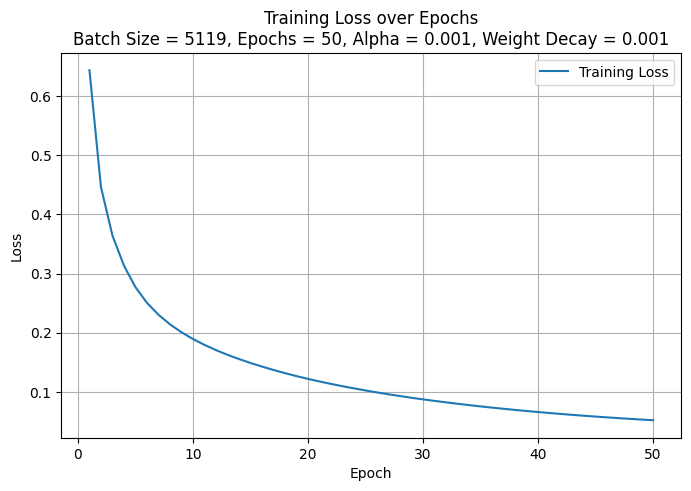

Train loss 0.0531 | Valid loss 0.3792
Valid ROC AUC: 0.965
              precision    recall  f1-score   support

           0      0.994     0.875     0.931     13892
           1      0.446     0.948     0.607      1475

    accuracy                          0.882     15367
   macro avg      0.720     0.912     0.769     15367
weighted avg      0.941     0.882     0.900     15367

[[12156  1736]
 [   76  1399]]


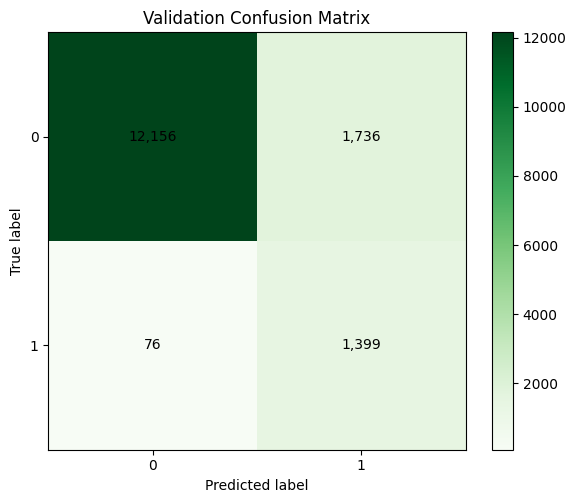

Iteration elapsed: 20.74s
 ==========     ==========     ==========     ==========
ITERATION [36/96]: 10:42:14 PM
    Batch Size:   5119
    Epochs:       100
    α:            0.01
    Weight Decay: 0.01
    
Epoch 1/100, Loss: 1.0373 | 0.005s
Epoch 2/100, Loss: 0.3788 | 0.004s
Epoch 3/100, Loss: 0.3606 | 0.004s
Epoch 4/100, Loss: 0.2107 | 0.003s
Epoch 5/100, Loss: 0.2062 | 0.005s
Epoch 6/100, Loss: 0.1617 | 0.003s
Epoch 7/100, Loss: 0.1458 | 0.007s
Epoch 8/100, Loss: 0.1257 | 0.010s
Epoch 9/100, Loss: 0.1154 | 0.014s
Epoch 10/100, Loss: 0.1078 | 0.012s
Epoch 11/100, Loss: 0.1034 | 0.014s
Epoch 12/100, Loss: 0.0972 | 0.004s
Epoch 13/100, Loss: 0.0922 | 0.003s
Epoch 14/100, Loss: 0.0895 | 0.003s
Epoch 15/100, Loss: 0.0840 | 0.003s
Epoch 16/100, Loss: 0.0794 | 0.003s
Epoch 17/100, Loss: 0.0800 | 0.003s
Epoch 18/100, Loss: 0.0747 | 0.012s
Epoch 19/100, Loss: 0.0720 | 0.014s
Epoch 20/100, Loss: 0.0690 | 0.005s
Epoch 21/100, Loss: 0.0675 | 0.005s
Epoch 22/100, Loss: 0.0634 | 0.013s
Epoch 2

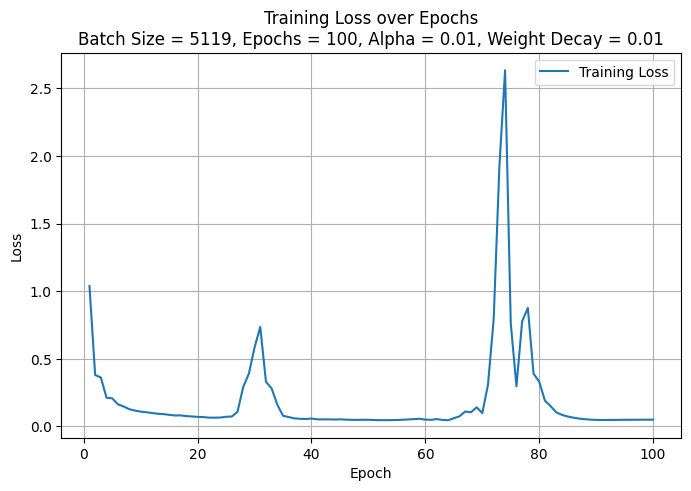

Train loss 0.0508 | Valid loss 0.4704
Valid ROC AUC: 0.963
              precision    recall  f1-score   support

           0      0.996     0.869     0.928     13892
           1      0.439     0.964     0.603      1475

    accuracy                          0.878     15367
   macro avg      0.717     0.917     0.765     15367
weighted avg      0.942     0.878     0.897     15367

[[12072  1820]
 [   53  1422]]


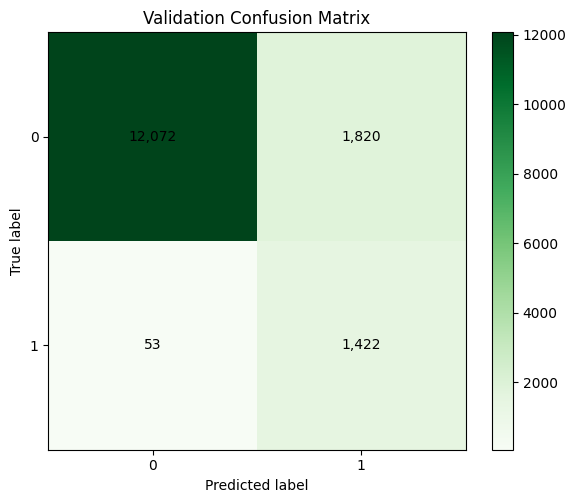

Iteration elapsed: 39.50s
 ==========     ==========     ==========     ==========
ITERATION [37/96]: 10:42:54 PM
    Batch Size:   5119
    Epochs:       100
    α:            0.01
    Weight Decay: 0.001
    
Epoch 1/100, Loss: 1.0846 | 0.009s
Epoch 2/100, Loss: 0.3822 | 0.013s
Epoch 3/100, Loss: 0.3612 | 0.013s
Epoch 4/100, Loss: 0.2311 | 0.010s
Epoch 5/100, Loss: 0.2344 | 0.012s
Epoch 6/100, Loss: 0.1683 | 0.005s
Epoch 7/100, Loss: 0.1403 | 0.003s
Epoch 8/100, Loss: 0.1203 | 0.007s
Epoch 9/100, Loss: 0.1095 | 0.004s
Epoch 10/100, Loss: 0.1036 | 0.004s
Epoch 11/100, Loss: 0.0943 | 0.004s
Epoch 12/100, Loss: 0.0872 | 0.005s
Epoch 13/100, Loss: 0.0807 | 0.005s
Epoch 14/100, Loss: 0.0751 | 0.004s
Epoch 15/100, Loss: 0.0700 | 0.012s
Epoch 16/100, Loss: 0.0657 | 0.006s
Epoch 17/100, Loss: 0.0611 | 0.011s
Epoch 18/100, Loss: 0.0580 | 0.006s
Epoch 19/100, Loss: 0.0532 | 0.014s
Epoch 20/100, Loss: 0.0519 | 0.012s
Epoch 21/100, Loss: 0.0465 | 0.014s
Epoch 22/100, Loss: 0.0446 | 0.004s
Epoch 

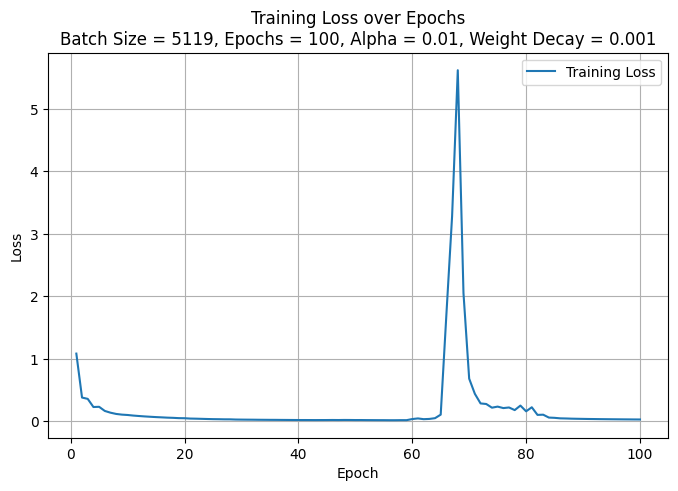

Train loss 0.0295 | Valid loss 0.7175
Valid ROC AUC: 0.976
              precision    recall  f1-score   support

           0      0.997     0.861     0.924     13892
           1      0.427     0.972     0.593      1475

    accuracy                          0.872     15367
   macro avg      0.712     0.917     0.759     15367
weighted avg      0.942     0.872     0.892     15367

[[11967  1925]
 [   41  1434]]


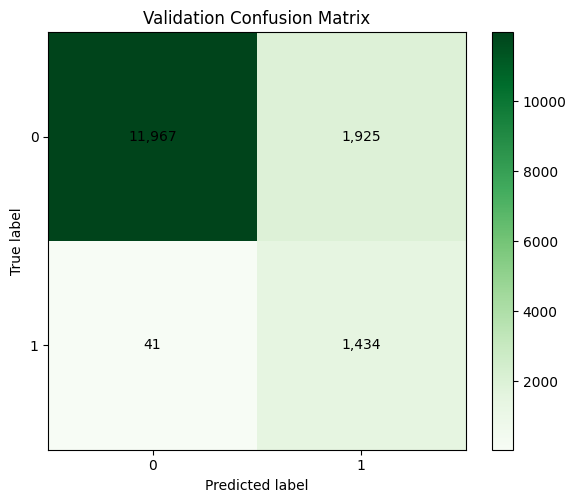

Iteration elapsed: 38.06s
 ==========     ==========     ==========     ==========
ITERATION [38/96]: 10:43:32 PM
    Batch Size:   5119
    Epochs:       100
    α:            0.001
    Weight Decay: 0.01
    
Epoch 1/100, Loss: 0.6443 | 0.004s
Epoch 2/100, Loss: 0.4472 | 0.005s
Epoch 3/100, Loss: 0.3650 | 0.007s
Epoch 4/100, Loss: 0.3143 | 0.005s
Epoch 5/100, Loss: 0.2781 | 0.011s
Epoch 6/100, Loss: 0.2520 | 0.012s
Epoch 7/100, Loss: 0.2321 | 0.008s
Epoch 8/100, Loss: 0.2161 | 0.005s
Epoch 9/100, Loss: 0.2029 | 0.004s
Epoch 10/100, Loss: 0.1917 | 0.005s
Epoch 11/100, Loss: 0.1821 | 0.005s
Epoch 12/100, Loss: 0.1736 | 0.007s
Epoch 13/100, Loss: 0.1661 | 0.004s
Epoch 14/100, Loss: 0.1592 | 0.004s
Epoch 15/100, Loss: 0.1530 | 0.005s
Epoch 16/100, Loss: 0.1473 | 0.012s
Epoch 17/100, Loss: 0.1419 | 0.009s
Epoch 18/100, Loss: 0.1370 | 0.006s
Epoch 19/100, Loss: 0.1323 | 0.006s
Epoch 20/100, Loss: 0.1279 | 0.003s
Epoch 21/100, Loss: 0.1237 | 0.005s
Epoch 22/100, Loss: 0.1199 | 0.004s
Epoch 

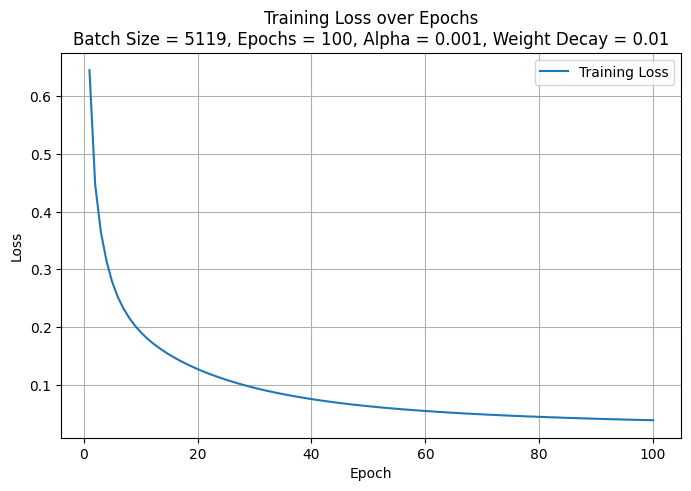

Train loss 0.0400 | Valid loss 0.3301
Valid ROC AUC: 0.964
              precision    recall  f1-score   support

           0      0.995     0.877     0.932     13892
           1      0.451     0.955     0.613      1475

    accuracy                          0.884     15367
   macro avg      0.723     0.916     0.772     15367
weighted avg      0.942     0.884     0.901     15367

[[12179  1713]
 [   67  1408]]


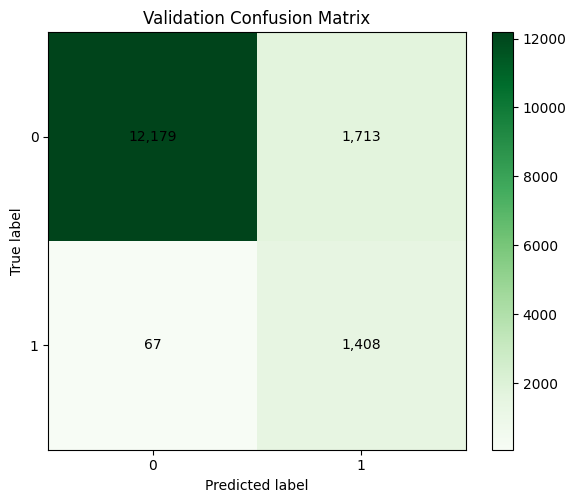

Iteration elapsed: 39.09s
 ==========     ==========     ==========     ==========
ITERATION [39/96]: 10:44:11 PM
    Batch Size:   5119
    Epochs:       100
    α:            0.001
    Weight Decay: 0.001
    
Epoch 1/100, Loss: 0.6443 | 0.010s
Epoch 2/100, Loss: 0.4465 | 0.005s
Epoch 3/100, Loss: 0.3641 | 0.010s
Epoch 4/100, Loss: 0.3133 | 0.005s
Epoch 5/100, Loss: 0.2768 | 0.011s
Epoch 6/100, Loss: 0.2503 | 0.003s
Epoch 7/100, Loss: 0.2302 | 0.003s
Epoch 8/100, Loss: 0.2140 | 0.004s
Epoch 9/100, Loss: 0.2005 | 0.003s
Epoch 10/100, Loss: 0.1891 | 0.004s
Epoch 11/100, Loss: 0.1791 | 0.003s
Epoch 12/100, Loss: 0.1703 | 0.006s
Epoch 13/100, Loss: 0.1624 | 0.004s
Epoch 14/100, Loss: 0.1552 | 0.012s
Epoch 15/100, Loss: 0.1485 | 0.013s
Epoch 16/100, Loss: 0.1424 | 0.012s
Epoch 17/100, Loss: 0.1367 | 0.009s
Epoch 18/100, Loss: 0.1313 | 0.015s
Epoch 19/100, Loss: 0.1263 | 0.011s
Epoch 20/100, Loss: 0.1216 | 0.014s
Epoch 21/100, Loss: 0.1172 | 0.012s
Epoch 22/100, Loss: 0.1131 | 0.006s
Epoch

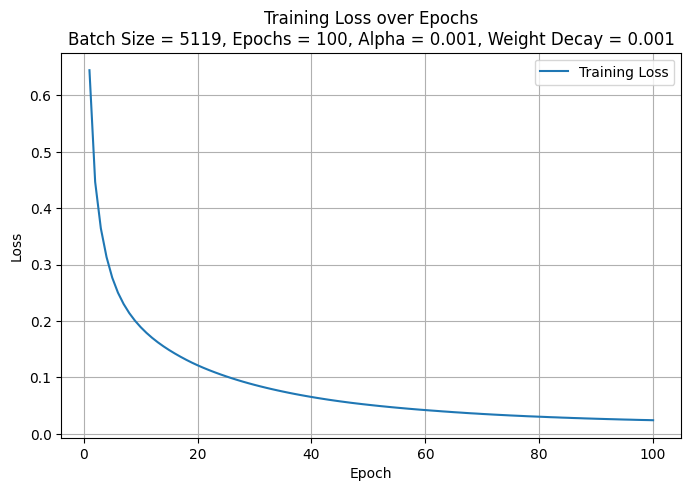

Train loss 0.0242 | Valid loss 0.4457
Valid ROC AUC: 0.962
              precision    recall  f1-score   support

           0      0.995     0.873     0.930     13892
           1      0.446     0.961     0.609      1475

    accuracy                          0.881     15367
   macro avg      0.720     0.917     0.770     15367
weighted avg      0.943     0.881     0.899     15367

[[12128  1764]
 [   57  1418]]


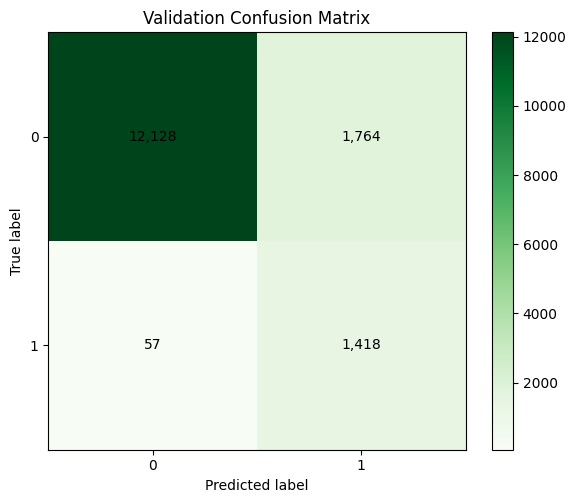

Iteration elapsed: 38.03s
 ==========     ==========     ==========     ==========
ITERATION [40/96]: 10:44:50 PM
    Batch Size:   5119
    Epochs:       150
    α:            0.01
    Weight Decay: 0.01
    
Epoch 1/150, Loss: 1.0373 | 0.005s
Epoch 2/150, Loss: 0.3788 | 0.005s
Epoch 3/150, Loss: 0.3606 | 0.013s
Epoch 4/150, Loss: 0.2107 | 0.005s
Epoch 5/150, Loss: 0.2062 | 0.005s
Epoch 6/150, Loss: 0.1617 | 0.007s
Epoch 7/150, Loss: 0.1458 | 0.007s
Epoch 8/150, Loss: 0.1257 | 0.005s
Epoch 9/150, Loss: 0.1154 | 0.005s
Epoch 10/150, Loss: 0.1078 | 0.011s
Epoch 11/150, Loss: 0.1034 | 0.014s
Epoch 12/150, Loss: 0.0972 | 0.004s
Epoch 13/150, Loss: 0.0922 | 0.003s
Epoch 14/150, Loss: 0.0895 | 0.003s
Epoch 15/150, Loss: 0.0840 | 0.004s
Epoch 16/150, Loss: 0.0794 | 0.005s
Epoch 17/150, Loss: 0.0800 | 0.003s
Epoch 18/150, Loss: 0.0747 | 0.003s
Epoch 19/150, Loss: 0.0720 | 0.004s
Epoch 20/150, Loss: 0.0690 | 0.014s
Epoch 21/150, Loss: 0.0675 | 0.013s
Epoch 22/150, Loss: 0.0634 | 0.006s
Epoch 2

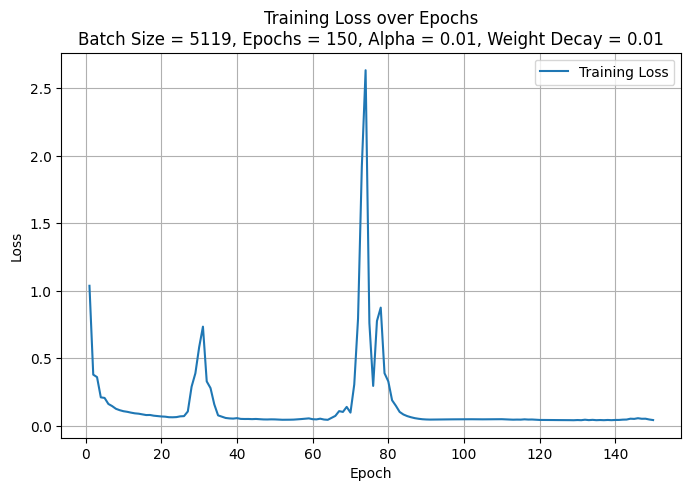

Train loss 0.0390 | Valid loss 0.3746
Valid ROC AUC: 0.957
              precision    recall  f1-score   support

           0      0.994     0.870     0.928     13892
           1      0.437     0.955     0.600      1475

    accuracy                          0.878     15367
   macro avg      0.716     0.912     0.764     15367
weighted avg      0.941     0.878     0.896     15367

[[12081  1811]
 [   67  1408]]


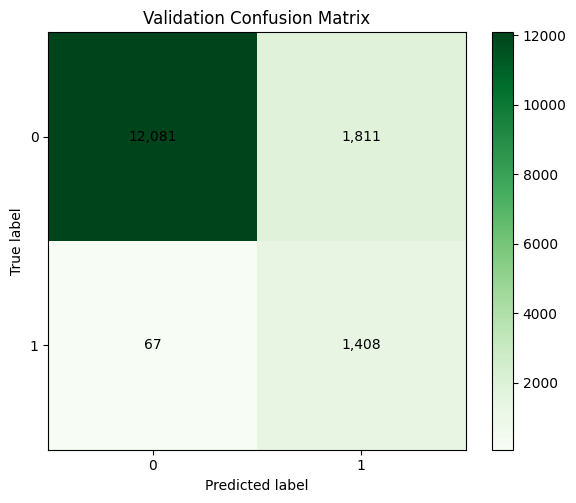

Iteration elapsed: 57.73s
 ==========     ==========     ==========     ==========
ITERATION [41/96]: 10:45:48 PM
    Batch Size:   5119
    Epochs:       150
    α:            0.01
    Weight Decay: 0.001
    
Epoch 1/150, Loss: 1.0846 | 0.013s
Epoch 2/150, Loss: 0.3822 | 0.005s
Epoch 3/150, Loss: 0.3612 | 0.003s
Epoch 4/150, Loss: 0.2311 | 0.004s
Epoch 5/150, Loss: 0.2344 | 0.004s
Epoch 6/150, Loss: 0.1683 | 0.004s
Epoch 7/150, Loss: 0.1403 | 0.005s
Epoch 8/150, Loss: 0.1203 | 0.005s
Epoch 9/150, Loss: 0.1095 | 0.013s
Epoch 10/150, Loss: 0.1036 | 0.015s
Epoch 11/150, Loss: 0.0943 | 0.012s
Epoch 12/150, Loss: 0.0872 | 0.006s
Epoch 13/150, Loss: 0.0807 | 0.011s
Epoch 14/150, Loss: 0.0751 | 0.012s
Epoch 15/150, Loss: 0.0700 | 0.014s
Epoch 16/150, Loss: 0.0657 | 0.004s
Epoch 17/150, Loss: 0.0611 | 0.008s
Epoch 18/150, Loss: 0.0580 | 0.005s
Epoch 19/150, Loss: 0.0532 | 0.010s
Epoch 20/150, Loss: 0.0519 | 0.013s
Epoch 21/150, Loss: 0.0465 | 0.012s
Epoch 22/150, Loss: 0.0446 | 0.005s
Epoch 

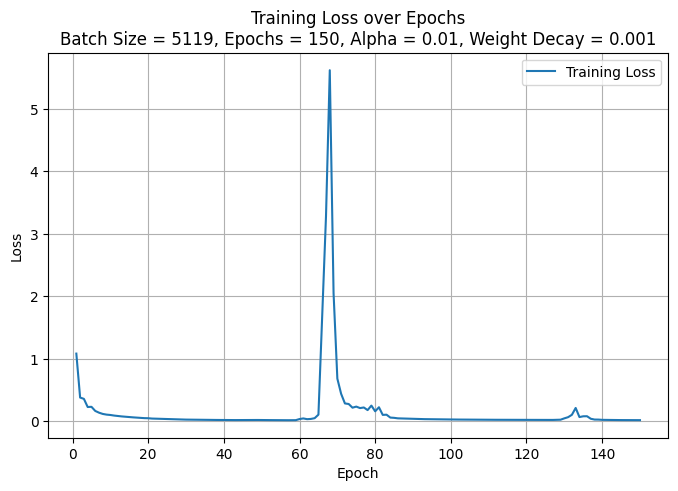

Train loss 0.0202 | Valid loss 0.5591
Valid ROC AUC: 0.966
              precision    recall  f1-score   support

           0      0.996     0.872     0.930     13892
           1      0.445     0.971     0.611      1475

    accuracy                          0.881     15367
   macro avg      0.721     0.921     0.770     15367
weighted avg      0.944     0.881     0.899     15367

[[12109  1783]
 [   43  1432]]


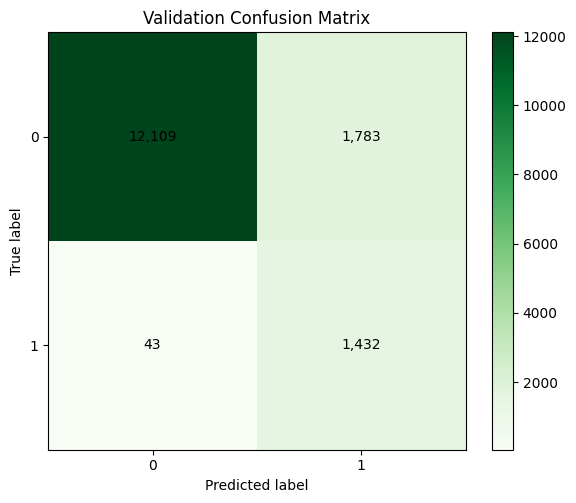

Iteration elapsed: 57.75s
 ==========     ==========     ==========     ==========
ITERATION [42/96]: 10:46:46 PM
    Batch Size:   5119
    Epochs:       150
    α:            0.001
    Weight Decay: 0.01
    
Epoch 1/150, Loss: 0.6443 | 0.006s
Epoch 2/150, Loss: 0.4472 | 0.008s
Epoch 3/150, Loss: 0.3650 | 0.005s
Epoch 4/150, Loss: 0.3143 | 0.014s
Epoch 5/150, Loss: 0.2781 | 0.014s
Epoch 6/150, Loss: 0.2520 | 0.012s
Epoch 7/150, Loss: 0.2321 | 0.008s
Epoch 8/150, Loss: 0.2161 | 0.006s
Epoch 9/150, Loss: 0.2029 | 0.004s
Epoch 10/150, Loss: 0.1917 | 0.003s
Epoch 11/150, Loss: 0.1821 | 0.003s
Epoch 12/150, Loss: 0.1736 | 0.004s
Epoch 13/150, Loss: 0.1661 | 0.003s
Epoch 14/150, Loss: 0.1592 | 0.007s
Epoch 15/150, Loss: 0.1530 | 0.005s
Epoch 16/150, Loss: 0.1473 | 0.008s
Epoch 17/150, Loss: 0.1419 | 0.005s
Epoch 18/150, Loss: 0.1370 | 0.013s
Epoch 19/150, Loss: 0.1323 | 0.010s
Epoch 20/150, Loss: 0.1279 | 0.012s
Epoch 21/150, Loss: 0.1237 | 0.006s
Epoch 22/150, Loss: 0.1199 | 0.005s
Epoch 

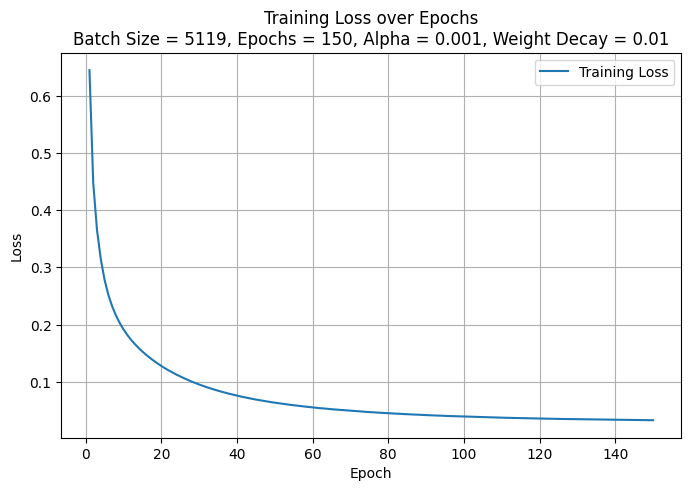

Train loss 0.0335 | Valid loss 0.3416
Valid ROC AUC: 0.962
              precision    recall  f1-score   support

           0      0.995     0.874     0.930     13892
           1      0.446     0.957     0.609      1475

    accuracy                          0.882     15367
   macro avg      0.721     0.916     0.770     15367
weighted avg      0.942     0.882     0.900     15367

[[12141  1751]
 [   63  1412]]


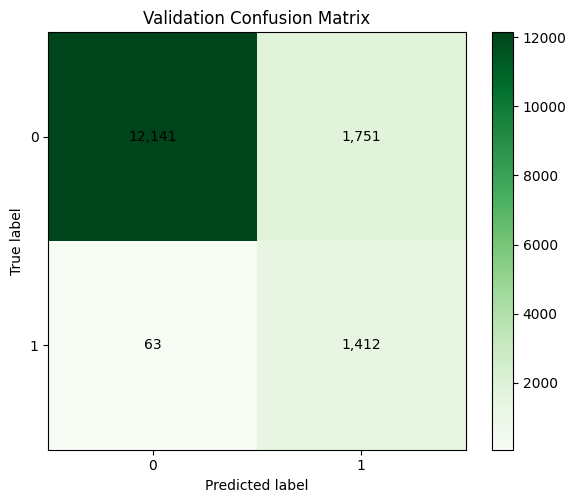

Iteration elapsed: 57.90s
 ==========     ==========     ==========     ==========
ITERATION [43/96]: 10:47:44 PM
    Batch Size:   5119
    Epochs:       150
    α:            0.001
    Weight Decay: 0.001
    
Epoch 1/150, Loss: 0.6443 | 0.005s
Epoch 2/150, Loss: 0.4465 | 0.004s
Epoch 3/150, Loss: 0.3641 | 0.005s
Epoch 4/150, Loss: 0.3133 | 0.006s
Epoch 5/150, Loss: 0.2768 | 0.010s
Epoch 6/150, Loss: 0.2503 | 0.011s
Epoch 7/150, Loss: 0.2302 | 0.006s
Epoch 8/150, Loss: 0.2140 | 0.006s
Epoch 9/150, Loss: 0.2005 | 0.005s
Epoch 10/150, Loss: 0.1891 | 0.014s
Epoch 11/150, Loss: 0.1791 | 0.015s
Epoch 12/150, Loss: 0.1703 | 0.011s
Epoch 13/150, Loss: 0.1624 | 0.013s
Epoch 14/150, Loss: 0.1552 | 0.006s
Epoch 15/150, Loss: 0.1485 | 0.004s
Epoch 16/150, Loss: 0.1424 | 0.005s
Epoch 17/150, Loss: 0.1367 | 0.005s
Epoch 18/150, Loss: 0.1313 | 0.005s
Epoch 19/150, Loss: 0.1263 | 0.009s
Epoch 20/150, Loss: 0.1216 | 0.005s
Epoch 21/150, Loss: 0.1172 | 0.006s
Epoch 22/150, Loss: 0.1131 | 0.008s
Epoch

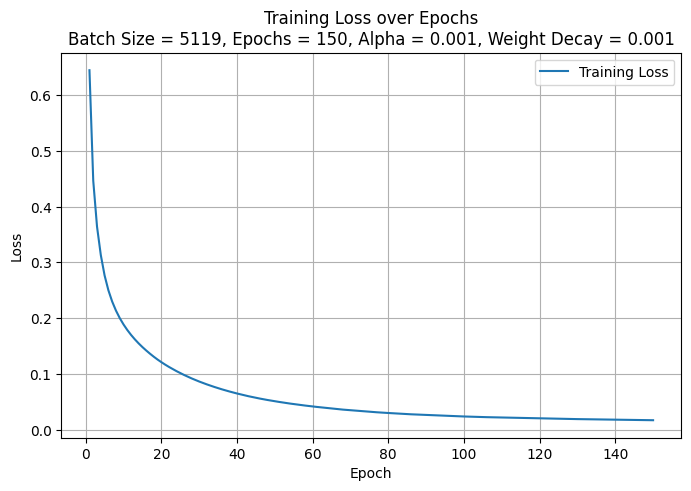

Train loss 0.0171 | Valid loss 0.5013
Valid ROC AUC: 0.957
              precision    recall  f1-score   support

           0      0.995     0.873     0.930     13892
           1      0.445     0.955     0.607      1475

    accuracy                          0.881     15367
   macro avg      0.720     0.914     0.768     15367
weighted avg      0.942     0.881     0.899     15367

[[12133  1759]
 [   66  1409]]


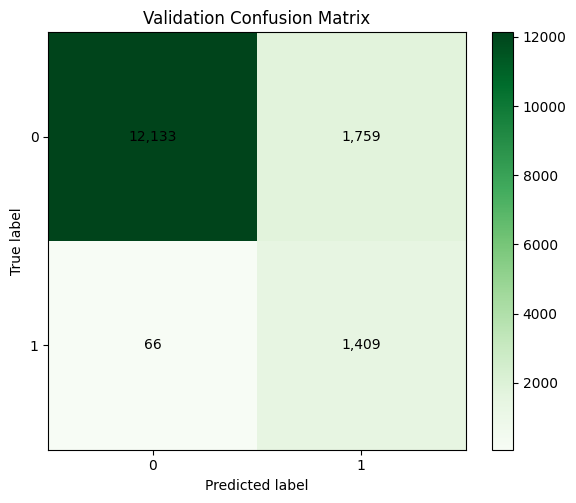

Iteration elapsed: 58.07s
 ==========     ==========     ==========     ==========
ITERATION [44/96]: 10:48:42 PM
    Batch Size:   5119
    Epochs:       200
    α:            0.01
    Weight Decay: 0.01
    
Epoch 1/200, Loss: 1.0373 | 0.004s
Epoch 2/200, Loss: 0.3788 | 0.005s
Epoch 3/200, Loss: 0.3606 | 0.004s
Epoch 4/200, Loss: 0.2107 | 0.013s
Epoch 5/200, Loss: 0.2062 | 0.010s
Epoch 6/200, Loss: 0.1617 | 0.007s
Epoch 7/200, Loss: 0.1458 | 0.008s
Epoch 8/200, Loss: 0.1257 | 0.013s
Epoch 9/200, Loss: 0.1154 | 0.012s
Epoch 10/200, Loss: 0.1078 | 0.012s
Epoch 11/200, Loss: 0.1034 | 0.004s
Epoch 12/200, Loss: 0.0972 | 0.014s
Epoch 13/200, Loss: 0.0922 | 0.012s
Epoch 14/200, Loss: 0.0895 | 0.013s
Epoch 15/200, Loss: 0.0840 | 0.012s
Epoch 16/200, Loss: 0.0794 | 0.014s
Epoch 17/200, Loss: 0.0800 | 0.012s
Epoch 18/200, Loss: 0.0747 | 0.006s
Epoch 19/200, Loss: 0.0720 | 0.010s
Epoch 20/200, Loss: 0.0690 | 0.015s
Epoch 21/200, Loss: 0.0675 | 0.013s
Epoch 22/200, Loss: 0.0634 | 0.012s
Epoch 2

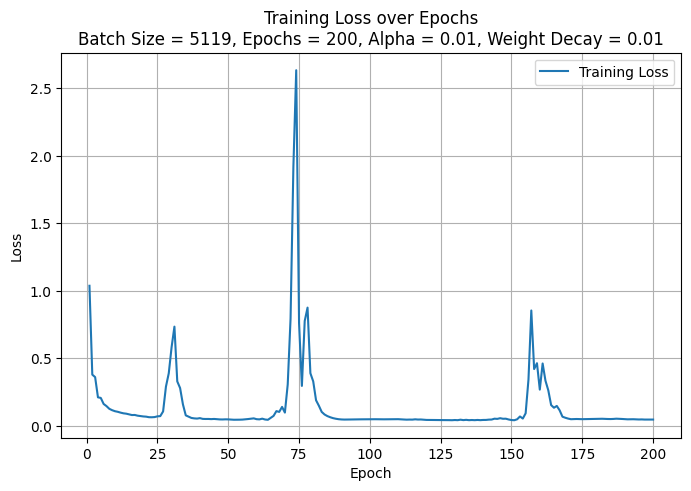

Train loss 0.0487 | Valid loss 0.3546
Valid ROC AUC: 0.966
              precision    recall  f1-score   support

           0      0.996     0.871     0.930     13892
           1      0.444     0.967     0.608      1475

    accuracy                          0.881     15367
   macro avg      0.720     0.919     0.769     15367
weighted avg      0.943     0.881     0.899     15367

[[12105  1787]
 [   49  1426]]


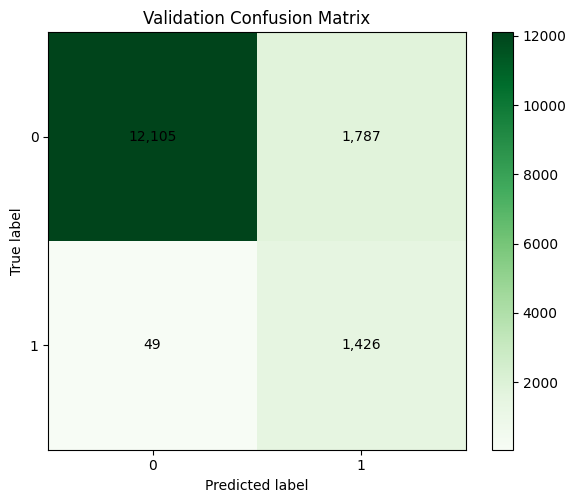

Iteration elapsed: 76.52s
 ==========     ==========     ==========     ==========
ITERATION [45/96]: 10:49:59 PM
    Batch Size:   5119
    Epochs:       200
    α:            0.01
    Weight Decay: 0.001
    
Epoch 1/200, Loss: 1.0846 | 0.005s
Epoch 2/200, Loss: 0.3822 | 0.004s
Epoch 3/200, Loss: 0.3612 | 0.005s
Epoch 4/200, Loss: 0.2311 | 0.003s
Epoch 5/200, Loss: 0.2344 | 0.007s
Epoch 6/200, Loss: 0.1683 | 0.014s
Epoch 7/200, Loss: 0.1403 | 0.010s
Epoch 8/200, Loss: 0.1203 | 0.005s
Epoch 9/200, Loss: 0.1095 | 0.006s
Epoch 10/200, Loss: 0.1036 | 0.005s
Epoch 11/200, Loss: 0.0943 | 0.011s
Epoch 12/200, Loss: 0.0872 | 0.004s
Epoch 13/200, Loss: 0.0807 | 0.011s
Epoch 14/200, Loss: 0.0751 | 0.012s
Epoch 15/200, Loss: 0.0700 | 0.005s
Epoch 16/200, Loss: 0.0657 | 0.006s
Epoch 17/200, Loss: 0.0611 | 0.006s
Epoch 18/200, Loss: 0.0580 | 0.005s
Epoch 19/200, Loss: 0.0532 | 0.005s
Epoch 20/200, Loss: 0.0519 | 0.012s
Epoch 21/200, Loss: 0.0465 | 0.005s
Epoch 22/200, Loss: 0.0446 | 0.005s
Epoch 

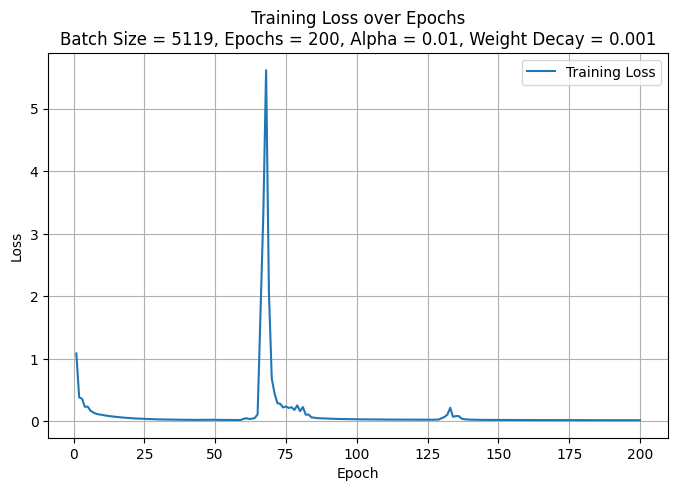

Train loss 0.0177 | Valid loss 0.5148
Valid ROC AUC: 0.956
              precision    recall  f1-score   support

           0      0.995     0.871     0.929     13892
           1      0.443     0.963     0.607      1475

    accuracy                          0.880     15367
   macro avg      0.719     0.917     0.768     15367
weighted avg      0.942     0.880     0.898     15367

[[12105  1787]
 [   55  1420]]


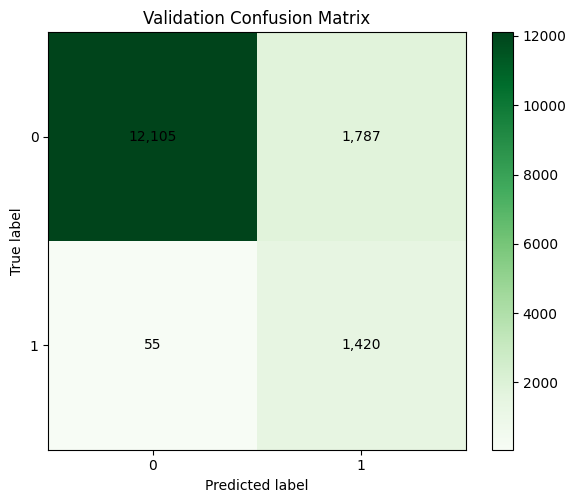

Iteration elapsed: 78.35s
 ==========     ==========     ==========     ==========
ITERATION [46/96]: 10:51:18 PM
    Batch Size:   5119
    Epochs:       200
    α:            0.001
    Weight Decay: 0.01
    
Epoch 1/200, Loss: 0.6443 | 0.004s
Epoch 2/200, Loss: 0.4472 | 0.004s
Epoch 3/200, Loss: 0.3650 | 0.012s
Epoch 4/200, Loss: 0.3143 | 0.004s
Epoch 5/200, Loss: 0.2781 | 0.004s
Epoch 6/200, Loss: 0.2520 | 0.006s
Epoch 7/200, Loss: 0.2321 | 0.006s
Epoch 8/200, Loss: 0.2161 | 0.005s
Epoch 9/200, Loss: 0.2029 | 0.010s
Epoch 10/200, Loss: 0.1917 | 0.013s
Epoch 11/200, Loss: 0.1821 | 0.010s
Epoch 12/200, Loss: 0.1736 | 0.012s
Epoch 13/200, Loss: 0.1661 | 0.010s
Epoch 14/200, Loss: 0.1592 | 0.014s
Epoch 15/200, Loss: 0.1530 | 0.004s
Epoch 16/200, Loss: 0.1473 | 0.006s
Epoch 17/200, Loss: 0.1419 | 0.006s
Epoch 18/200, Loss: 0.1370 | 0.003s
Epoch 19/200, Loss: 0.1323 | 0.006s
Epoch 20/200, Loss: 0.1279 | 0.005s
Epoch 21/200, Loss: 0.1237 | 0.006s
Epoch 22/200, Loss: 0.1199 | 0.005s
Epoch 

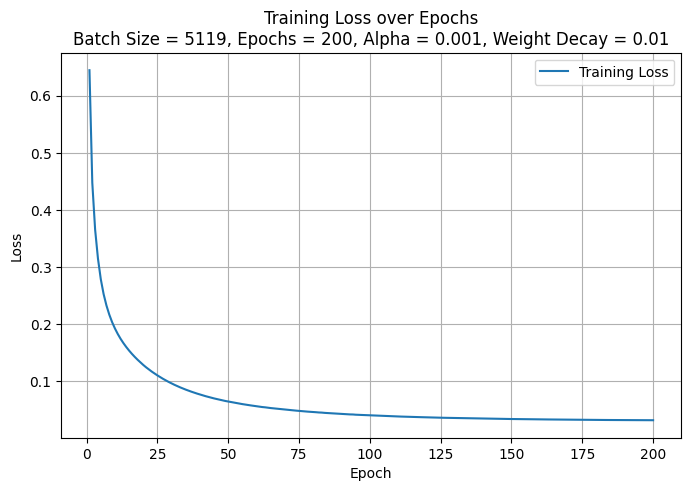

Train loss 0.0310 | Valid loss 0.3436
Valid ROC AUC: 0.961
              precision    recall  f1-score   support

           0      0.995     0.873     0.930     13892
           1      0.446     0.960     0.609      1475

    accuracy                          0.882     15367
   macro avg      0.720     0.917     0.769     15367
weighted avg      0.942     0.882     0.899     15367

[[12131  1761]
 [   59  1416]]


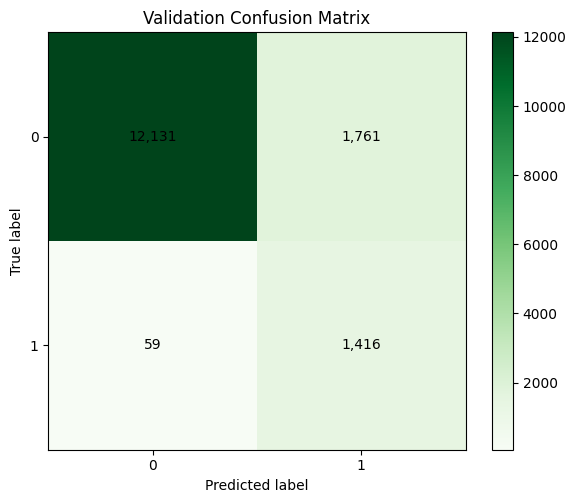

Iteration elapsed: 79.17s
 ==========     ==========     ==========     ==========
ITERATION [47/96]: 10:52:37 PM
    Batch Size:   5119
    Epochs:       200
    α:            0.001
    Weight Decay: 0.001
    
Epoch 1/200, Loss: 0.6443 | 0.005s
Epoch 2/200, Loss: 0.4465 | 0.004s
Epoch 3/200, Loss: 0.3641 | 0.004s
Epoch 4/200, Loss: 0.3133 | 0.005s
Epoch 5/200, Loss: 0.2768 | 0.014s
Epoch 6/200, Loss: 0.2503 | 0.005s
Epoch 7/200, Loss: 0.2302 | 0.005s
Epoch 8/200, Loss: 0.2140 | 0.012s
Epoch 9/200, Loss: 0.2005 | 0.013s
Epoch 10/200, Loss: 0.1891 | 0.012s
Epoch 11/200, Loss: 0.1791 | 0.013s
Epoch 12/200, Loss: 0.1703 | 0.015s
Epoch 13/200, Loss: 0.1624 | 0.008s
Epoch 14/200, Loss: 0.1552 | 0.005s
Epoch 15/200, Loss: 0.1485 | 0.005s
Epoch 16/200, Loss: 0.1424 | 0.005s
Epoch 17/200, Loss: 0.1367 | 0.004s
Epoch 18/200, Loss: 0.1313 | 0.008s
Epoch 19/200, Loss: 0.1263 | 0.005s
Epoch 20/200, Loss: 0.1216 | 0.012s
Epoch 21/200, Loss: 0.1172 | 0.004s
Epoch 22/200, Loss: 0.1131 | 0.004s
Epoch

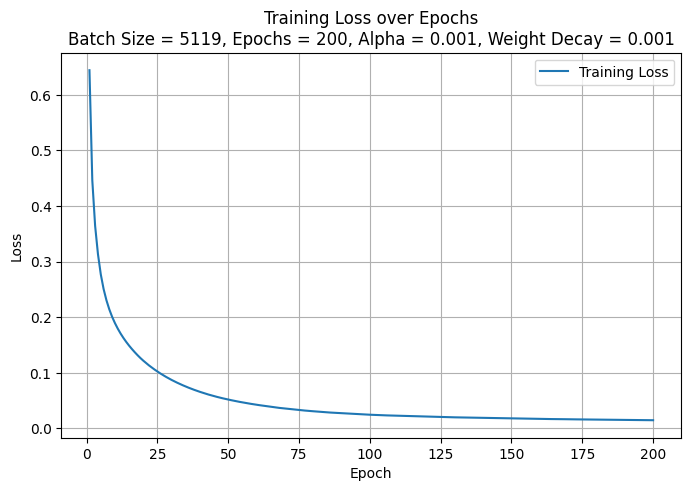

Train loss 0.0141 | Valid loss 0.5235
Valid ROC AUC: 0.953
              precision    recall  f1-score   support

           0      0.995     0.874     0.930     13892
           1      0.446     0.955     0.608      1475

    accuracy                          0.882     15367
   macro avg      0.720     0.915     0.769     15367
weighted avg      0.942     0.882     0.899     15367

[[12141  1751]
 [   66  1409]]


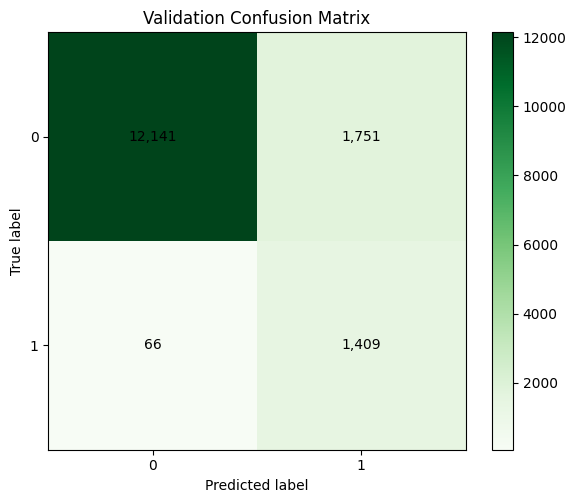

Iteration elapsed: 95.46s
 ==========     ==========     ==========     ==========
ITERATION [48/96]: 10:54:13 PM
    Batch Size:   10237
    Epochs:       50
    α:            0.01
    Weight Decay: 0.01
    
Epoch 1/50, Loss: 1.0413 | 0.010s
Epoch 2/50, Loss: 0.6361 | 0.012s
Epoch 3/50, Loss: 0.4146 | 0.010s
Epoch 4/50, Loss: 0.2393 | 0.010s
Epoch 5/50, Loss: 0.1810 | 0.011s
Epoch 6/50, Loss: 0.1754 | 0.010s
Epoch 7/50, Loss: 0.1526 | 0.010s
Epoch 8/50, Loss: 0.1451 | 0.010s
Epoch 9/50, Loss: 0.1342 | 0.011s
Epoch 10/50, Loss: 0.1247 | 0.013s
Epoch 11/50, Loss: 0.1170 | 0.010s
Epoch 12/50, Loss: 0.1124 | 0.011s
Epoch 13/50, Loss: 0.1083 | 0.010s
Epoch 14/50, Loss: 0.1041 | 0.011s
Epoch 15/50, Loss: 0.1006 | 0.010s
Epoch 16/50, Loss: 0.0966 | 0.012s
Epoch 17/50, Loss: 0.0935 | 0.010s
Epoch 18/50, Loss: 0.0901 | 0.010s
Epoch 19/50, Loss: 0.0872 | 0.010s
Epoch 20/50, Loss: 0.0842 | 0.010s
Epoch 21/50, Loss: 0.0817 | 0.012s
Epoch 22/50, Loss: 0.0791 | 0.010s
Epoch 23/50, Loss: 0.0768 | 0

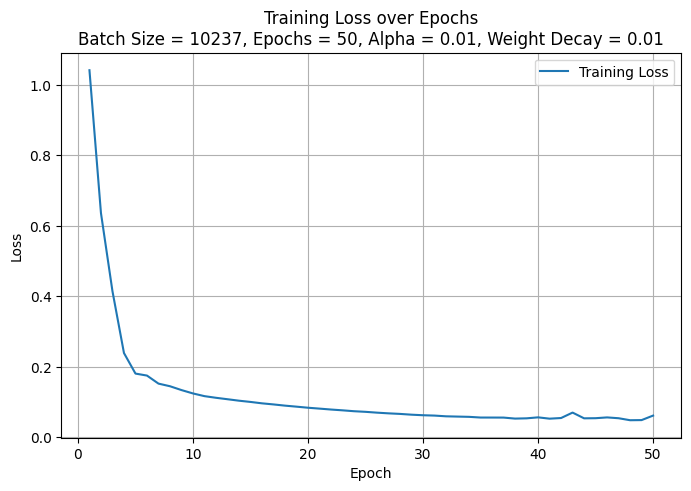

Train loss 0.0947 | Valid loss 0.4162
Valid ROC AUC: 0.971
              precision    recall  f1-score   support

           0      0.996     0.858     0.922     13892
           1      0.421     0.969     0.587      1475

    accuracy                          0.869     15367
   macro avg      0.708     0.914     0.754     15367
weighted avg      0.941     0.869     0.890     15367

[[11925  1967]
 [   46  1429]]


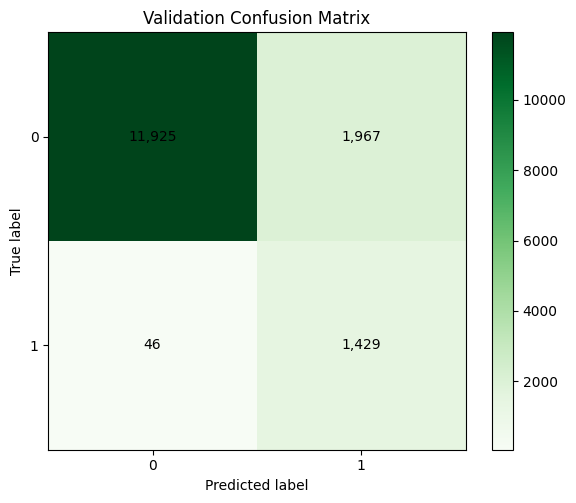

Iteration elapsed: 19.15s
 ==========     ==========     ==========     ==========
ITERATION [49/96]: 10:54:32 PM
    Batch Size:   10237
    Epochs:       50
    α:            0.01
    Weight Decay: 0.001
    
Epoch 1/50, Loss: 1.0403 | 0.010s
Epoch 2/50, Loss: 0.6353 | 0.011s
Epoch 3/50, Loss: 0.4079 | 0.010s
Epoch 4/50, Loss: 0.2460 | 0.009s
Epoch 5/50, Loss: 0.1785 | 0.010s
Epoch 6/50, Loss: 0.1793 | 0.011s
Epoch 7/50, Loss: 0.1525 | 0.010s
Epoch 8/50, Loss: 0.1443 | 0.010s
Epoch 9/50, Loss: 0.1325 | 0.010s
Epoch 10/50, Loss: 0.1240 | 0.010s
Epoch 11/50, Loss: 0.1146 | 0.010s
Epoch 12/50, Loss: 0.1090 | 0.013s
Epoch 13/50, Loss: 0.1040 | 0.010s
Epoch 14/50, Loss: 0.0985 | 0.011s
Epoch 15/50, Loss: 0.0942 | 0.010s
Epoch 16/50, Loss: 0.0896 | 0.010s
Epoch 17/50, Loss: 0.0849 | 0.009s
Epoch 18/50, Loss: 0.0812 | 0.010s
Epoch 19/50, Loss: 0.0777 | 0.010s
Epoch 20/50, Loss: 0.0744 | 0.011s
Epoch 21/50, Loss: 0.0714 | 0.018s
Epoch 22/50, Loss: 0.0684 | 0.011s
Epoch 23/50, Loss: 0.0656 | 

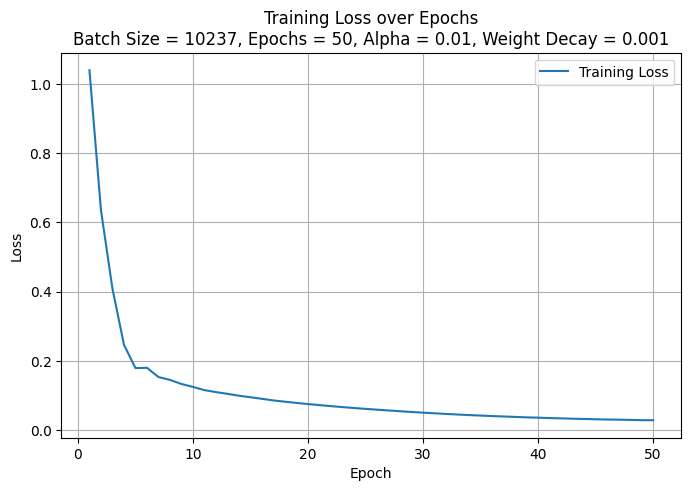

Train loss 0.0319 | Valid loss 0.4485
Valid ROC AUC: 0.964
              precision    recall  f1-score   support

           0      0.996     0.869     0.928     13892
           1      0.438     0.966     0.603      1475

    accuracy                          0.878     15367
   macro avg      0.717     0.917     0.765     15367
weighted avg      0.942     0.878     0.897     15367

[[12066  1826]
 [   50  1425]]


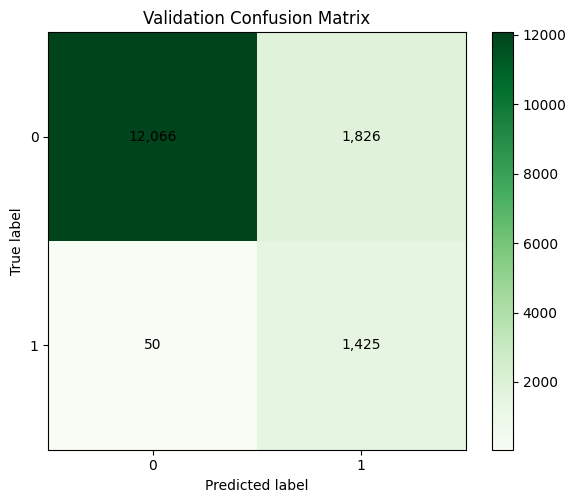

Iteration elapsed: 19.38s
 ==========     ==========     ==========     ==========
ITERATION [50/96]: 10:54:52 PM
    Batch Size:   10237
    Epochs:       50
    α:            0.001
    Weight Decay: 0.01
    
Epoch 1/50, Loss: 0.6580 | 0.010s
Epoch 2/50, Loss: 0.4894 | 0.011s
Epoch 3/50, Loss: 0.4097 | 0.010s
Epoch 4/50, Loss: 0.3559 | 0.010s
Epoch 5/50, Loss: 0.3180 | 0.010s
Epoch 6/50, Loss: 0.2889 | 0.010s
Epoch 7/50, Loss: 0.2664 | 0.010s
Epoch 8/50, Loss: 0.2487 | 0.010s
Epoch 9/50, Loss: 0.2343 | 0.010s
Epoch 10/50, Loss: 0.2223 | 0.010s
Epoch 11/50, Loss: 0.2120 | 0.010s
Epoch 12/50, Loss: 0.2029 | 0.011s
Epoch 13/50, Loss: 0.1947 | 0.010s
Epoch 14/50, Loss: 0.1874 | 0.013s
Epoch 15/50, Loss: 0.1808 | 0.010s
Epoch 16/50, Loss: 0.1748 | 0.010s
Epoch 17/50, Loss: 0.1693 | 0.010s
Epoch 18/50, Loss: 0.1642 | 0.010s
Epoch 19/50, Loss: 0.1595 | 0.010s
Epoch 20/50, Loss: 0.1552 | 0.010s
Epoch 21/50, Loss: 0.1510 | 0.010s
Epoch 22/50, Loss: 0.1472 | 0.010s
Epoch 23/50, Loss: 0.1435 | 

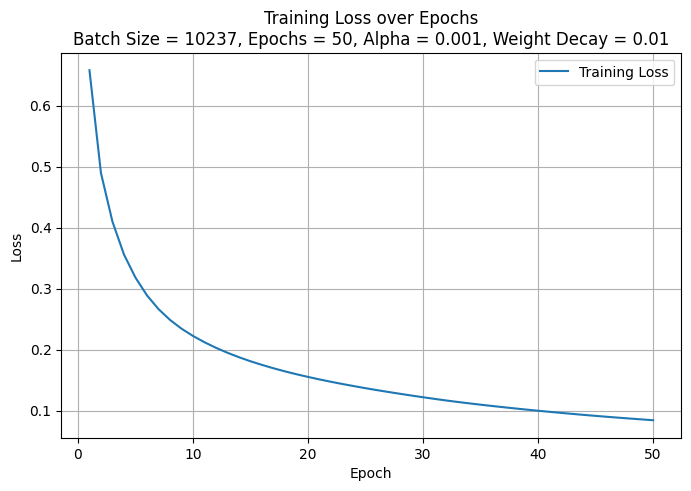

Train loss 0.0952 | Valid loss 0.3418
Valid ROC AUC: 0.956
              precision    recall  f1-score   support

           0      0.992     0.877     0.931     13892
           1      0.447     0.935     0.604      1475

    accuracy                          0.883     15367
   macro avg      0.719     0.906     0.768     15367
weighted avg      0.940     0.883     0.900     15367

[[12183  1709]
 [   96  1379]]


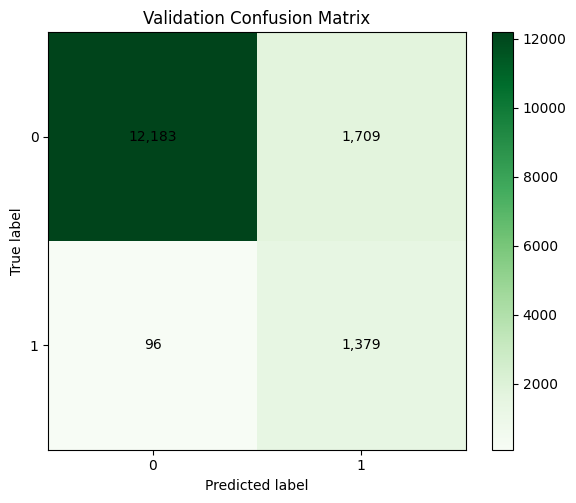

Iteration elapsed: 19.62s
 ==========     ==========     ==========     ==========
ITERATION [51/96]: 10:55:12 PM
    Batch Size:   10237
    Epochs:       50
    α:            0.001
    Weight Decay: 0.001
    
Epoch 1/50, Loss: 0.6581 | 0.010s
Epoch 2/50, Loss: 0.4888 | 0.010s
Epoch 3/50, Loss: 0.4088 | 0.010s
Epoch 4/50, Loss: 0.3546 | 0.010s
Epoch 5/50, Loss: 0.3165 | 0.010s
Epoch 6/50, Loss: 0.2872 | 0.010s
Epoch 7/50, Loss: 0.2646 | 0.010s
Epoch 8/50, Loss: 0.2467 | 0.010s
Epoch 9/50, Loss: 0.2323 | 0.010s
Epoch 10/50, Loss: 0.2202 | 0.010s
Epoch 11/50, Loss: 0.2098 | 0.010s
Epoch 12/50, Loss: 0.2006 | 0.010s
Epoch 13/50, Loss: 0.1923 | 0.010s
Epoch 14/50, Loss: 0.1849 | 0.012s
Epoch 15/50, Loss: 0.1781 | 0.010s
Epoch 16/50, Loss: 0.1719 | 0.010s
Epoch 17/50, Loss: 0.1662 | 0.010s
Epoch 18/50, Loss: 0.1609 | 0.010s
Epoch 19/50, Loss: 0.1560 | 0.012s
Epoch 20/50, Loss: 0.1514 | 0.010s
Epoch 21/50, Loss: 0.1471 | 0.010s
Epoch 22/50, Loss: 0.1430 | 0.012s
Epoch 23/50, Loss: 0.1392 |

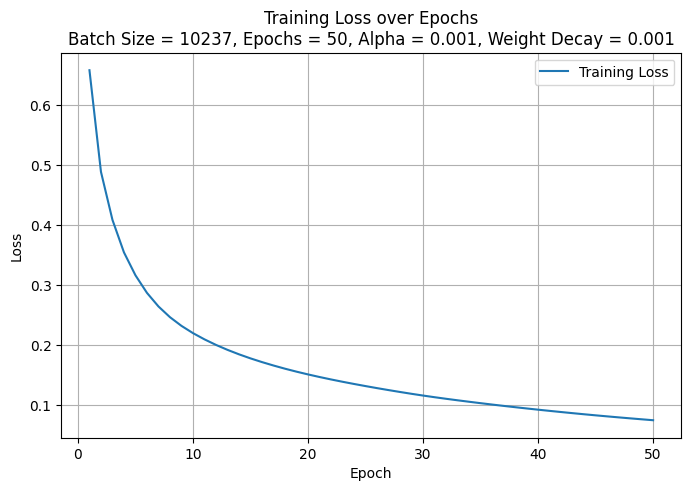

Train loss 0.0841 | Valid loss 0.3847
Valid ROC AUC: 0.956
              precision    recall  f1-score   support

           0      0.992     0.865     0.924     13892
           1      0.423     0.936     0.583      1475

    accuracy                          0.871     15367
   macro avg      0.708     0.900     0.753     15367
weighted avg      0.938     0.871     0.891     15367

[[12011  1881]
 [   95  1380]]


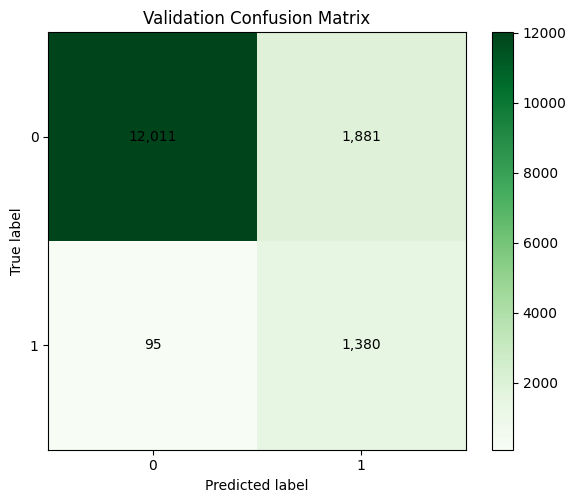

Iteration elapsed: 19.04s
 ==========     ==========     ==========     ==========
ITERATION [52/96]: 10:55:31 PM
    Batch Size:   10237
    Epochs:       100
    α:            0.01
    Weight Decay: 0.01
    
Epoch 1/100, Loss: 1.0413 | 0.010s
Epoch 2/100, Loss: 0.6361 | 0.012s
Epoch 3/100, Loss: 0.4146 | 0.009s
Epoch 4/100, Loss: 0.2393 | 0.010s
Epoch 5/100, Loss: 0.1810 | 0.010s
Epoch 6/100, Loss: 0.1754 | 0.011s
Epoch 7/100, Loss: 0.1526 | 0.010s
Epoch 8/100, Loss: 0.1451 | 0.009s
Epoch 9/100, Loss: 0.1342 | 0.011s
Epoch 10/100, Loss: 0.1247 | 0.011s
Epoch 11/100, Loss: 0.1170 | 0.010s
Epoch 12/100, Loss: 0.1124 | 0.010s
Epoch 13/100, Loss: 0.1083 | 0.012s
Epoch 14/100, Loss: 0.1041 | 0.013s
Epoch 15/100, Loss: 0.1006 | 0.010s
Epoch 16/100, Loss: 0.0966 | 0.010s
Epoch 17/100, Loss: 0.0935 | 0.010s
Epoch 18/100, Loss: 0.0901 | 0.010s
Epoch 19/100, Loss: 0.0872 | 0.010s
Epoch 20/100, Loss: 0.0842 | 0.010s
Epoch 21/100, Loss: 0.0817 | 0.010s
Epoch 22/100, Loss: 0.0791 | 0.010s
Epoch 

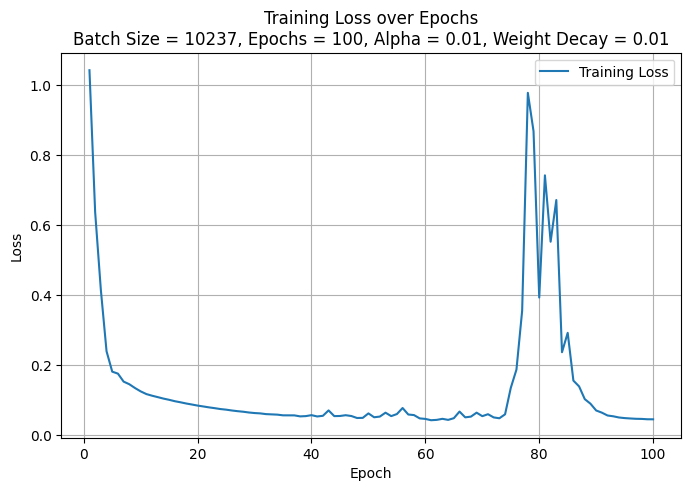

Train loss 0.0477 | Valid loss 0.3908
Valid ROC AUC: 0.967
              precision    recall  f1-score   support

           0      0.996     0.875     0.932     13892
           1      0.451     0.963     0.614      1475

    accuracy                          0.884     15367
   macro avg      0.723     0.919     0.773     15367
weighted avg      0.943     0.884     0.901     15367

[[12159  1733]
 [   54  1421]]


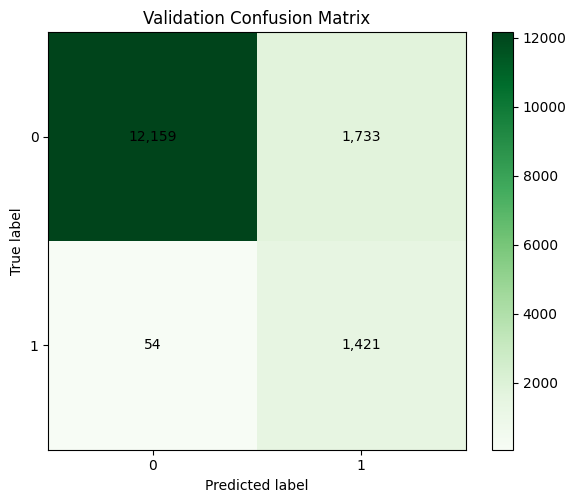

Iteration elapsed: 40.17s
 ==========     ==========     ==========     ==========
ITERATION [53/96]: 10:56:11 PM
    Batch Size:   10237
    Epochs:       100
    α:            0.01
    Weight Decay: 0.001
    
Epoch 1/100, Loss: 1.0403 | 0.010s
Epoch 2/100, Loss: 0.6353 | 0.010s
Epoch 3/100, Loss: 0.4079 | 0.010s
Epoch 4/100, Loss: 0.2460 | 0.010s
Epoch 5/100, Loss: 0.1785 | 0.010s
Epoch 6/100, Loss: 0.1793 | 0.013s
Epoch 7/100, Loss: 0.1525 | 0.010s
Epoch 8/100, Loss: 0.1443 | 0.010s
Epoch 9/100, Loss: 0.1325 | 0.011s
Epoch 10/100, Loss: 0.1240 | 0.010s
Epoch 11/100, Loss: 0.1146 | 0.010s
Epoch 12/100, Loss: 0.1090 | 0.013s
Epoch 13/100, Loss: 0.1040 | 0.012s
Epoch 14/100, Loss: 0.0985 | 0.011s
Epoch 15/100, Loss: 0.0942 | 0.010s
Epoch 16/100, Loss: 0.0896 | 0.010s
Epoch 17/100, Loss: 0.0849 | 0.010s
Epoch 18/100, Loss: 0.0812 | 0.010s
Epoch 19/100, Loss: 0.0777 | 0.010s
Epoch 20/100, Loss: 0.0744 | 0.011s
Epoch 21/100, Loss: 0.0714 | 0.010s
Epoch 22/100, Loss: 0.0684 | 0.010s
Epoch

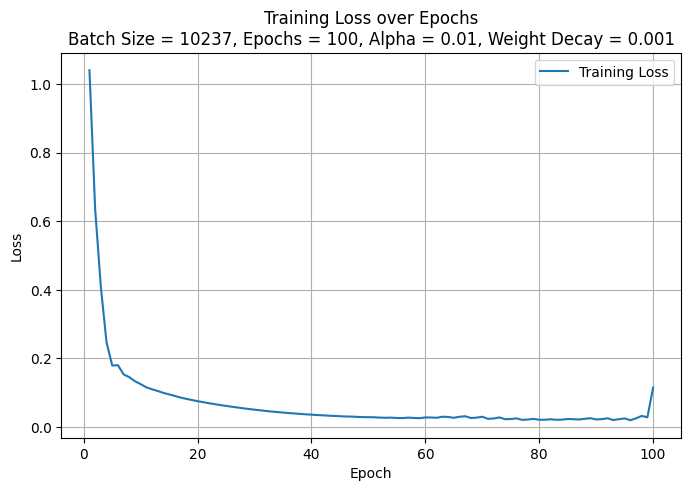

Train loss 0.0437 | Valid loss 0.4180
Valid ROC AUC: 0.904
              precision    recall  f1-score   support

           0      0.955     0.926     0.940     13892
           1      0.457     0.586     0.514      1475

    accuracy                          0.893     15367
   macro avg      0.706     0.756     0.727     15367
weighted avg      0.907     0.893     0.899     15367

[[12863  1029]
 [  610   865]]


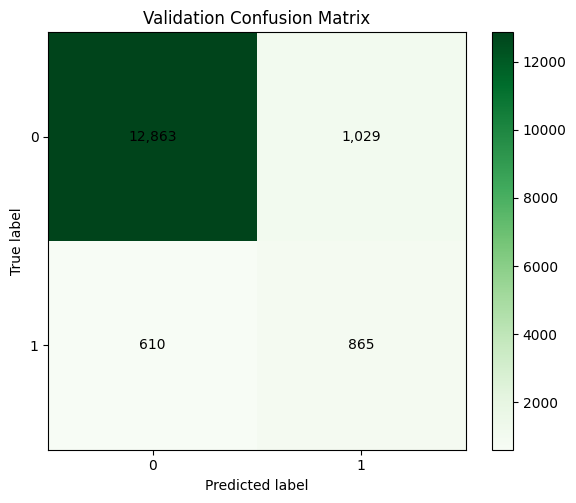

Iteration elapsed: 40.03s
 ==========     ==========     ==========     ==========
ITERATION [54/96]: 10:56:52 PM
    Batch Size:   10237
    Epochs:       100
    α:            0.001
    Weight Decay: 0.01
    
Epoch 1/100, Loss: 0.6580 | 0.010s
Epoch 2/100, Loss: 0.4894 | 0.010s
Epoch 3/100, Loss: 0.4097 | 0.010s
Epoch 4/100, Loss: 0.3559 | 0.010s
Epoch 5/100, Loss: 0.3180 | 0.010s
Epoch 6/100, Loss: 0.2889 | 0.012s
Epoch 7/100, Loss: 0.2664 | 0.011s
Epoch 8/100, Loss: 0.2487 | 0.011s
Epoch 9/100, Loss: 0.2343 | 0.010s
Epoch 10/100, Loss: 0.2223 | 0.010s
Epoch 11/100, Loss: 0.2120 | 0.013s
Epoch 12/100, Loss: 0.2029 | 0.010s
Epoch 13/100, Loss: 0.1947 | 0.010s
Epoch 14/100, Loss: 0.1874 | 0.013s
Epoch 15/100, Loss: 0.1808 | 0.010s
Epoch 16/100, Loss: 0.1748 | 0.011s
Epoch 17/100, Loss: 0.1693 | 0.010s
Epoch 18/100, Loss: 0.1642 | 0.010s
Epoch 19/100, Loss: 0.1595 | 0.010s
Epoch 20/100, Loss: 0.1552 | 0.010s
Epoch 21/100, Loss: 0.1510 | 0.013s
Epoch 22/100, Loss: 0.1472 | 0.011s
Epoch

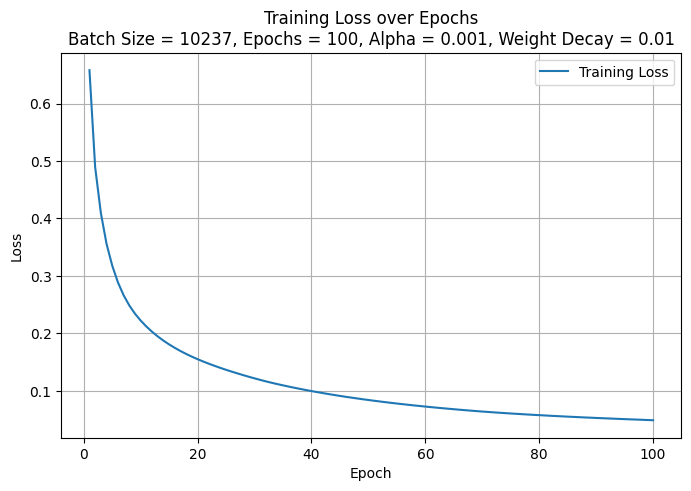

Train loss 0.0553 | Valid loss 0.3246
Valid ROC AUC: 0.964
              precision    recall  f1-score   support

           0      0.994     0.878     0.933     13892
           1      0.454     0.951     0.614      1475

    accuracy                          0.885     15367
   macro avg      0.724     0.915     0.773     15367
weighted avg      0.942     0.885     0.902     15367

[[12202  1690]
 [   72  1403]]


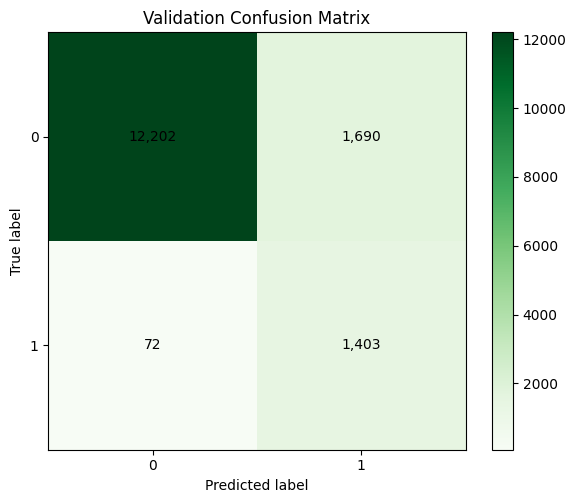

Iteration elapsed: 41.28s
 ==========     ==========     ==========     ==========
ITERATION [55/96]: 10:57:33 PM
    Batch Size:   10237
    Epochs:       100
    α:            0.001
    Weight Decay: 0.001
    
Epoch 1/100, Loss: 0.6581 | 0.011s
Epoch 2/100, Loss: 0.4888 | 0.010s
Epoch 3/100, Loss: 0.4088 | 0.011s
Epoch 4/100, Loss: 0.3546 | 0.010s
Epoch 5/100, Loss: 0.3165 | 0.010s
Epoch 6/100, Loss: 0.2872 | 0.011s
Epoch 7/100, Loss: 0.2646 | 0.010s
Epoch 8/100, Loss: 0.2467 | 0.010s
Epoch 9/100, Loss: 0.2323 | 0.010s
Epoch 10/100, Loss: 0.2202 | 0.010s
Epoch 11/100, Loss: 0.2098 | 0.010s
Epoch 12/100, Loss: 0.2006 | 0.011s
Epoch 13/100, Loss: 0.1923 | 0.011s
Epoch 14/100, Loss: 0.1849 | 0.010s
Epoch 15/100, Loss: 0.1781 | 0.011s
Epoch 16/100, Loss: 0.1719 | 0.011s
Epoch 17/100, Loss: 0.1662 | 0.018s
Epoch 18/100, Loss: 0.1609 | 0.010s
Epoch 19/100, Loss: 0.1560 | 0.011s
Epoch 20/100, Loss: 0.1514 | 0.010s
Epoch 21/100, Loss: 0.1471 | 0.010s
Epoch 22/100, Loss: 0.1430 | 0.010s
Epoc

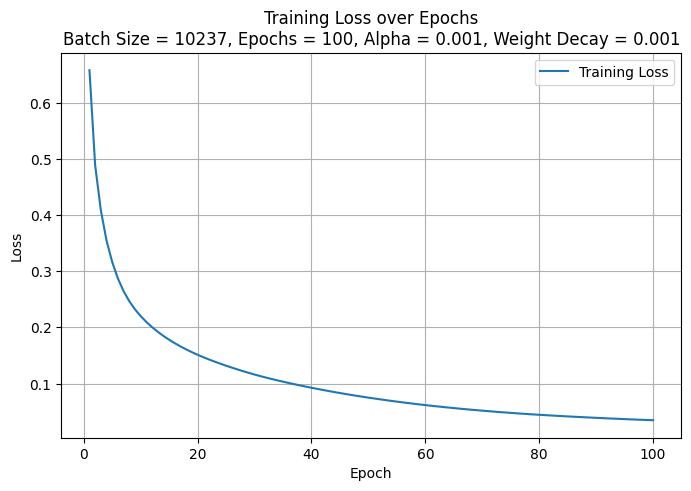

Train loss 0.0390 | Valid loss 0.4102
Valid ROC AUC: 0.963
              precision    recall  f1-score   support

           0      0.994     0.872     0.929     13892
           1      0.441     0.951     0.602      1475

    accuracy                          0.879     15367
   macro avg      0.717     0.911     0.766     15367
weighted avg      0.941     0.879     0.898     15367

[[12113  1779]
 [   73  1402]]


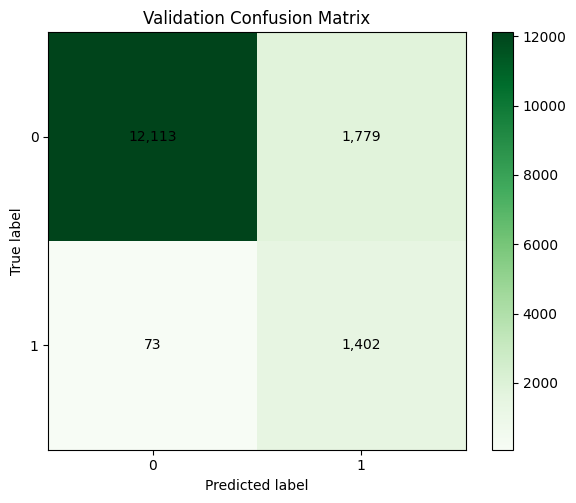

Iteration elapsed: 41.84s
 ==========     ==========     ==========     ==========
ITERATION [56/96]: 10:58:15 PM
    Batch Size:   10237
    Epochs:       150
    α:            0.01
    Weight Decay: 0.01
    
Epoch 1/150, Loss: 1.0413 | 0.011s
Epoch 2/150, Loss: 0.6361 | 0.011s
Epoch 3/150, Loss: 0.4146 | 0.010s
Epoch 4/150, Loss: 0.2393 | 0.011s
Epoch 5/150, Loss: 0.1810 | 0.010s
Epoch 6/150, Loss: 0.1754 | 0.009s
Epoch 7/150, Loss: 0.1526 | 0.010s
Epoch 8/150, Loss: 0.1451 | 0.010s
Epoch 9/150, Loss: 0.1342 | 0.011s
Epoch 10/150, Loss: 0.1247 | 0.012s
Epoch 11/150, Loss: 0.1170 | 0.010s
Epoch 12/150, Loss: 0.1124 | 0.010s
Epoch 13/150, Loss: 0.1083 | 0.010s
Epoch 14/150, Loss: 0.1041 | 0.010s
Epoch 15/150, Loss: 0.1006 | 0.010s
Epoch 16/150, Loss: 0.0966 | 0.010s
Epoch 17/150, Loss: 0.0935 | 0.010s
Epoch 18/150, Loss: 0.0901 | 0.013s
Epoch 19/150, Loss: 0.0872 | 0.012s
Epoch 20/150, Loss: 0.0842 | 0.010s
Epoch 21/150, Loss: 0.0817 | 0.010s
Epoch 22/150, Loss: 0.0791 | 0.010s
Epoch 

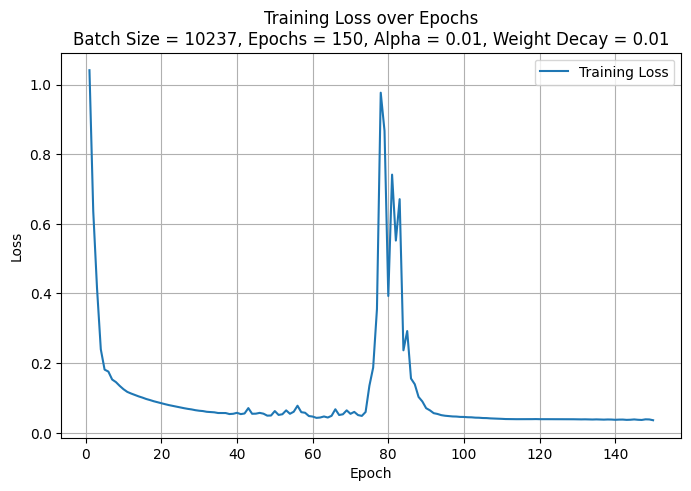

Train loss 0.0358 | Valid loss 0.2900
Valid ROC AUC: 0.963
              precision    recall  f1-score   support

           0      0.995     0.878     0.933     13892
           1      0.455     0.957     0.617      1475

    accuracy                          0.886     15367
   macro avg      0.725     0.918     0.775     15367
weighted avg      0.943     0.886     0.903     15367

[[12204  1688]
 [   64  1411]]


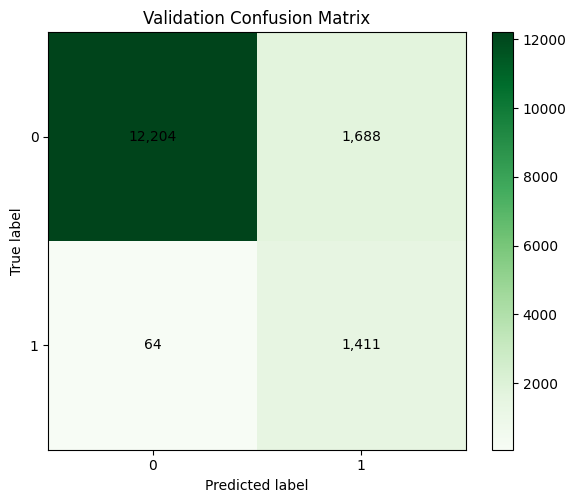

Iteration elapsed: 60.20s
 ==========     ==========     ==========     ==========
ITERATION [57/96]: 10:59:16 PM
    Batch Size:   10237
    Epochs:       150
    α:            0.01
    Weight Decay: 0.001
    
Epoch 1/150, Loss: 1.0403 | 0.010s
Epoch 2/150, Loss: 0.6353 | 0.011s
Epoch 3/150, Loss: 0.4079 | 0.010s
Epoch 4/150, Loss: 0.2460 | 0.010s
Epoch 5/150, Loss: 0.1785 | 0.013s
Epoch 6/150, Loss: 0.1793 | 0.010s
Epoch 7/150, Loss: 0.1525 | 0.010s
Epoch 8/150, Loss: 0.1443 | 0.010s
Epoch 9/150, Loss: 0.1325 | 0.010s
Epoch 10/150, Loss: 0.1240 | 0.010s
Epoch 11/150, Loss: 0.1146 | 0.010s
Epoch 12/150, Loss: 0.1090 | 0.010s
Epoch 13/150, Loss: 0.1040 | 0.010s
Epoch 14/150, Loss: 0.0985 | 0.010s
Epoch 15/150, Loss: 0.0942 | 0.010s
Epoch 16/150, Loss: 0.0896 | 0.010s
Epoch 17/150, Loss: 0.0849 | 0.010s
Epoch 18/150, Loss: 0.0812 | 0.011s
Epoch 19/150, Loss: 0.0777 | 0.010s
Epoch 20/150, Loss: 0.0744 | 0.010s
Epoch 21/150, Loss: 0.0714 | 0.010s
Epoch 22/150, Loss: 0.0684 | 0.010s
Epoch

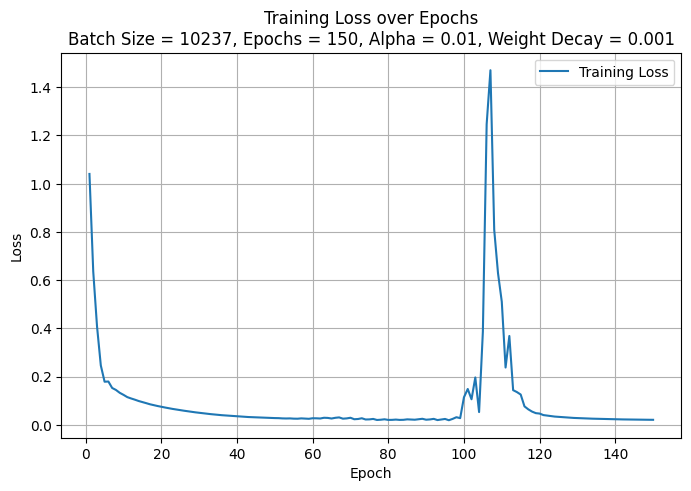

Train loss 0.0197 | Valid loss 0.6176
Valid ROC AUC: 0.952
              precision    recall  f1-score   support

           0      0.994     0.873     0.930     13892
           1      0.443     0.952     0.605      1475

    accuracy                          0.881     15367
   macro avg      0.719     0.912     0.767     15367
weighted avg      0.941     0.881     0.898     15367

[[12127  1765]
 [   71  1404]]


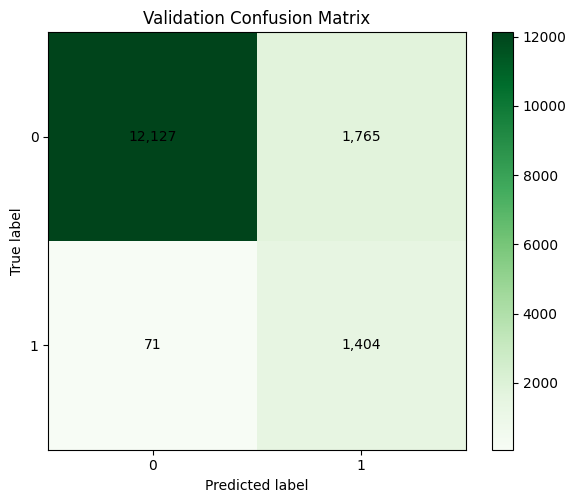

Iteration elapsed: 59.16s
 ==========     ==========     ==========     ==========
ITERATION [58/96]: 11:00:15 PM
    Batch Size:   10237
    Epochs:       150
    α:            0.001
    Weight Decay: 0.01
    
Epoch 1/150, Loss: 0.6580 | 0.014s
Epoch 2/150, Loss: 0.4894 | 0.006s
Epoch 3/150, Loss: 0.4097 | 0.008s
Epoch 4/150, Loss: 0.3559 | 0.007s
Epoch 5/150, Loss: 0.3180 | 0.019s
Epoch 6/150, Loss: 0.2889 | 0.013s
Epoch 7/150, Loss: 0.2664 | 0.006s
Epoch 8/150, Loss: 0.2487 | 0.011s
Epoch 9/150, Loss: 0.2343 | 0.011s
Epoch 10/150, Loss: 0.2223 | 0.006s
Epoch 11/150, Loss: 0.2120 | 0.006s
Epoch 12/150, Loss: 0.2029 | 0.013s
Epoch 13/150, Loss: 0.1947 | 0.013s
Epoch 14/150, Loss: 0.1874 | 0.014s
Epoch 15/150, Loss: 0.1808 | 0.014s
Epoch 16/150, Loss: 0.1748 | 0.005s
Epoch 17/150, Loss: 0.1693 | 0.004s
Epoch 18/150, Loss: 0.1642 | 0.006s
Epoch 19/150, Loss: 0.1595 | 0.005s
Epoch 20/150, Loss: 0.1552 | 0.003s
Epoch 21/150, Loss: 0.1510 | 0.004s
Epoch 22/150, Loss: 0.1472 | 0.006s
Epoch

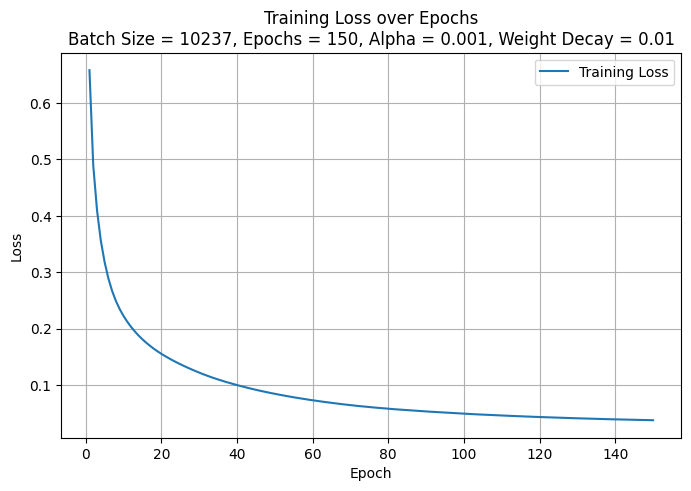

Train loss 0.0417 | Valid loss 0.3282
Valid ROC AUC: 0.964
              precision    recall  f1-score   support

           0      0.995     0.876     0.932     13892
           1      0.451     0.956     0.613      1475

    accuracy                          0.884     15367
   macro avg      0.723     0.916     0.772     15367
weighted avg      0.942     0.884     0.901     15367

[[12175  1717]
 [   65  1410]]


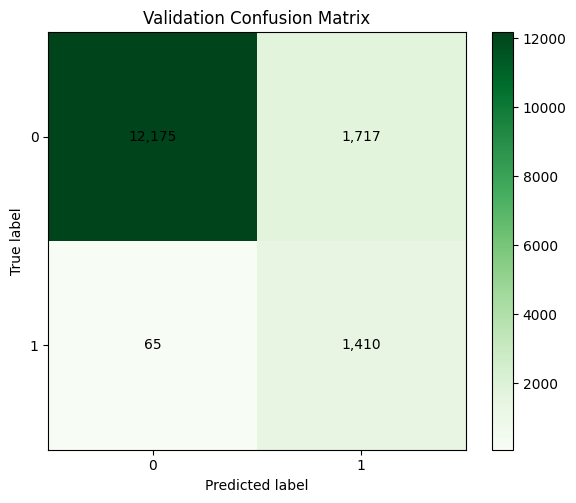

Iteration elapsed: 53.83s
 ==========     ==========     ==========     ==========
ITERATION [59/96]: 11:01:09 PM
    Batch Size:   10237
    Epochs:       150
    α:            0.001
    Weight Decay: 0.001
    
Epoch 1/150, Loss: 0.6581 | 0.007s
Epoch 2/150, Loss: 0.4888 | 0.004s
Epoch 3/150, Loss: 0.4088 | 0.008s
Epoch 4/150, Loss: 0.3546 | 0.007s
Epoch 5/150, Loss: 0.3165 | 0.007s
Epoch 6/150, Loss: 0.2872 | 0.014s
Epoch 7/150, Loss: 0.2646 | 0.006s
Epoch 8/150, Loss: 0.2467 | 0.006s
Epoch 9/150, Loss: 0.2323 | 0.017s
Epoch 10/150, Loss: 0.2202 | 0.008s
Epoch 11/150, Loss: 0.2098 | 0.006s
Epoch 12/150, Loss: 0.2006 | 0.012s
Epoch 13/150, Loss: 0.1923 | 0.013s
Epoch 14/150, Loss: 0.1849 | 0.006s
Epoch 15/150, Loss: 0.1781 | 0.007s
Epoch 16/150, Loss: 0.1719 | 0.006s
Epoch 17/150, Loss: 0.1662 | 0.014s
Epoch 18/150, Loss: 0.1609 | 0.006s
Epoch 19/150, Loss: 0.1560 | 0.007s
Epoch 20/150, Loss: 0.1514 | 0.006s
Epoch 21/150, Loss: 0.1471 | 0.005s
Epoch 22/150, Loss: 0.1430 | 0.004s
Epoc

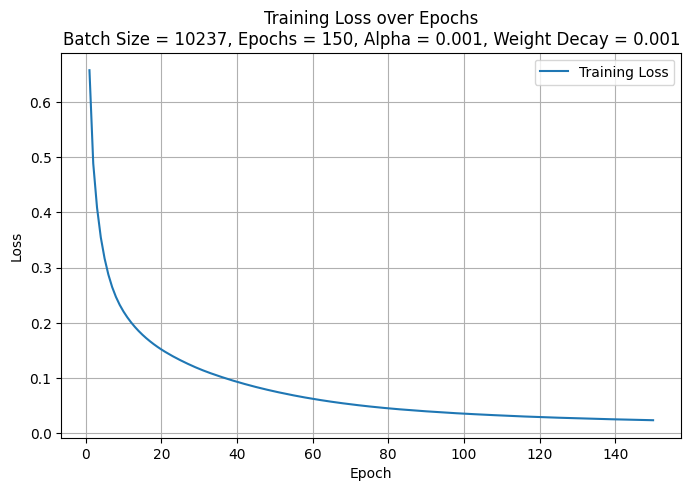

Train loss 0.0247 | Valid loss 0.4339
Valid ROC AUC: 0.960
              precision    recall  f1-score   support

           0      0.995     0.874     0.930     13892
           1      0.446     0.957     0.609      1475

    accuracy                          0.882     15367
   macro avg      0.721     0.916     0.770     15367
weighted avg      0.942     0.882     0.900     15367

[[12140  1752]
 [   63  1412]]


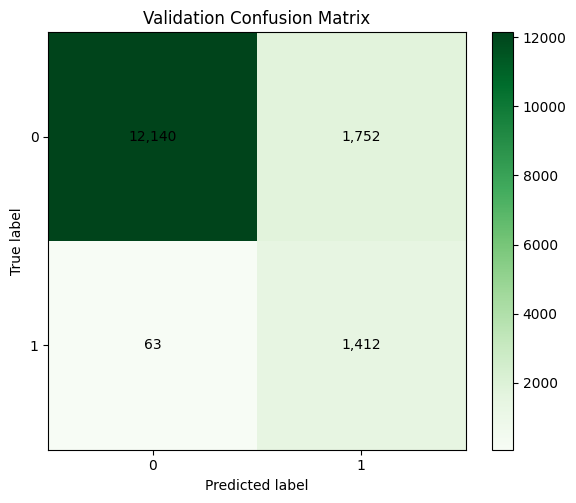

Iteration elapsed: 52.71s
 ==========     ==========     ==========     ==========
ITERATION [60/96]: 11:02:02 PM
    Batch Size:   10237
    Epochs:       200
    α:            0.01
    Weight Decay: 0.01
    
Epoch 1/200, Loss: 1.0413 | 0.013s
Epoch 2/200, Loss: 0.6361 | 0.006s
Epoch 3/200, Loss: 0.4146 | 0.007s
Epoch 4/200, Loss: 0.2393 | 0.004s
Epoch 5/200, Loss: 0.1810 | 0.008s
Epoch 6/200, Loss: 0.1754 | 0.004s
Epoch 7/200, Loss: 0.1526 | 0.004s
Epoch 8/200, Loss: 0.1451 | 0.007s
Epoch 9/200, Loss: 0.1342 | 0.005s
Epoch 10/200, Loss: 0.1247 | 0.005s
Epoch 11/200, Loss: 0.1170 | 0.006s
Epoch 12/200, Loss: 0.1124 | 0.008s
Epoch 13/200, Loss: 0.1083 | 0.011s
Epoch 14/200, Loss: 0.1041 | 0.015s
Epoch 15/200, Loss: 0.1006 | 0.008s
Epoch 16/200, Loss: 0.0966 | 0.009s
Epoch 17/200, Loss: 0.0935 | 0.012s
Epoch 18/200, Loss: 0.0901 | 0.006s
Epoch 19/200, Loss: 0.0872 | 0.006s
Epoch 20/200, Loss: 0.0842 | 0.014s
Epoch 21/200, Loss: 0.0817 | 0.008s
Epoch 22/200, Loss: 0.0791 | 0.006s
Epoch 

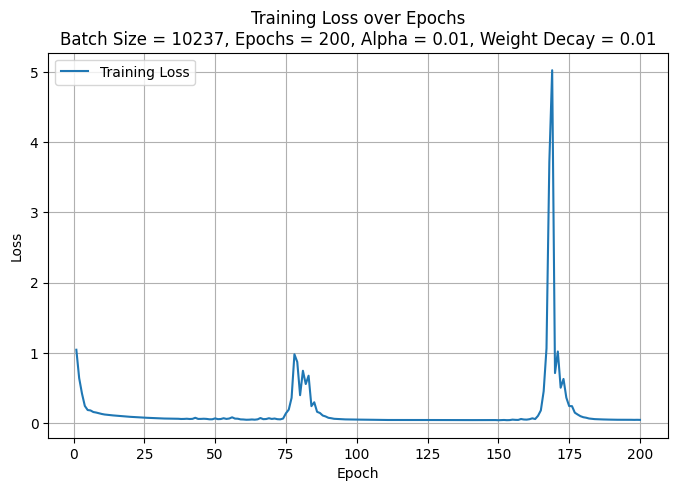

Train loss 0.0407 | Valid loss 0.4044
Valid ROC AUC: 0.963
              precision    recall  f1-score   support

           0      0.996     0.871     0.929     13892
           1      0.442     0.964     0.606      1475

    accuracy                          0.880     15367
   macro avg      0.719     0.917     0.767     15367
weighted avg      0.942     0.880     0.898     15367

[[12094  1798]
 [   53  1422]]


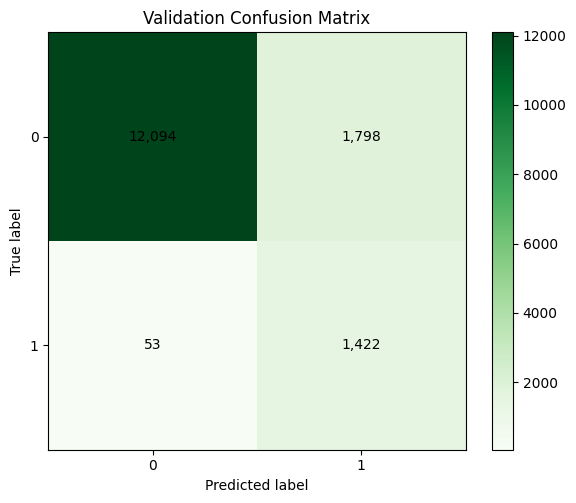

Iteration elapsed: 71.76s
 ==========     ==========     ==========     ==========
ITERATION [61/96]: 11:03:14 PM
    Batch Size:   10237
    Epochs:       200
    α:            0.01
    Weight Decay: 0.001
    
Epoch 1/200, Loss: 1.0403 | 0.005s
Epoch 2/200, Loss: 0.6353 | 0.007s
Epoch 3/200, Loss: 0.4079 | 0.008s
Epoch 4/200, Loss: 0.2460 | 0.004s
Epoch 5/200, Loss: 0.1785 | 0.006s
Epoch 6/200, Loss: 0.1793 | 0.007s
Epoch 7/200, Loss: 0.1525 | 0.009s
Epoch 8/200, Loss: 0.1443 | 0.013s
Epoch 9/200, Loss: 0.1325 | 0.007s
Epoch 10/200, Loss: 0.1240 | 0.006s
Epoch 11/200, Loss: 0.1146 | 0.006s
Epoch 12/200, Loss: 0.1090 | 0.004s
Epoch 13/200, Loss: 0.1040 | 0.004s
Epoch 14/200, Loss: 0.0985 | 0.003s
Epoch 15/200, Loss: 0.0942 | 0.003s
Epoch 16/200, Loss: 0.0896 | 0.004s
Epoch 17/200, Loss: 0.0849 | 0.004s
Epoch 18/200, Loss: 0.0812 | 0.006s
Epoch 19/200, Loss: 0.0777 | 0.011s
Epoch 20/200, Loss: 0.0744 | 0.007s
Epoch 21/200, Loss: 0.0714 | 0.009s
Epoch 22/200, Loss: 0.0684 | 0.014s
Epoch

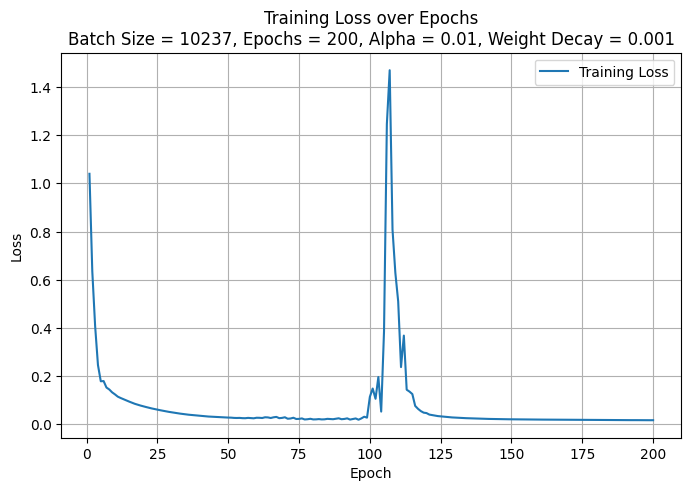

Train loss 0.0172 | Valid loss 0.5737
Valid ROC AUC: 0.949
              precision    recall  f1-score   support

           0      0.994     0.872     0.929     13892
           1      0.441     0.954     0.603      1475

    accuracy                          0.879     15367
   macro avg      0.718     0.913     0.766     15367
weighted avg      0.941     0.879     0.898     15367

[[12108  1784]
 [   68  1407]]


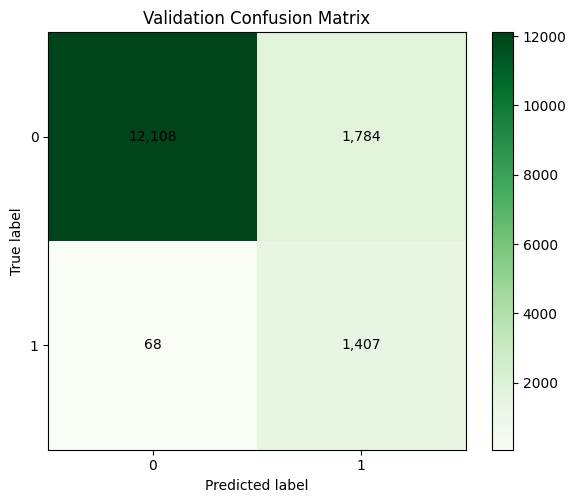

Iteration elapsed: 71.17s
 ==========     ==========     ==========     ==========
ITERATION [62/96]: 11:04:26 PM
    Batch Size:   10237
    Epochs:       200
    α:            0.001
    Weight Decay: 0.01
    
Epoch 1/200, Loss: 0.6580 | 0.012s
Epoch 2/200, Loss: 0.4894 | 0.006s
Epoch 3/200, Loss: 0.4097 | 0.006s
Epoch 4/200, Loss: 0.3559 | 0.006s
Epoch 5/200, Loss: 0.3180 | 0.006s
Epoch 6/200, Loss: 0.2889 | 0.009s
Epoch 7/200, Loss: 0.2664 | 0.008s
Epoch 8/200, Loss: 0.2487 | 0.006s
Epoch 9/200, Loss: 0.2343 | 0.006s
Epoch 10/200, Loss: 0.2223 | 0.006s
Epoch 11/200, Loss: 0.2120 | 0.011s
Epoch 12/200, Loss: 0.2029 | 0.006s
Epoch 13/200, Loss: 0.1947 | 0.006s
Epoch 14/200, Loss: 0.1874 | 0.010s
Epoch 15/200, Loss: 0.1808 | 0.014s
Epoch 16/200, Loss: 0.1748 | 0.006s
Epoch 17/200, Loss: 0.1693 | 0.008s
Epoch 18/200, Loss: 0.1642 | 0.006s
Epoch 19/200, Loss: 0.1595 | 0.017s
Epoch 20/200, Loss: 0.1552 | 0.007s
Epoch 21/200, Loss: 0.1510 | 0.016s
Epoch 22/200, Loss: 0.1472 | 0.007s
Epoch

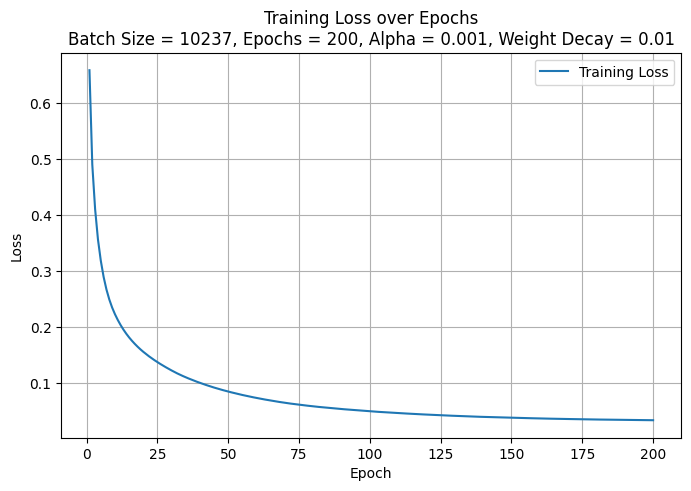

Train loss 0.0370 | Valid loss 0.3358
Valid ROC AUC: 0.963
              precision    recall  f1-score   support

           0      0.995     0.874     0.931     13892
           1      0.448     0.959     0.610      1475

    accuracy                          0.882     15367
   macro avg      0.721     0.917     0.771     15367
weighted avg      0.943     0.882     0.900     15367

[[12146  1746]
 [   60  1415]]


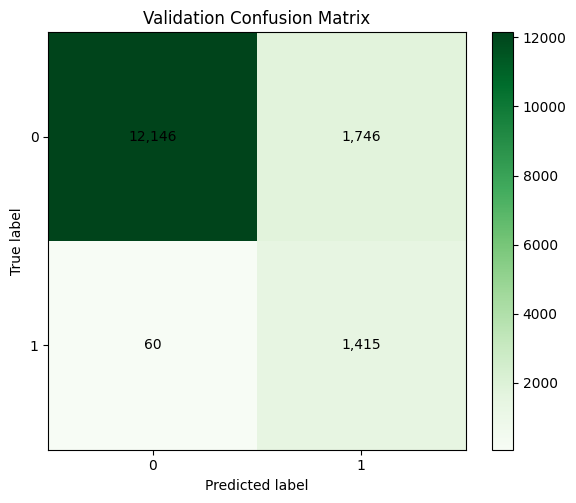

Iteration elapsed: 70.88s
 ==========     ==========     ==========     ==========
ITERATION [63/96]: 11:05:37 PM
    Batch Size:   10237
    Epochs:       200
    α:            0.001
    Weight Decay: 0.001
    
Epoch 1/200, Loss: 0.6581 | 0.006s
Epoch 2/200, Loss: 0.4888 | 0.008s
Epoch 3/200, Loss: 0.4088 | 0.006s
Epoch 4/200, Loss: 0.3546 | 0.006s
Epoch 5/200, Loss: 0.3165 | 0.015s
Epoch 6/200, Loss: 0.2872 | 0.007s
Epoch 7/200, Loss: 0.2646 | 0.007s
Epoch 8/200, Loss: 0.2467 | 0.013s
Epoch 9/200, Loss: 0.2323 | 0.007s
Epoch 10/200, Loss: 0.2202 | 0.010s
Epoch 11/200, Loss: 0.2098 | 0.006s
Epoch 12/200, Loss: 0.2006 | 0.007s
Epoch 13/200, Loss: 0.1923 | 0.006s
Epoch 14/200, Loss: 0.1849 | 0.007s
Epoch 15/200, Loss: 0.1781 | 0.007s
Epoch 16/200, Loss: 0.1719 | 0.006s
Epoch 17/200, Loss: 0.1662 | 0.007s
Epoch 18/200, Loss: 0.1609 | 0.006s
Epoch 19/200, Loss: 0.1560 | 0.015s
Epoch 20/200, Loss: 0.1514 | 0.006s
Epoch 21/200, Loss: 0.1471 | 0.012s
Epoch 22/200, Loss: 0.1430 | 0.006s
Epoc

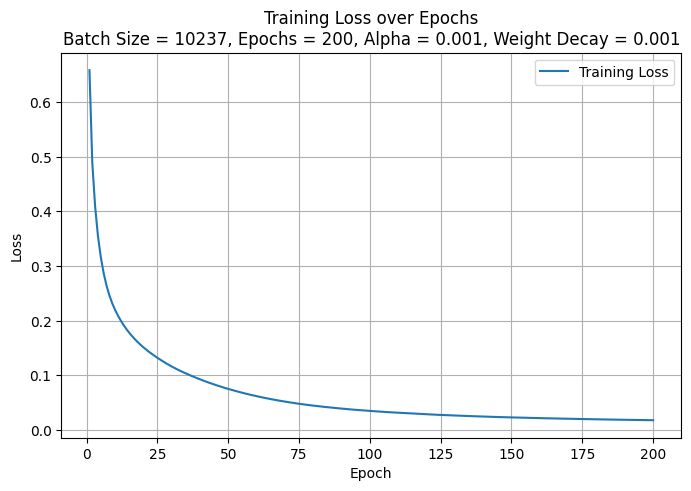

Train loss 0.0185 | Valid loss 0.4543
Valid ROC AUC: 0.957
              precision    recall  f1-score   support

           0      0.994     0.875     0.931     13892
           1      0.448     0.953     0.609      1475

    accuracy                          0.883     15367
   macro avg      0.721     0.914     0.770     15367
weighted avg      0.942     0.883     0.900     15367

[[12159  1733]
 [   69  1406]]


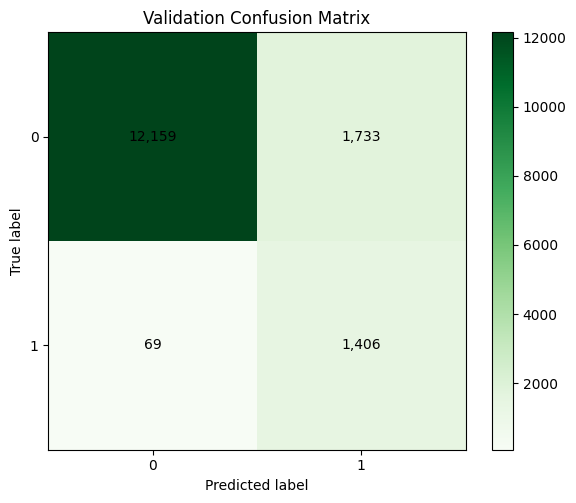

Iteration elapsed: 72.05s
 ==========     ==========     ==========     ==========
ITERATION [64/96]: 11:06:49 PM
    Batch Size:   10237
    Epochs:       50
    α:            0.01
    Weight Decay: 0.01
    
Epoch 1/50, Loss: 1.0413 | 0.006s
Epoch 2/50, Loss: 0.6361 | 0.019s
Epoch 3/50, Loss: 0.4146 | 0.007s
Epoch 4/50, Loss: 0.2393 | 0.006s
Epoch 5/50, Loss: 0.1810 | 0.014s
Epoch 6/50, Loss: 0.1754 | 0.004s
Epoch 7/50, Loss: 0.1526 | 0.005s
Epoch 8/50, Loss: 0.1451 | 0.004s
Epoch 9/50, Loss: 0.1342 | 0.004s
Epoch 10/50, Loss: 0.1247 | 0.006s
Epoch 11/50, Loss: 0.1170 | 0.006s
Epoch 12/50, Loss: 0.1124 | 0.006s
Epoch 13/50, Loss: 0.1083 | 0.007s
Epoch 14/50, Loss: 0.1041 | 0.007s
Epoch 15/50, Loss: 0.1006 | 0.011s
Epoch 16/50, Loss: 0.0966 | 0.003s
Epoch 17/50, Loss: 0.0935 | 0.005s
Epoch 18/50, Loss: 0.0901 | 0.005s
Epoch 19/50, Loss: 0.0872 | 0.006s
Epoch 20/50, Loss: 0.0842 | 0.003s
Epoch 21/50, Loss: 0.0817 | 0.007s
Epoch 22/50, Loss: 0.0791 | 0.010s
Epoch 23/50, Loss: 0.0768 | 0

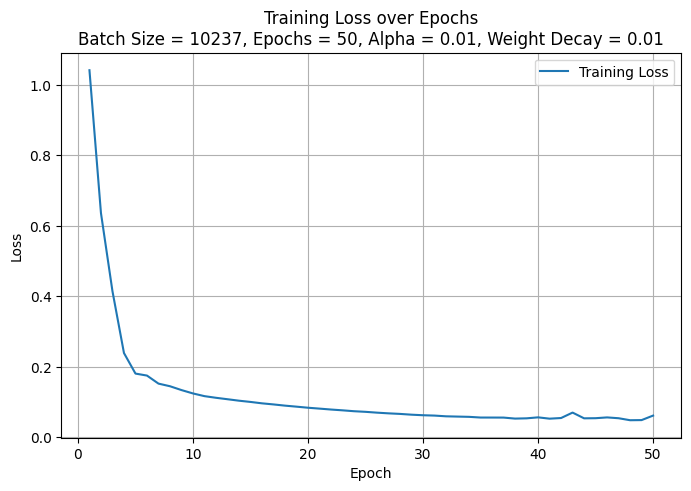

Train loss 0.0947 | Valid loss 0.4162
Valid ROC AUC: 0.971
              precision    recall  f1-score   support

           0      0.996     0.858     0.922     13892
           1      0.421     0.969     0.587      1475

    accuracy                          0.869     15367
   macro avg      0.708     0.914     0.754     15367
weighted avg      0.941     0.869     0.890     15367

[[11925  1967]
 [   46  1429]]


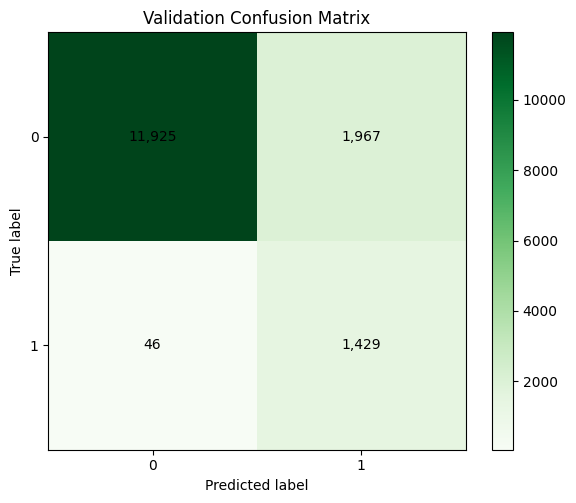

Iteration elapsed: 18.52s
 ==========     ==========     ==========     ==========
ITERATION [65/96]: 11:07:08 PM
    Batch Size:   10237
    Epochs:       50
    α:            0.01
    Weight Decay: 0.001
    
Epoch 1/50, Loss: 1.0403 | 0.008s
Epoch 2/50, Loss: 0.6353 | 0.004s
Epoch 3/50, Loss: 0.4079 | 0.007s
Epoch 4/50, Loss: 0.2460 | 0.007s
Epoch 5/50, Loss: 0.1785 | 0.006s
Epoch 6/50, Loss: 0.1793 | 0.014s
Epoch 7/50, Loss: 0.1525 | 0.008s
Epoch 8/50, Loss: 0.1443 | 0.007s
Epoch 9/50, Loss: 0.1325 | 0.007s
Epoch 10/50, Loss: 0.1240 | 0.006s
Epoch 11/50, Loss: 0.1146 | 0.015s
Epoch 12/50, Loss: 0.1090 | 0.009s
Epoch 13/50, Loss: 0.1040 | 0.010s
Epoch 14/50, Loss: 0.0985 | 0.007s
Epoch 15/50, Loss: 0.0942 | 0.007s
Epoch 16/50, Loss: 0.0896 | 0.006s
Epoch 17/50, Loss: 0.0849 | 0.007s
Epoch 18/50, Loss: 0.0812 | 0.006s
Epoch 19/50, Loss: 0.0777 | 0.004s
Epoch 20/50, Loss: 0.0744 | 0.004s
Epoch 21/50, Loss: 0.0714 | 0.007s
Epoch 22/50, Loss: 0.0684 | 0.007s
Epoch 23/50, Loss: 0.0656 | 

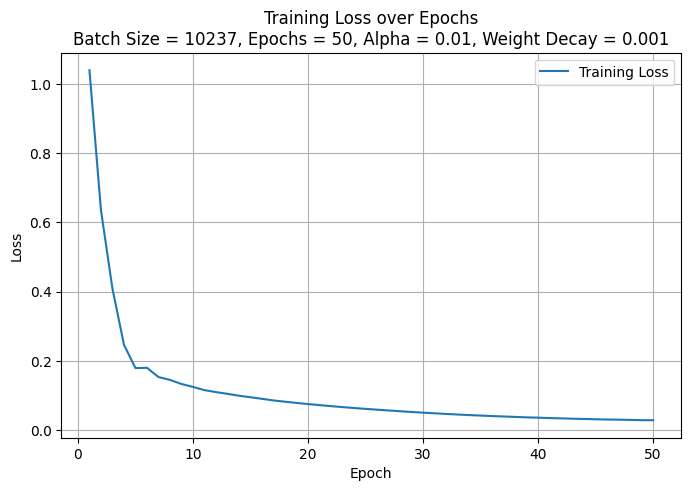

Train loss 0.0319 | Valid loss 0.4485
Valid ROC AUC: 0.964
              precision    recall  f1-score   support

           0      0.996     0.869     0.928     13892
           1      0.438     0.966     0.603      1475

    accuracy                          0.878     15367
   macro avg      0.717     0.917     0.765     15367
weighted avg      0.942     0.878     0.897     15367

[[12066  1826]
 [   50  1425]]


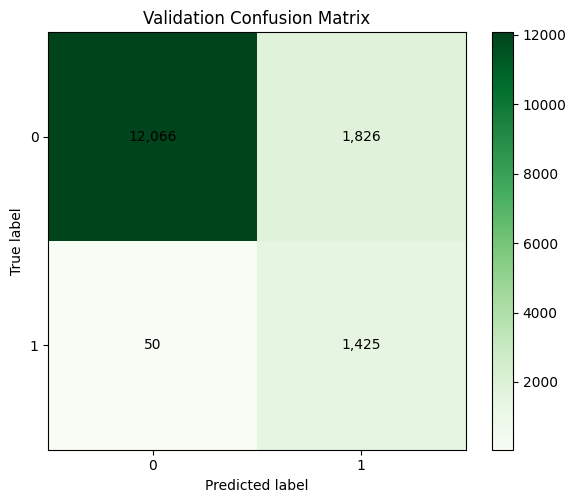

Iteration elapsed: 18.64s
 ==========     ==========     ==========     ==========
ITERATION [66/96]: 11:07:27 PM
    Batch Size:   10237
    Epochs:       50
    α:            0.001
    Weight Decay: 0.01
    
Epoch 1/50, Loss: 0.6580 | 0.012s
Epoch 2/50, Loss: 0.4894 | 0.004s
Epoch 3/50, Loss: 0.4097 | 0.006s
Epoch 4/50, Loss: 0.3559 | 0.004s
Epoch 5/50, Loss: 0.3180 | 0.004s
Epoch 6/50, Loss: 0.2889 | 0.005s
Epoch 7/50, Loss: 0.2664 | 0.004s
Epoch 8/50, Loss: 0.2487 | 0.004s
Epoch 9/50, Loss: 0.2343 | 0.005s
Epoch 10/50, Loss: 0.2223 | 0.006s
Epoch 11/50, Loss: 0.2120 | 0.004s
Epoch 12/50, Loss: 0.2029 | 0.010s
Epoch 13/50, Loss: 0.1947 | 0.006s
Epoch 14/50, Loss: 0.1874 | 0.005s
Epoch 15/50, Loss: 0.1808 | 0.004s
Epoch 16/50, Loss: 0.1748 | 0.006s
Epoch 17/50, Loss: 0.1693 | 0.004s
Epoch 18/50, Loss: 0.1642 | 0.007s
Epoch 19/50, Loss: 0.1595 | 0.004s
Epoch 20/50, Loss: 0.1552 | 0.009s
Epoch 21/50, Loss: 0.1510 | 0.006s
Epoch 22/50, Loss: 0.1472 | 0.014s
Epoch 23/50, Loss: 0.1435 | 

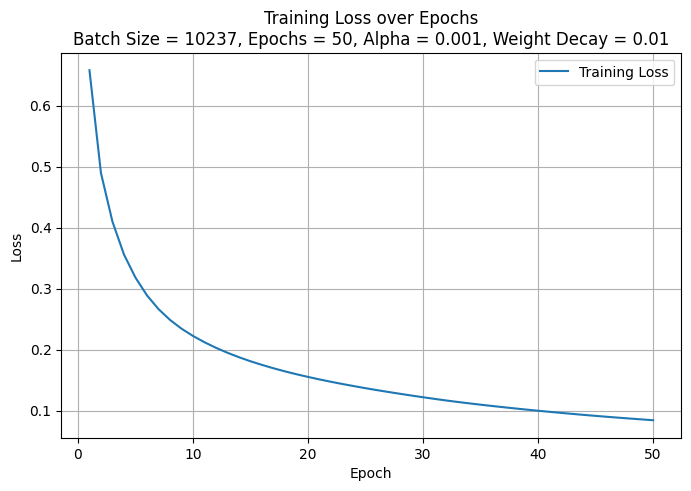

Train loss 0.0952 | Valid loss 0.3418
Valid ROC AUC: 0.956
              precision    recall  f1-score   support

           0      0.992     0.877     0.931     13892
           1      0.447     0.935     0.604      1475

    accuracy                          0.883     15367
   macro avg      0.719     0.906     0.768     15367
weighted avg      0.940     0.883     0.900     15367

[[12183  1709]
 [   96  1379]]


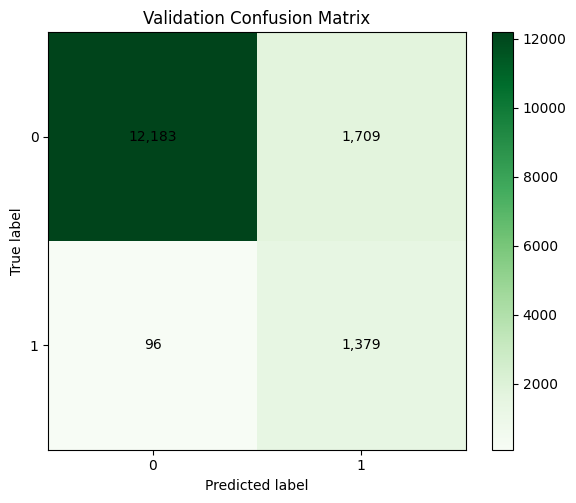

Iteration elapsed: 18.31s
 ==========     ==========     ==========     ==========
ITERATION [67/96]: 11:07:45 PM
    Batch Size:   10237
    Epochs:       50
    α:            0.001
    Weight Decay: 0.001
    
Epoch 1/50, Loss: 0.6581 | 0.007s
Epoch 2/50, Loss: 0.4888 | 0.006s
Epoch 3/50, Loss: 0.4088 | 0.010s
Epoch 4/50, Loss: 0.3546 | 0.006s
Epoch 5/50, Loss: 0.3165 | 0.007s
Epoch 6/50, Loss: 0.2872 | 0.014s
Epoch 7/50, Loss: 0.2646 | 0.007s
Epoch 8/50, Loss: 0.2467 | 0.007s
Epoch 9/50, Loss: 0.2323 | 0.007s
Epoch 10/50, Loss: 0.2202 | 0.011s
Epoch 11/50, Loss: 0.2098 | 0.007s
Epoch 12/50, Loss: 0.2006 | 0.016s
Epoch 13/50, Loss: 0.1923 | 0.012s
Epoch 14/50, Loss: 0.1849 | 0.006s
Epoch 15/50, Loss: 0.1781 | 0.012s
Epoch 16/50, Loss: 0.1719 | 0.006s
Epoch 17/50, Loss: 0.1662 | 0.004s
Epoch 18/50, Loss: 0.1609 | 0.007s
Epoch 19/50, Loss: 0.1560 | 0.004s
Epoch 20/50, Loss: 0.1514 | 0.007s
Epoch 21/50, Loss: 0.1471 | 0.004s
Epoch 22/50, Loss: 0.1430 | 0.007s
Epoch 23/50, Loss: 0.1392 |

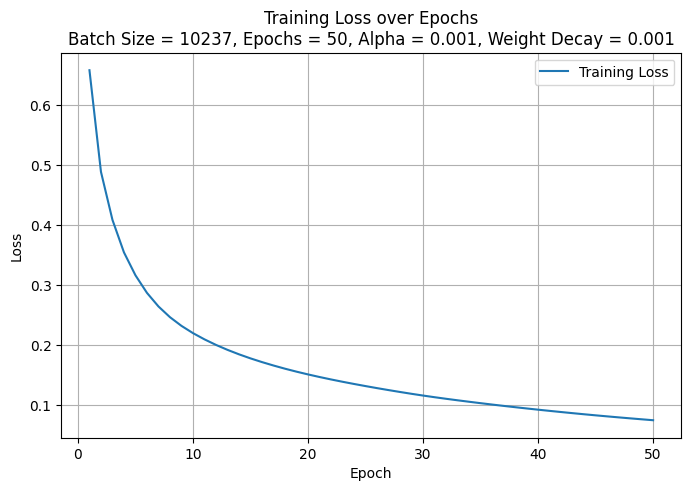

Train loss 0.0841 | Valid loss 0.3847
Valid ROC AUC: 0.956
              precision    recall  f1-score   support

           0      0.992     0.865     0.924     13892
           1      0.423     0.936     0.583      1475

    accuracy                          0.871     15367
   macro avg      0.708     0.900     0.753     15367
weighted avg      0.938     0.871     0.891     15367

[[12011  1881]
 [   95  1380]]


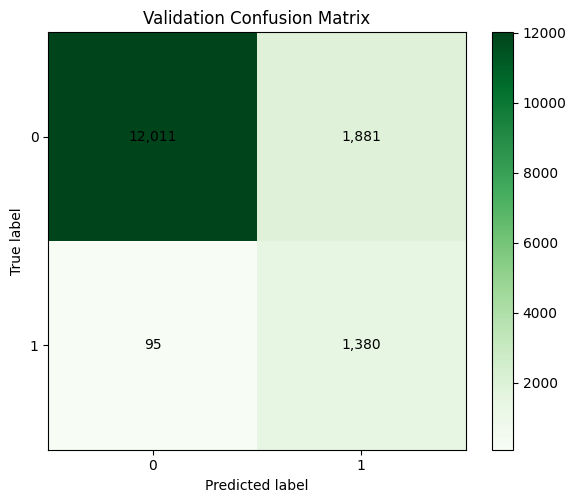

Iteration elapsed: 18.77s
 ==========     ==========     ==========     ==========
ITERATION [68/96]: 11:08:04 PM
    Batch Size:   10237
    Epochs:       100
    α:            0.01
    Weight Decay: 0.01
    
Epoch 1/100, Loss: 1.0413 | 0.007s
Epoch 2/100, Loss: 0.6361 | 0.006s
Epoch 3/100, Loss: 0.4146 | 0.012s
Epoch 4/100, Loss: 0.2393 | 0.006s
Epoch 5/100, Loss: 0.1810 | 0.014s
Epoch 6/100, Loss: 0.1754 | 0.009s
Epoch 7/100, Loss: 0.1526 | 0.006s
Epoch 8/100, Loss: 0.1451 | 0.006s
Epoch 9/100, Loss: 0.1342 | 0.008s
Epoch 10/100, Loss: 0.1247 | 0.006s
Epoch 11/100, Loss: 0.1170 | 0.013s
Epoch 12/100, Loss: 0.1124 | 0.013s
Epoch 13/100, Loss: 0.1083 | 0.011s
Epoch 14/100, Loss: 0.1041 | 0.006s
Epoch 15/100, Loss: 0.1006 | 0.016s
Epoch 16/100, Loss: 0.0966 | 0.008s
Epoch 17/100, Loss: 0.0935 | 0.010s
Epoch 18/100, Loss: 0.0901 | 0.007s
Epoch 19/100, Loss: 0.0872 | 0.017s
Epoch 20/100, Loss: 0.0842 | 0.006s
Epoch 21/100, Loss: 0.0817 | 0.006s
Epoch 22/100, Loss: 0.0791 | 0.011s
Epoch 

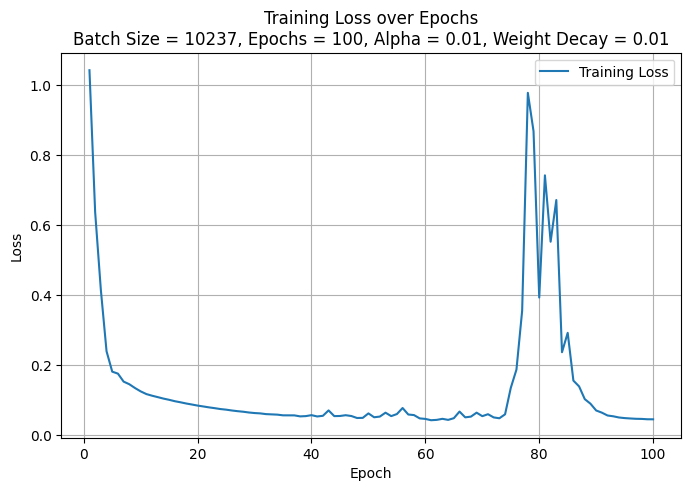

Train loss 0.0477 | Valid loss 0.3908
Valid ROC AUC: 0.967
              precision    recall  f1-score   support

           0      0.996     0.875     0.932     13892
           1      0.451     0.963     0.614      1475

    accuracy                          0.884     15367
   macro avg      0.723     0.919     0.773     15367
weighted avg      0.943     0.884     0.901     15367

[[12159  1733]
 [   54  1421]]


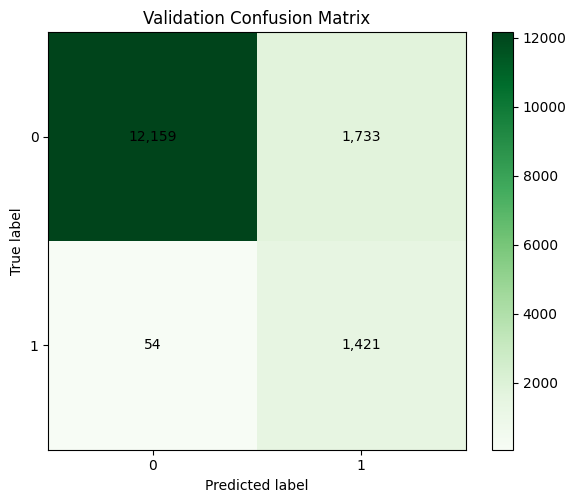

Iteration elapsed: 36.39s
 ==========     ==========     ==========     ==========
ITERATION [69/96]: 11:08:41 PM
    Batch Size:   10237
    Epochs:       100
    α:            0.01
    Weight Decay: 0.001
    
Epoch 1/100, Loss: 1.0403 | 0.015s
Epoch 2/100, Loss: 0.6353 | 0.007s
Epoch 3/100, Loss: 0.4079 | 0.006s
Epoch 4/100, Loss: 0.2460 | 0.006s
Epoch 5/100, Loss: 0.1785 | 0.007s
Epoch 6/100, Loss: 0.1793 | 0.019s
Epoch 7/100, Loss: 0.1525 | 0.006s
Epoch 8/100, Loss: 0.1443 | 0.006s
Epoch 9/100, Loss: 0.1325 | 0.006s
Epoch 10/100, Loss: 0.1240 | 0.007s
Epoch 11/100, Loss: 0.1146 | 0.007s
Epoch 12/100, Loss: 0.1090 | 0.006s
Epoch 13/100, Loss: 0.1040 | 0.006s
Epoch 14/100, Loss: 0.0985 | 0.011s
Epoch 15/100, Loss: 0.0942 | 0.007s
Epoch 16/100, Loss: 0.0896 | 0.007s
Epoch 17/100, Loss: 0.0849 | 0.017s
Epoch 18/100, Loss: 0.0812 | 0.006s
Epoch 19/100, Loss: 0.0777 | 0.007s
Epoch 20/100, Loss: 0.0744 | 0.006s
Epoch 21/100, Loss: 0.0714 | 0.009s
Epoch 22/100, Loss: 0.0684 | 0.008s
Epoch

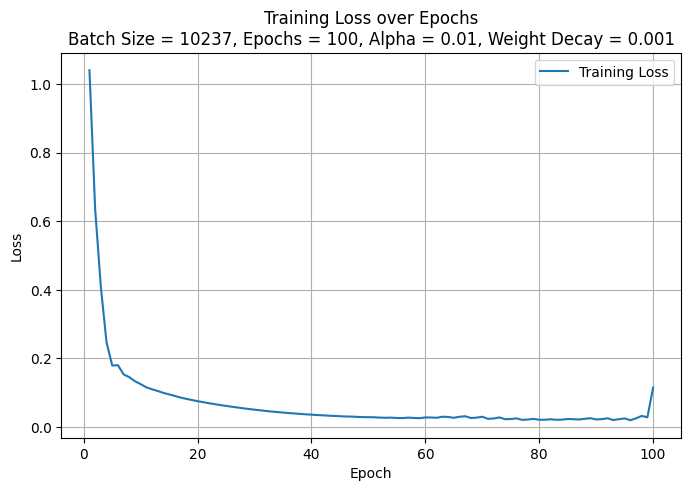

Train loss 0.0437 | Valid loss 0.4180
Valid ROC AUC: 0.904
              precision    recall  f1-score   support

           0      0.955     0.926     0.940     13892
           1      0.457     0.586     0.514      1475

    accuracy                          0.893     15367
   macro avg      0.706     0.756     0.727     15367
weighted avg      0.907     0.893     0.899     15367

[[12863  1029]
 [  610   865]]


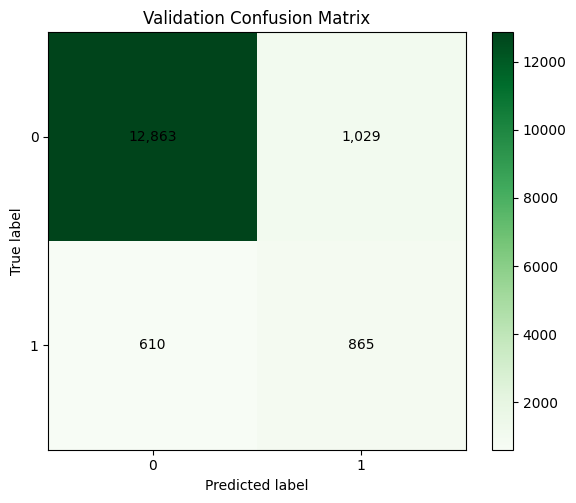

Iteration elapsed: 37.11s
 ==========     ==========     ==========     ==========
ITERATION [70/96]: 11:09:18 PM
    Batch Size:   10237
    Epochs:       100
    α:            0.001
    Weight Decay: 0.01
    
Epoch 1/100, Loss: 0.6580 | 0.004s
Epoch 2/100, Loss: 0.4894 | 0.004s
Epoch 3/100, Loss: 0.4097 | 0.007s
Epoch 4/100, Loss: 0.3559 | 0.007s
Epoch 5/100, Loss: 0.3180 | 0.008s
Epoch 6/100, Loss: 0.2889 | 0.013s
Epoch 7/100, Loss: 0.2664 | 0.017s
Epoch 8/100, Loss: 0.2487 | 0.006s
Epoch 9/100, Loss: 0.2343 | 0.007s
Epoch 10/100, Loss: 0.2223 | 0.013s
Epoch 11/100, Loss: 0.2120 | 0.014s
Epoch 12/100, Loss: 0.2029 | 0.008s
Epoch 13/100, Loss: 0.1947 | 0.016s
Epoch 14/100, Loss: 0.1874 | 0.009s
Epoch 15/100, Loss: 0.1808 | 0.009s
Epoch 16/100, Loss: 0.1748 | 0.009s
Epoch 17/100, Loss: 0.1693 | 0.007s
Epoch 18/100, Loss: 0.1642 | 0.007s
Epoch 19/100, Loss: 0.1595 | 0.007s
Epoch 20/100, Loss: 0.1552 | 0.011s
Epoch 21/100, Loss: 0.1510 | 0.005s
Epoch 22/100, Loss: 0.1472 | 0.004s
Epoch

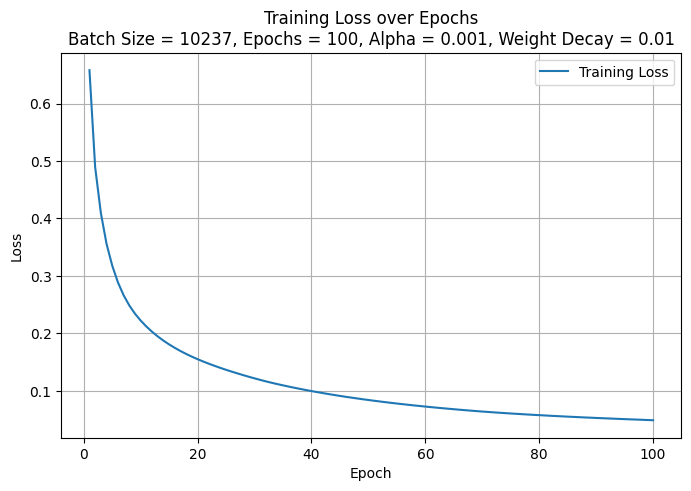

Train loss 0.0553 | Valid loss 0.3246
Valid ROC AUC: 0.964
              precision    recall  f1-score   support

           0      0.994     0.878     0.933     13892
           1      0.454     0.951     0.614      1475

    accuracy                          0.885     15367
   macro avg      0.724     0.915     0.773     15367
weighted avg      0.942     0.885     0.902     15367

[[12202  1690]
 [   72  1403]]


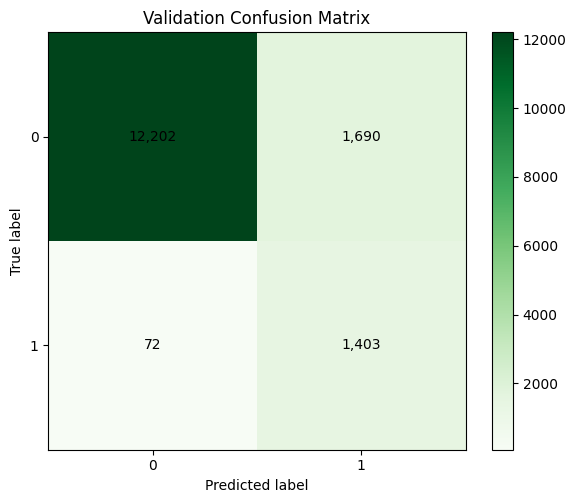

Iteration elapsed: 35.73s
 ==========     ==========     ==========     ==========
ITERATION [71/96]: 11:09:54 PM
    Batch Size:   10237
    Epochs:       100
    α:            0.001
    Weight Decay: 0.001
    
Epoch 1/100, Loss: 0.6581 | 0.010s
Epoch 2/100, Loss: 0.4888 | 0.017s
Epoch 3/100, Loss: 0.4088 | 0.006s
Epoch 4/100, Loss: 0.3546 | 0.006s
Epoch 5/100, Loss: 0.3165 | 0.011s
Epoch 6/100, Loss: 0.2872 | 0.006s
Epoch 7/100, Loss: 0.2646 | 0.011s
Epoch 8/100, Loss: 0.2467 | 0.004s
Epoch 9/100, Loss: 0.2323 | 0.005s
Epoch 10/100, Loss: 0.2202 | 0.005s
Epoch 11/100, Loss: 0.2098 | 0.004s
Epoch 12/100, Loss: 0.2006 | 0.008s
Epoch 13/100, Loss: 0.1923 | 0.005s
Epoch 14/100, Loss: 0.1849 | 0.004s
Epoch 15/100, Loss: 0.1781 | 0.014s
Epoch 16/100, Loss: 0.1719 | 0.008s
Epoch 17/100, Loss: 0.1662 | 0.013s
Epoch 18/100, Loss: 0.1609 | 0.008s
Epoch 19/100, Loss: 0.1560 | 0.006s
Epoch 20/100, Loss: 0.1514 | 0.007s
Epoch 21/100, Loss: 0.1471 | 0.007s
Epoch 22/100, Loss: 0.1430 | 0.009s
Epoc

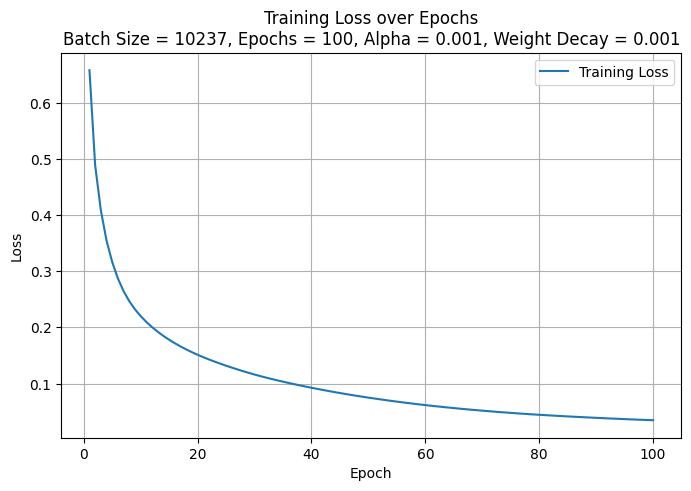

Train loss 0.0390 | Valid loss 0.4102
Valid ROC AUC: 0.963
              precision    recall  f1-score   support

           0      0.994     0.872     0.929     13892
           1      0.441     0.951     0.602      1475

    accuracy                          0.879     15367
   macro avg      0.717     0.911     0.766     15367
weighted avg      0.941     0.879     0.898     15367

[[12113  1779]
 [   73  1402]]


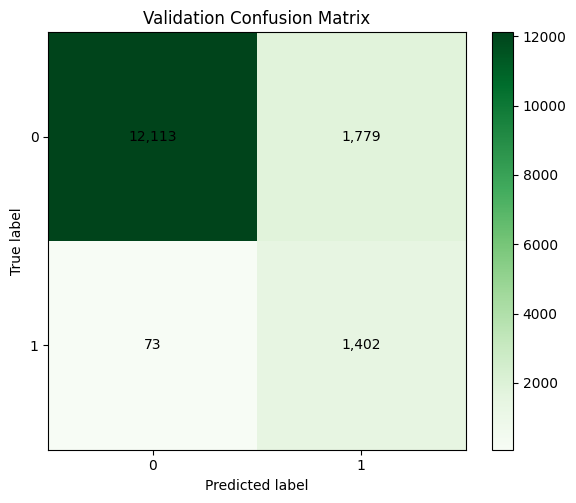

Iteration elapsed: 35.87s
 ==========     ==========     ==========     ==========
ITERATION [72/96]: 11:10:31 PM
    Batch Size:   10237
    Epochs:       150
    α:            0.01
    Weight Decay: 0.01
    
Epoch 1/150, Loss: 1.0413 | 0.004s
Epoch 2/150, Loss: 0.6361 | 0.005s
Epoch 3/150, Loss: 0.4146 | 0.004s
Epoch 4/150, Loss: 0.2393 | 0.006s
Epoch 5/150, Loss: 0.1810 | 0.006s
Epoch 6/150, Loss: 0.1754 | 0.006s
Epoch 7/150, Loss: 0.1526 | 0.008s
Epoch 8/150, Loss: 0.1451 | 0.009s
Epoch 9/150, Loss: 0.1342 | 0.007s
Epoch 10/150, Loss: 0.1247 | 0.008s
Epoch 11/150, Loss: 0.1170 | 0.006s
Epoch 12/150, Loss: 0.1124 | 0.013s
Epoch 13/150, Loss: 0.1083 | 0.006s
Epoch 14/150, Loss: 0.1041 | 0.006s
Epoch 15/150, Loss: 0.1006 | 0.007s
Epoch 16/150, Loss: 0.0966 | 0.008s
Epoch 17/150, Loss: 0.0935 | 0.013s
Epoch 18/150, Loss: 0.0901 | 0.012s
Epoch 19/150, Loss: 0.0872 | 0.006s
Epoch 20/150, Loss: 0.0842 | 0.014s
Epoch 21/150, Loss: 0.0817 | 0.007s
Epoch 22/150, Loss: 0.0791 | 0.006s
Epoch 

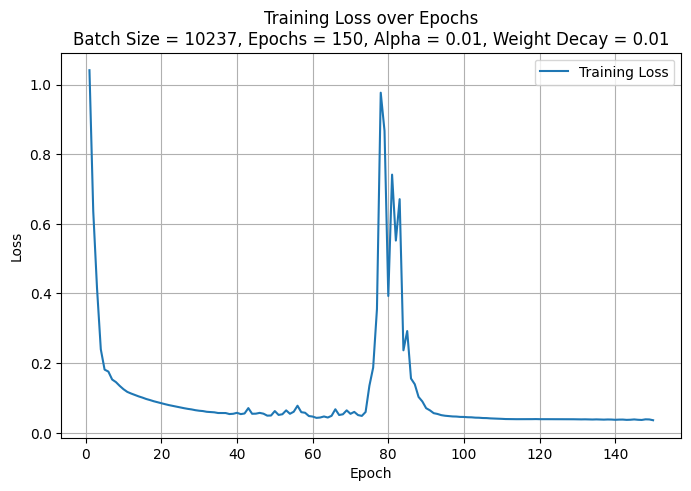

Train loss 0.0358 | Valid loss 0.2900
Valid ROC AUC: 0.963
              precision    recall  f1-score   support

           0      0.995     0.878     0.933     13892
           1      0.455     0.957     0.617      1475

    accuracy                          0.886     15367
   macro avg      0.725     0.918     0.775     15367
weighted avg      0.943     0.886     0.903     15367

[[12204  1688]
 [   64  1411]]


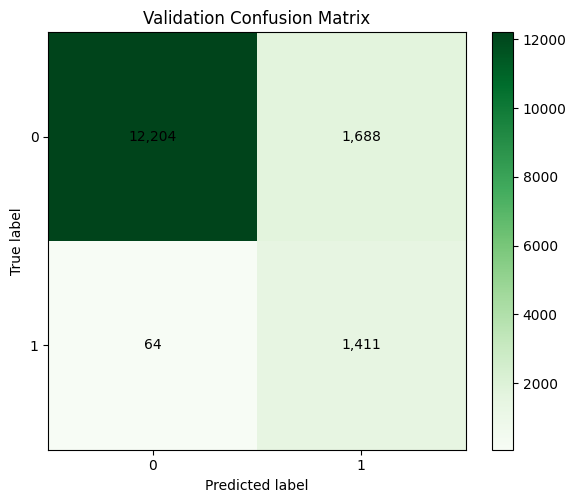

Iteration elapsed: 54.20s
 ==========     ==========     ==========     ==========
ITERATION [73/96]: 11:11:25 PM
    Batch Size:   10237
    Epochs:       150
    α:            0.01
    Weight Decay: 0.001
    
Epoch 1/150, Loss: 1.0403 | 0.006s
Epoch 2/150, Loss: 0.6353 | 0.005s
Epoch 3/150, Loss: 0.4079 | 0.006s
Epoch 4/150, Loss: 0.2460 | 0.007s
Epoch 5/150, Loss: 0.1785 | 0.014s
Epoch 6/150, Loss: 0.1793 | 0.016s
Epoch 7/150, Loss: 0.1525 | 0.007s
Epoch 8/150, Loss: 0.1443 | 0.007s
Epoch 9/150, Loss: 0.1325 | 0.011s
Epoch 10/150, Loss: 0.1240 | 0.007s
Epoch 11/150, Loss: 0.1146 | 0.010s
Epoch 12/150, Loss: 0.1090 | 0.004s
Epoch 13/150, Loss: 0.1040 | 0.005s
Epoch 14/150, Loss: 0.0985 | 0.005s
Epoch 15/150, Loss: 0.0942 | 0.003s
Epoch 16/150, Loss: 0.0896 | 0.005s
Epoch 17/150, Loss: 0.0849 | 0.004s
Epoch 18/150, Loss: 0.0812 | 0.013s
Epoch 19/150, Loss: 0.0777 | 0.014s
Epoch 20/150, Loss: 0.0744 | 0.006s
Epoch 21/150, Loss: 0.0714 | 0.009s
Epoch 22/150, Loss: 0.0684 | 0.014s
Epoch

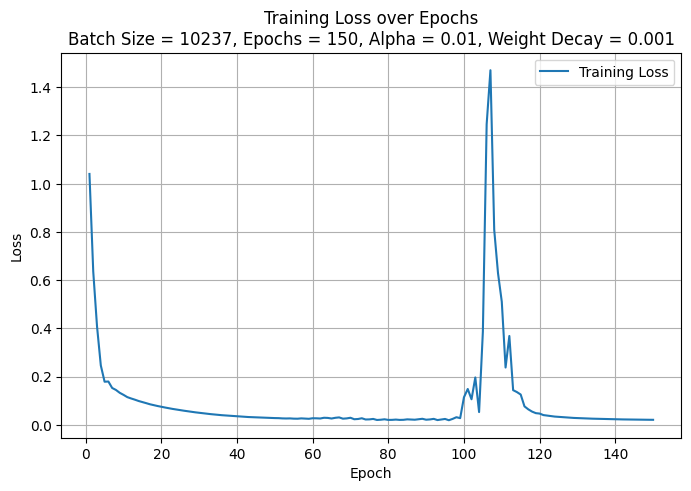

Train loss 0.0197 | Valid loss 0.6176
Valid ROC AUC: 0.952
              precision    recall  f1-score   support

           0      0.994     0.873     0.930     13892
           1      0.443     0.952     0.605      1475

    accuracy                          0.881     15367
   macro avg      0.719     0.912     0.767     15367
weighted avg      0.941     0.881     0.898     15367

[[12127  1765]
 [   71  1404]]


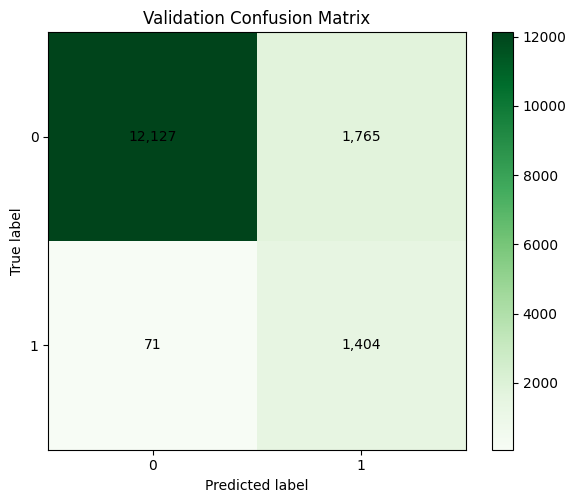

Iteration elapsed: 53.89s
 ==========     ==========     ==========     ==========
ITERATION [74/96]: 11:12:19 PM
    Batch Size:   10237
    Epochs:       150
    α:            0.001
    Weight Decay: 0.01
    
Epoch 1/150, Loss: 0.6580 | 0.006s
Epoch 2/150, Loss: 0.4894 | 0.005s
Epoch 3/150, Loss: 0.4097 | 0.004s
Epoch 4/150, Loss: 0.3559 | 0.006s
Epoch 5/150, Loss: 0.3180 | 0.015s
Epoch 6/150, Loss: 0.2889 | 0.014s
Epoch 7/150, Loss: 0.2664 | 0.006s
Epoch 8/150, Loss: 0.2487 | 0.006s
Epoch 9/150, Loss: 0.2343 | 0.007s
Epoch 10/150, Loss: 0.2223 | 0.006s
Epoch 11/150, Loss: 0.2120 | 0.005s
Epoch 12/150, Loss: 0.2029 | 0.005s
Epoch 13/150, Loss: 0.1947 | 0.004s
Epoch 14/150, Loss: 0.1874 | 0.008s
Epoch 15/150, Loss: 0.1808 | 0.006s
Epoch 16/150, Loss: 0.1748 | 0.006s
Epoch 17/150, Loss: 0.1693 | 0.006s
Epoch 18/150, Loss: 0.1642 | 0.007s
Epoch 19/150, Loss: 0.1595 | 0.018s
Epoch 20/150, Loss: 0.1552 | 0.006s
Epoch 21/150, Loss: 0.1510 | 0.014s
Epoch 22/150, Loss: 0.1472 | 0.013s
Epoch

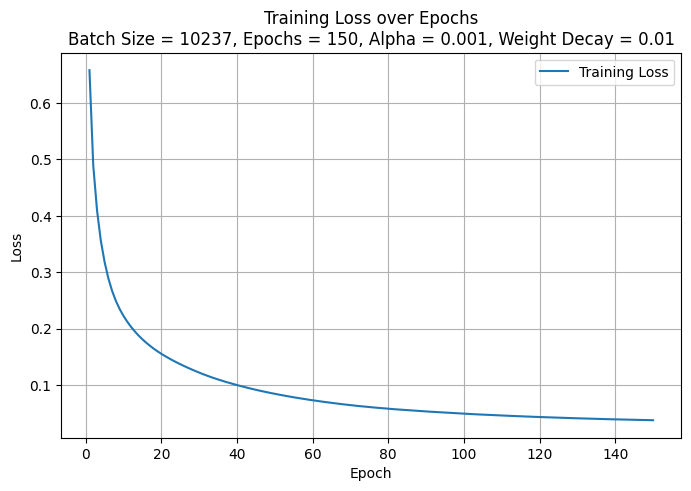

Train loss 0.0417 | Valid loss 0.3282
Valid ROC AUC: 0.964
              precision    recall  f1-score   support

           0      0.995     0.876     0.932     13892
           1      0.451     0.956     0.613      1475

    accuracy                          0.884     15367
   macro avg      0.723     0.916     0.772     15367
weighted avg      0.942     0.884     0.901     15367

[[12175  1717]
 [   65  1410]]


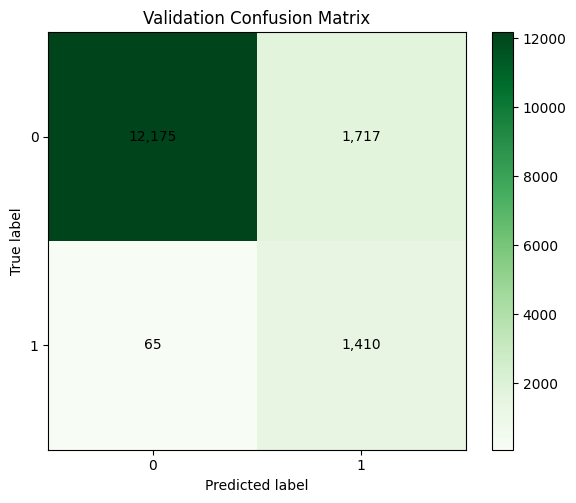

Iteration elapsed: 53.68s
 ==========     ==========     ==========     ==========
ITERATION [75/96]: 11:13:13 PM
    Batch Size:   10237
    Epochs:       150
    α:            0.001
    Weight Decay: 0.001
    
Epoch 1/150, Loss: 0.6581 | 0.006s
Epoch 2/150, Loss: 0.4888 | 0.007s
Epoch 3/150, Loss: 0.4088 | 0.010s
Epoch 4/150, Loss: 0.3546 | 0.006s
Epoch 5/150, Loss: 0.3165 | 0.012s
Epoch 6/150, Loss: 0.2872 | 0.006s
Epoch 7/150, Loss: 0.2646 | 0.008s
Epoch 8/150, Loss: 0.2467 | 0.006s
Epoch 9/150, Loss: 0.2323 | 0.018s
Epoch 10/150, Loss: 0.2202 | 0.006s
Epoch 11/150, Loss: 0.2098 | 0.006s
Epoch 12/150, Loss: 0.2006 | 0.004s
Epoch 13/150, Loss: 0.1923 | 0.004s
Epoch 14/150, Loss: 0.1849 | 0.005s
Epoch 15/150, Loss: 0.1781 | 0.004s
Epoch 16/150, Loss: 0.1719 | 0.008s
Epoch 17/150, Loss: 0.1662 | 0.006s
Epoch 18/150, Loss: 0.1609 | 0.006s
Epoch 19/150, Loss: 0.1560 | 0.005s
Epoch 20/150, Loss: 0.1514 | 0.004s
Epoch 21/150, Loss: 0.1471 | 0.004s
Epoch 22/150, Loss: 0.1430 | 0.007s
Epoc

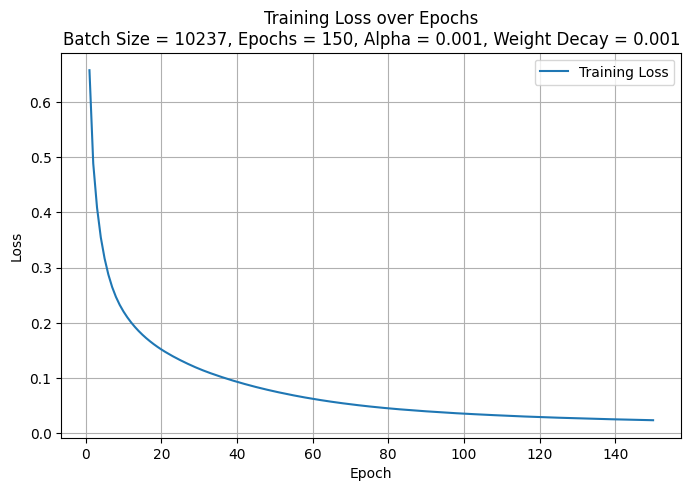

Train loss 0.0247 | Valid loss 0.4339
Valid ROC AUC: 0.960
              precision    recall  f1-score   support

           0      0.995     0.874     0.930     13892
           1      0.446     0.957     0.609      1475

    accuracy                          0.882     15367
   macro avg      0.721     0.916     0.770     15367
weighted avg      0.942     0.882     0.900     15367

[[12140  1752]
 [   63  1412]]


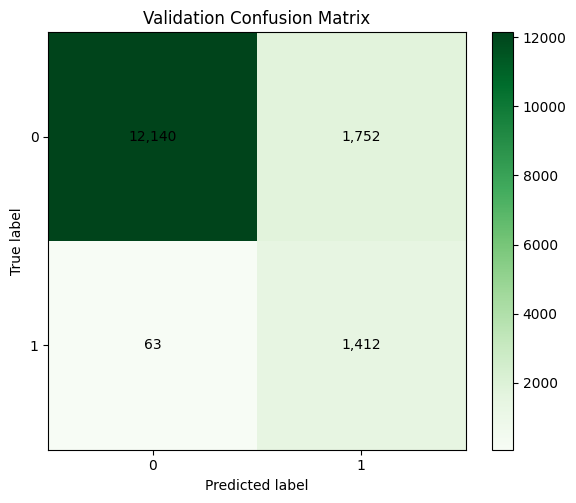

Iteration elapsed: 52.25s
 ==========     ==========     ==========     ==========
ITERATION [76/96]: 11:14:06 PM
    Batch Size:   10237
    Epochs:       200
    α:            0.01
    Weight Decay: 0.01
    
Epoch 1/200, Loss: 1.0413 | 0.019s
Epoch 2/200, Loss: 0.6361 | 0.006s
Epoch 3/200, Loss: 0.4146 | 0.015s
Epoch 4/200, Loss: 0.2393 | 0.013s
Epoch 5/200, Loss: 0.1810 | 0.010s
Epoch 6/200, Loss: 0.1754 | 0.012s
Epoch 7/200, Loss: 0.1526 | 0.008s
Epoch 8/200, Loss: 0.1451 | 0.005s
Epoch 9/200, Loss: 0.1342 | 0.004s
Epoch 10/200, Loss: 0.1247 | 0.006s
Epoch 11/200, Loss: 0.1170 | 0.007s
Epoch 12/200, Loss: 0.1124 | 0.006s
Epoch 13/200, Loss: 0.1083 | 0.006s
Epoch 14/200, Loss: 0.1041 | 0.006s
Epoch 15/200, Loss: 0.1006 | 0.016s
Epoch 16/200, Loss: 0.0966 | 0.007s
Epoch 17/200, Loss: 0.0935 | 0.007s
Epoch 18/200, Loss: 0.0901 | 0.006s
Epoch 19/200, Loss: 0.0872 | 0.014s
Epoch 20/200, Loss: 0.0842 | 0.016s
Epoch 21/200, Loss: 0.0817 | 0.016s
Epoch 22/200, Loss: 0.0791 | 0.014s
Epoch 

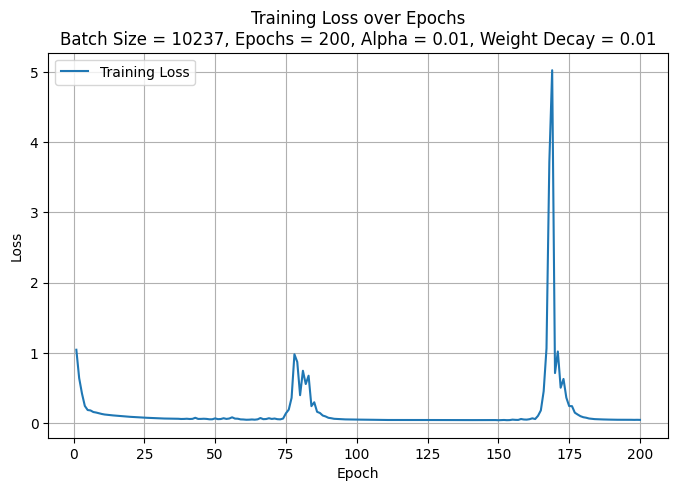

Train loss 0.0407 | Valid loss 0.4044
Valid ROC AUC: 0.963
              precision    recall  f1-score   support

           0      0.996     0.871     0.929     13892
           1      0.442     0.964     0.606      1475

    accuracy                          0.880     15367
   macro avg      0.719     0.917     0.767     15367
weighted avg      0.942     0.880     0.898     15367

[[12094  1798]
 [   53  1422]]


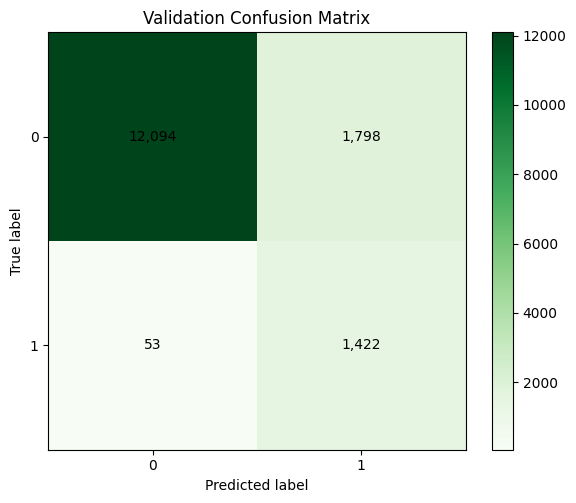

Iteration elapsed: 70.87s
 ==========     ==========     ==========     ==========
ITERATION [77/96]: 11:15:17 PM
    Batch Size:   10237
    Epochs:       200
    α:            0.01
    Weight Decay: 0.001
    
Epoch 1/200, Loss: 1.0403 | 0.004s
Epoch 2/200, Loss: 0.6353 | 0.004s
Epoch 3/200, Loss: 0.4079 | 0.009s
Epoch 4/200, Loss: 0.2460 | 0.006s
Epoch 5/200, Loss: 0.1785 | 0.004s
Epoch 6/200, Loss: 0.1793 | 0.007s
Epoch 7/200, Loss: 0.1525 | 0.011s
Epoch 8/200, Loss: 0.1443 | 0.006s
Epoch 9/200, Loss: 0.1325 | 0.007s
Epoch 10/200, Loss: 0.1240 | 0.008s
Epoch 11/200, Loss: 0.1146 | 0.007s
Epoch 12/200, Loss: 0.1090 | 0.006s
Epoch 13/200, Loss: 0.1040 | 0.013s
Epoch 14/200, Loss: 0.0985 | 0.011s
Epoch 15/200, Loss: 0.0942 | 0.005s
Epoch 16/200, Loss: 0.0896 | 0.005s
Epoch 17/200, Loss: 0.0849 | 0.005s
Epoch 18/200, Loss: 0.0812 | 0.004s
Epoch 19/200, Loss: 0.0777 | 0.003s
Epoch 20/200, Loss: 0.0744 | 0.006s
Epoch 21/200, Loss: 0.0714 | 0.005s
Epoch 22/200, Loss: 0.0684 | 0.016s
Epoch

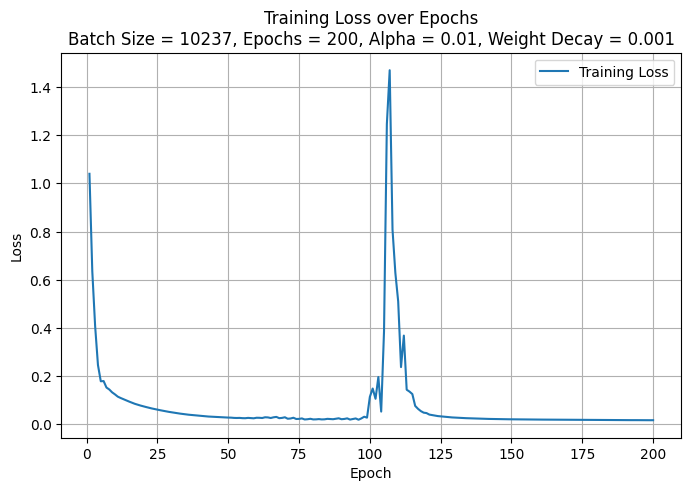

Train loss 0.0172 | Valid loss 0.5737
Valid ROC AUC: 0.949
              precision    recall  f1-score   support

           0      0.994     0.872     0.929     13892
           1      0.441     0.954     0.603      1475

    accuracy                          0.879     15367
   macro avg      0.718     0.913     0.766     15367
weighted avg      0.941     0.879     0.898     15367

[[12108  1784]
 [   68  1407]]


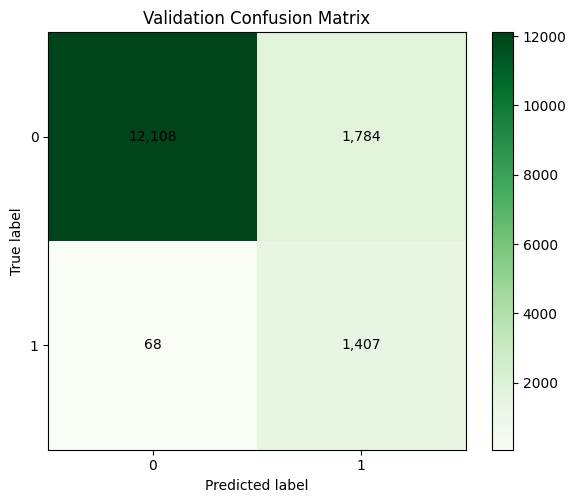

Iteration elapsed: 70.87s
 ==========     ==========     ==========     ==========
ITERATION [78/96]: 11:16:28 PM
    Batch Size:   10237
    Epochs:       200
    α:            0.001
    Weight Decay: 0.01
    
Epoch 1/200, Loss: 0.6580 | 0.004s
Epoch 2/200, Loss: 0.4894 | 0.004s
Epoch 3/200, Loss: 0.4097 | 0.006s
Epoch 4/200, Loss: 0.3559 | 0.013s
Epoch 5/200, Loss: 0.3180 | 0.006s
Epoch 6/200, Loss: 0.2889 | 0.011s
Epoch 7/200, Loss: 0.2664 | 0.008s
Epoch 8/200, Loss: 0.2487 | 0.017s
Epoch 9/200, Loss: 0.2343 | 0.007s
Epoch 10/200, Loss: 0.2223 | 0.014s
Epoch 11/200, Loss: 0.2120 | 0.006s
Epoch 12/200, Loss: 0.2029 | 0.006s
Epoch 13/200, Loss: 0.1947 | 0.004s
Epoch 14/200, Loss: 0.1874 | 0.008s
Epoch 15/200, Loss: 0.1808 | 0.004s
Epoch 16/200, Loss: 0.1748 | 0.006s
Epoch 17/200, Loss: 0.1693 | 0.012s
Epoch 18/200, Loss: 0.1642 | 0.013s
Epoch 19/200, Loss: 0.1595 | 0.013s
Epoch 20/200, Loss: 0.1552 | 0.010s
Epoch 21/200, Loss: 0.1510 | 0.006s
Epoch 22/200, Loss: 0.1472 | 0.011s
Epoch

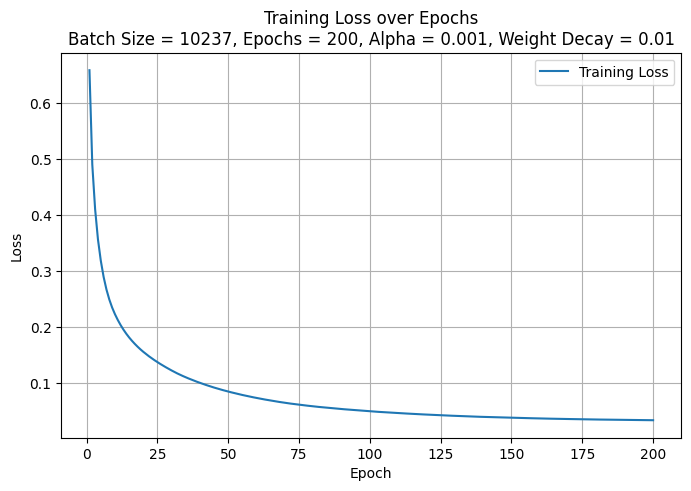

Train loss 0.0370 | Valid loss 0.3358
Valid ROC AUC: 0.963
              precision    recall  f1-score   support

           0      0.995     0.874     0.931     13892
           1      0.448     0.959     0.610      1475

    accuracy                          0.882     15367
   macro avg      0.721     0.917     0.771     15367
weighted avg      0.943     0.882     0.900     15367

[[12146  1746]
 [   60  1415]]


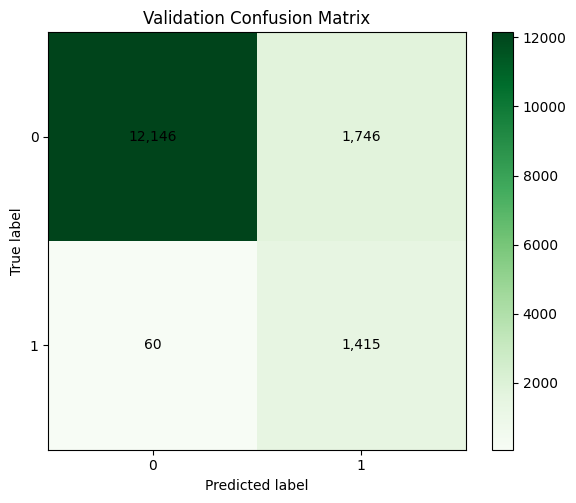

Iteration elapsed: 70.92s
 ==========     ==========     ==========     ==========
ITERATION [79/96]: 11:17:39 PM
    Batch Size:   10237
    Epochs:       200
    α:            0.001
    Weight Decay: 0.001
    
Epoch 1/200, Loss: 0.6581 | 0.006s
Epoch 2/200, Loss: 0.4888 | 0.006s
Epoch 3/200, Loss: 0.4088 | 0.007s
Epoch 4/200, Loss: 0.3546 | 0.009s
Epoch 5/200, Loss: 0.3165 | 0.010s
Epoch 6/200, Loss: 0.2872 | 0.007s
Epoch 7/200, Loss: 0.2646 | 0.006s
Epoch 8/200, Loss: 0.2467 | 0.007s
Epoch 9/200, Loss: 0.2323 | 0.006s
Epoch 10/200, Loss: 0.2202 | 0.006s
Epoch 11/200, Loss: 0.2098 | 0.011s
Epoch 12/200, Loss: 0.2006 | 0.007s
Epoch 13/200, Loss: 0.1923 | 0.011s
Epoch 14/200, Loss: 0.1849 | 0.012s
Epoch 15/200, Loss: 0.1781 | 0.008s
Epoch 16/200, Loss: 0.1719 | 0.006s
Epoch 17/200, Loss: 0.1662 | 0.008s
Epoch 18/200, Loss: 0.1609 | 0.006s
Epoch 19/200, Loss: 0.1560 | 0.010s
Epoch 20/200, Loss: 0.1514 | 0.006s
Epoch 21/200, Loss: 0.1471 | 0.006s
Epoch 22/200, Loss: 0.1430 | 0.006s
Epoc

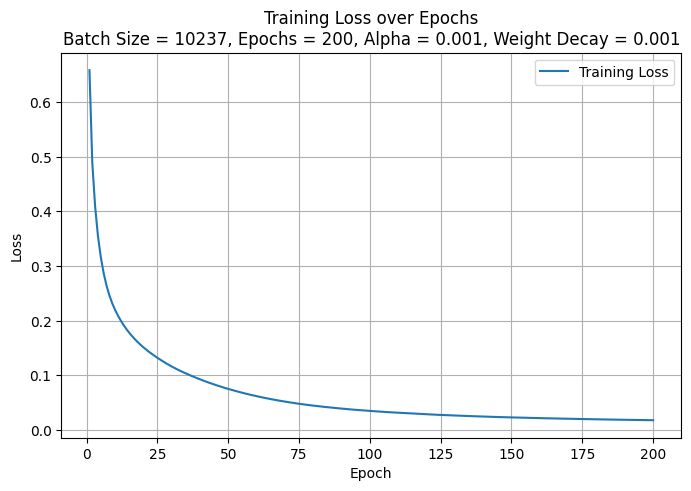

Train loss 0.0185 | Valid loss 0.4543
Valid ROC AUC: 0.957
              precision    recall  f1-score   support

           0      0.994     0.875     0.931     13892
           1      0.448     0.953     0.609      1475

    accuracy                          0.883     15367
   macro avg      0.721     0.914     0.770     15367
weighted avg      0.942     0.883     0.900     15367

[[12159  1733]
 [   69  1406]]


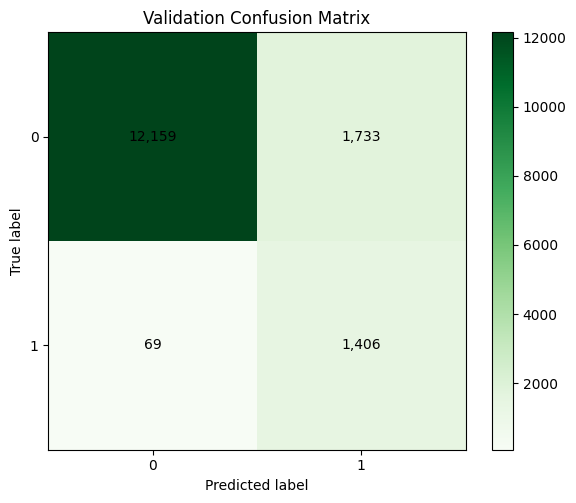

Iteration elapsed: 71.19s
 ==========     ==========     ==========     ==========
ITERATION [80/96]: 11:18:50 PM
    Batch Size:   51182
    Epochs:       50
    α:            0.01
    Weight Decay: 0.01
    
Epoch 1/50, Loss: 0.7041 | 0.049s
Epoch 2/50, Loss: 0.6073 | 0.017s
Epoch 3/50, Loss: 0.4434 | 0.016s
Epoch 4/50, Loss: 0.3614 | 0.015s
Epoch 5/50, Loss: 0.2904 | 0.015s
Epoch 6/50, Loss: 0.2589 | 0.014s
Epoch 7/50, Loss: 0.2407 | 0.013s
Epoch 8/50, Loss: 0.2304 | 0.018s
Epoch 9/50, Loss: 0.2221 | 0.013s
Epoch 10/50, Loss: 0.2186 | 0.041s
Epoch 11/50, Loss: 0.2040 | 0.042s
Epoch 12/50, Loss: 0.1866 | 0.036s
Epoch 13/50, Loss: 0.1762 | 0.038s
Epoch 14/50, Loss: 0.1695 | 0.045s
Epoch 15/50, Loss: 0.1615 | 0.049s
Epoch 16/50, Loss: 0.1522 | 0.017s
Epoch 17/50, Loss: 0.1456 | 0.011s
Epoch 18/50, Loss: 0.1429 | 0.014s
Epoch 19/50, Loss: 0.1399 | 0.013s
Epoch 20/50, Loss: 0.1334 | 0.019s
Epoch 21/50, Loss: 0.1271 | 0.060s
Epoch 22/50, Loss: 0.1229 | 0.048s
Epoch 23/50, Loss: 0.1187 | 0

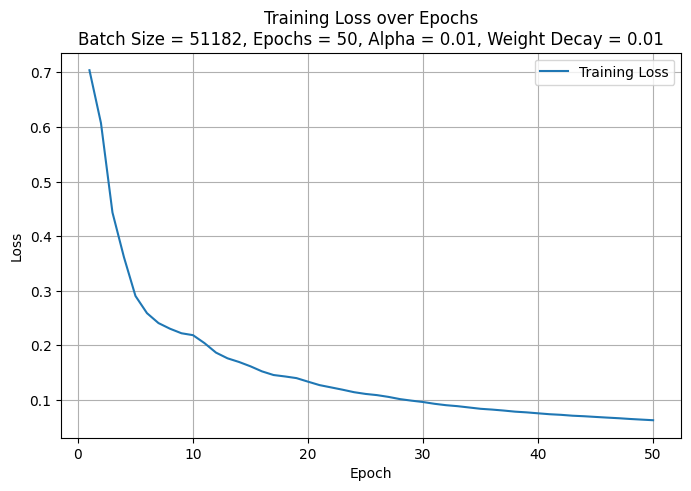

Train loss 0.0759 | Valid loss 0.3446
Valid ROC AUC: 0.962
              precision    recall  f1-score   support

           0      0.995     0.873     0.930     13892
           1      0.446     0.959     0.608      1475

    accuracy                          0.881     15367
   macro avg      0.720     0.916     0.769     15367
weighted avg      0.942     0.881     0.899     15367

[[12131  1761]
 [   60  1415]]


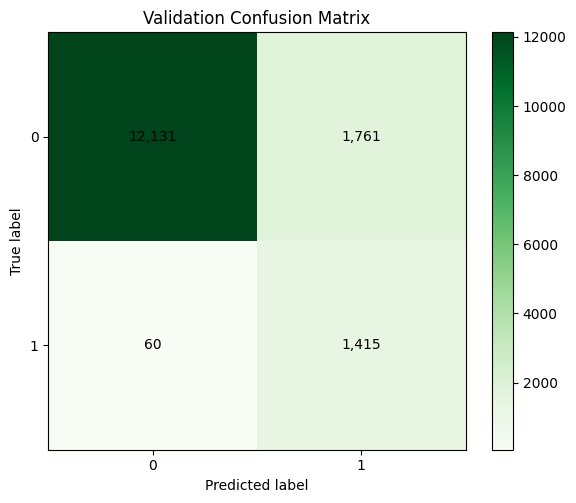

Iteration elapsed: 19.36s
 ==========     ==========     ==========     ==========
ITERATION [81/96]: 11:19:10 PM
    Batch Size:   51182
    Epochs:       50
    α:            0.01
    Weight Decay: 0.001
    
Epoch 1/50, Loss: 0.7041 | 0.024s
Epoch 2/50, Loss: 0.6096 | 0.018s
Epoch 3/50, Loss: 0.4434 | 0.048s
Epoch 4/50, Loss: 0.3619 | 0.034s
Epoch 5/50, Loss: 0.2911 | 0.046s
Epoch 6/50, Loss: 0.2594 | 0.064s
Epoch 7/50, Loss: 0.2416 | 0.014s
Epoch 8/50, Loss: 0.2316 | 0.019s
Epoch 9/50, Loss: 0.2240 | 0.011s
Epoch 10/50, Loss: 0.2226 | 0.017s
Epoch 11/50, Loss: 0.2101 | 0.010s
Epoch 12/50, Loss: 0.1939 | 0.020s
Epoch 13/50, Loss: 0.1841 | 0.017s
Epoch 14/50, Loss: 0.1776 | 0.018s
Epoch 15/50, Loss: 0.1702 | 0.037s
Epoch 16/50, Loss: 0.1611 | 0.055s
Epoch 17/50, Loss: 0.1528 | 0.036s
Epoch 18/50, Loss: 0.1477 | 0.045s
Epoch 19/50, Loss: 0.1446 | 0.048s
Epoch 20/50, Loss: 0.1393 | 0.015s
Epoch 21/50, Loss: 0.1328 | 0.010s
Epoch 22/50, Loss: 0.1280 | 0.016s
Epoch 23/50, Loss: 0.1245 | 

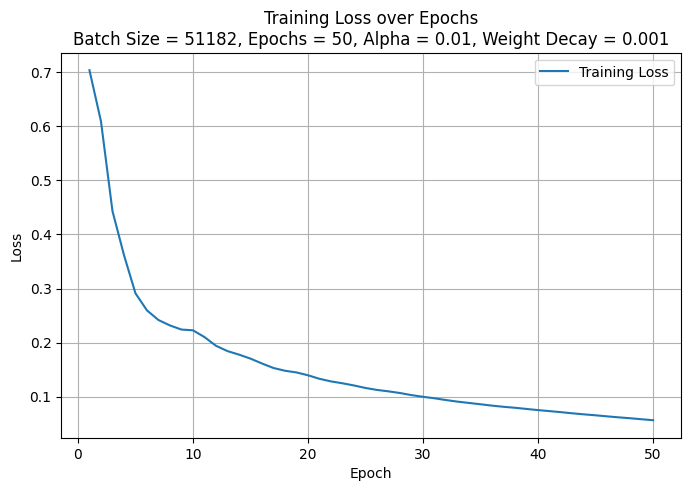

Train loss 0.0670 | Valid loss 0.4933
Valid ROC AUC: 0.963
              precision    recall  f1-score   support

           0      0.995     0.849     0.916     13892
           1      0.402     0.957     0.566      1475

    accuracy                          0.859     15367
   macro avg      0.698     0.903     0.741     15367
weighted avg      0.938     0.859     0.882     15367

[[11793  2099]
 [   63  1412]]


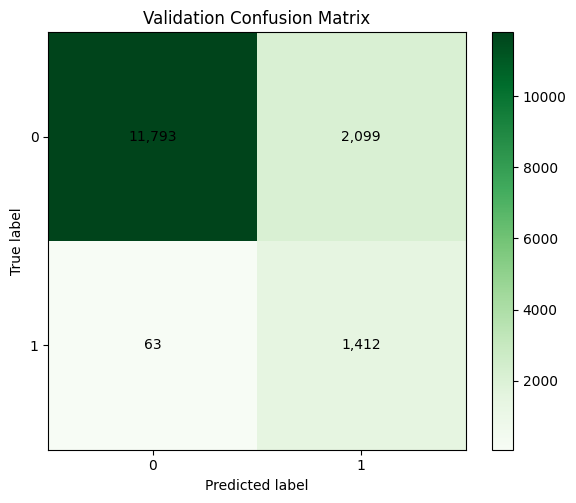

Iteration elapsed: 18.42s
 ==========     ==========     ==========     ==========
ITERATION [82/96]: 11:19:29 PM
    Batch Size:   51182
    Epochs:       50
    α:            0.001
    Weight Decay: 0.01
    
Epoch 1/50, Loss: 0.7041 | 0.083s
Epoch 2/50, Loss: 0.6193 | 0.033s
Epoch 3/50, Loss: 0.5583 | 0.029s
Epoch 4/50, Loss: 0.5166 | 0.037s
Epoch 5/50, Loss: 0.4859 | 0.029s
Epoch 6/50, Loss: 0.4604 | 0.018s
Epoch 7/50, Loss: 0.4377 | 0.011s
Epoch 8/50, Loss: 0.4169 | 0.017s
Epoch 9/50, Loss: 0.3977 | 0.011s
Epoch 10/50, Loss: 0.3802 | 0.032s
Epoch 11/50, Loss: 0.3644 | 0.046s
Epoch 12/50, Loss: 0.3505 | 0.019s
Epoch 13/50, Loss: 0.3381 | 0.013s
Epoch 14/50, Loss: 0.3269 | 0.018s
Epoch 15/50, Loss: 0.3167 | 0.018s
Epoch 16/50, Loss: 0.3073 | 0.019s
Epoch 17/50, Loss: 0.2986 | 0.038s
Epoch 18/50, Loss: 0.2905 | 0.038s
Epoch 19/50, Loss: 0.2829 | 0.066s
Epoch 20/50, Loss: 0.2758 | 0.050s
Epoch 21/50, Loss: 0.2693 | 0.052s
Epoch 22/50, Loss: 0.2632 | 0.037s
Epoch 23/50, Loss: 0.2575 | 

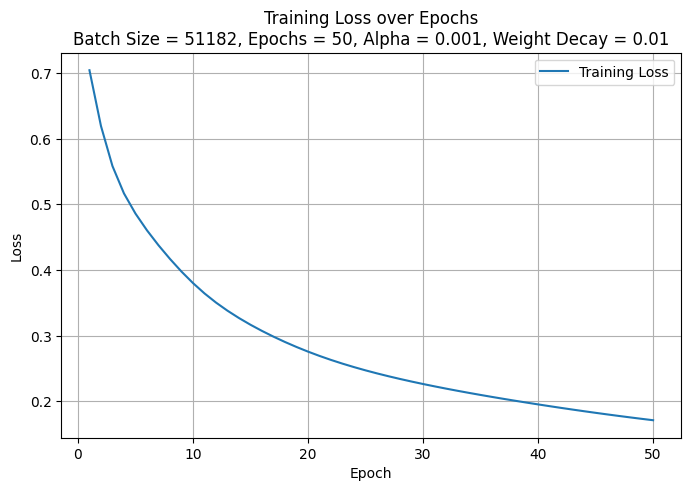

Train loss 0.2052 | Valid loss 0.4333
Valid ROC AUC: 0.899
              precision    recall  f1-score   support

           0      0.981     0.795     0.878     13892
           1      0.306     0.852     0.451      1475

    accuracy                          0.801     15367
   macro avg      0.644     0.824     0.665     15367
weighted avg      0.916     0.801     0.837     15367

[[11047  2845]
 [  218  1257]]


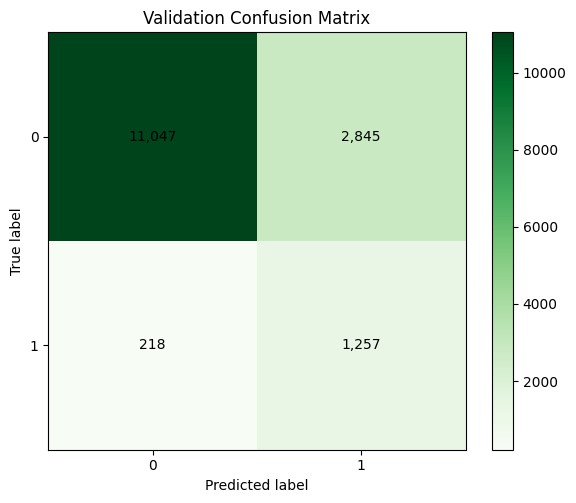

Iteration elapsed: 18.82s
 ==========     ==========     ==========     ==========
ITERATION [83/96]: 11:19:48 PM
    Batch Size:   51182
    Epochs:       50
    α:            0.001
    Weight Decay: 0.001
    
Epoch 1/50, Loss: 0.7041 | 0.055s
Epoch 2/50, Loss: 0.6192 | 0.058s
Epoch 3/50, Loss: 0.5582 | 0.070s
Epoch 4/50, Loss: 0.5166 | 0.049s
Epoch 5/50, Loss: 0.4860 | 0.017s
Epoch 6/50, Loss: 0.4604 | 0.017s
Epoch 7/50, Loss: 0.4377 | 0.015s
Epoch 8/50, Loss: 0.4168 | 0.017s
Epoch 9/50, Loss: 0.3975 | 0.010s
Epoch 10/50, Loss: 0.3799 | 0.020s
Epoch 11/50, Loss: 0.3641 | 0.048s
Epoch 12/50, Loss: 0.3501 | 0.037s
Epoch 13/50, Loss: 0.3376 | 0.037s
Epoch 14/50, Loss: 0.3264 | 0.046s
Epoch 15/50, Loss: 0.3161 | 0.011s
Epoch 16/50, Loss: 0.3066 | 0.016s
Epoch 17/50, Loss: 0.2979 | 0.016s
Epoch 18/50, Loss: 0.2897 | 0.015s
Epoch 19/50, Loss: 0.2821 | 0.011s
Epoch 20/50, Loss: 0.2750 | 0.051s
Epoch 21/50, Loss: 0.2684 | 0.012s
Epoch 22/50, Loss: 0.2623 | 0.015s
Epoch 23/50, Loss: 0.2566 |

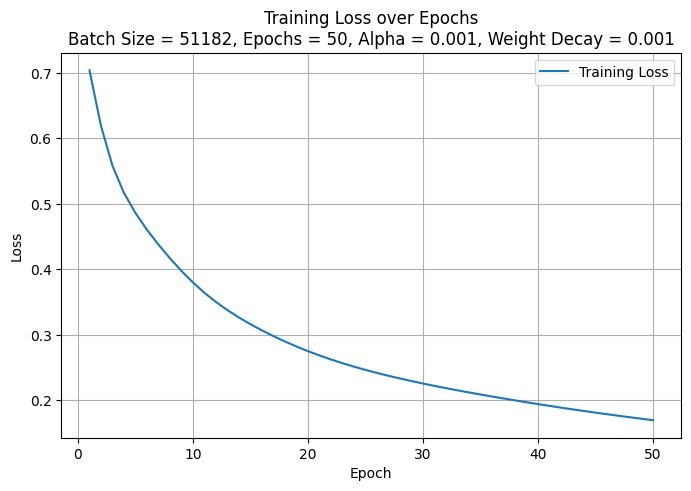

Train loss 0.1998 | Valid loss 0.4518
Valid ROC AUC: 0.893
              precision    recall  f1-score   support

           0      0.980     0.775     0.865     13892
           1      0.287     0.853     0.429      1475

    accuracy                          0.782     15367
   macro avg      0.633     0.814     0.647     15367
weighted avg      0.914     0.782     0.824     15367

[[10763  3129]
 [  217  1258]]


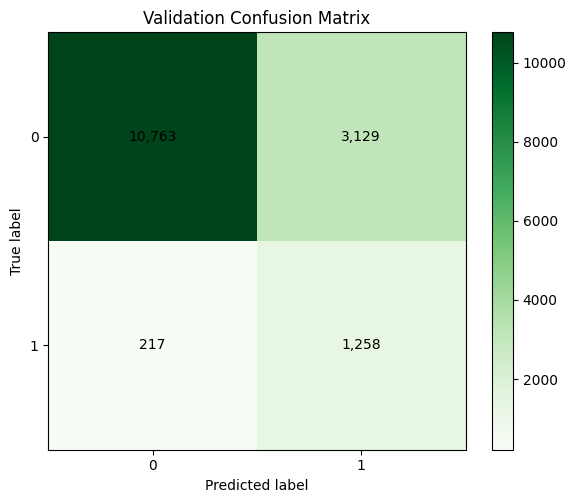

Iteration elapsed: 18.98s
 ==========     ==========     ==========     ==========
ITERATION [84/96]: 11:20:07 PM
    Batch Size:   51182
    Epochs:       100
    α:            0.01
    Weight Decay: 0.01
    
Epoch 1/100, Loss: 0.7041 | 0.027s
Epoch 2/100, Loss: 0.6073 | 0.020s
Epoch 3/100, Loss: 0.4434 | 0.019s
Epoch 4/100, Loss: 0.3614 | 0.020s
Epoch 5/100, Loss: 0.2904 | 0.039s
Epoch 6/100, Loss: 0.2589 | 0.062s
Epoch 7/100, Loss: 0.2407 | 0.042s
Epoch 8/100, Loss: 0.2304 | 0.040s
Epoch 9/100, Loss: 0.2221 | 0.048s
Epoch 10/100, Loss: 0.2186 | 0.045s
Epoch 11/100, Loss: 0.2040 | 0.010s
Epoch 12/100, Loss: 0.1866 | 0.016s
Epoch 13/100, Loss: 0.1762 | 0.016s
Epoch 14/100, Loss: 0.1695 | 0.015s
Epoch 15/100, Loss: 0.1615 | 0.012s
Epoch 16/100, Loss: 0.1522 | 0.019s
Epoch 17/100, Loss: 0.1456 | 0.012s
Epoch 18/100, Loss: 0.1429 | 0.042s
Epoch 19/100, Loss: 0.1399 | 0.048s
Epoch 20/100, Loss: 0.1334 | 0.039s
Epoch 21/100, Loss: 0.1271 | 0.050s
Epoch 22/100, Loss: 0.1229 | 0.036s
Epoch 

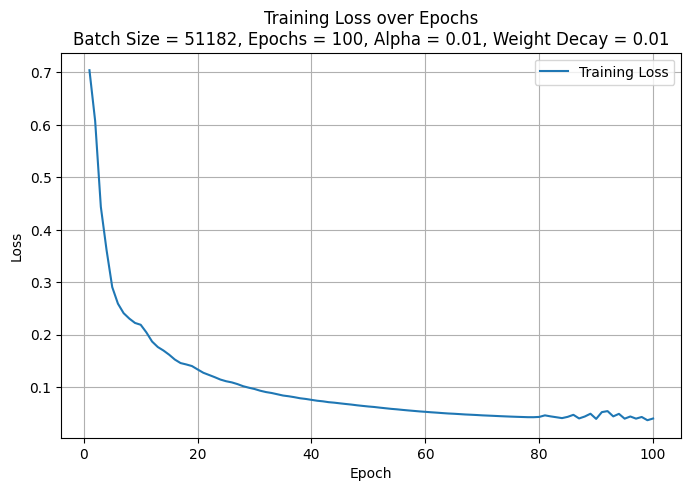

Train loss 0.0385 | Valid loss 0.3282
Valid ROC AUC: 0.966
              precision    recall  f1-score   support

           0      0.995     0.877     0.932     13892
           1      0.453     0.961     0.616      1475

    accuracy                          0.885     15367
   macro avg      0.724     0.919     0.774     15367
weighted avg      0.943     0.885     0.902     15367

[[12181  1711]
 [   57  1418]]


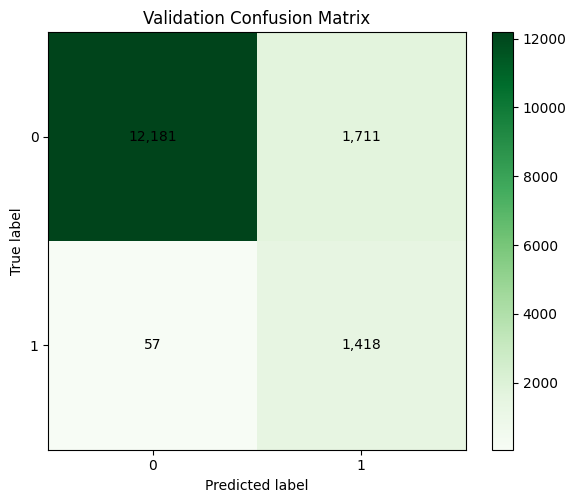

Iteration elapsed: 36.45s
 ==========     ==========     ==========     ==========
ITERATION [85/96]: 11:20:44 PM
    Batch Size:   51182
    Epochs:       100
    α:            0.01
    Weight Decay: 0.001
    
Epoch 1/100, Loss: 0.7041 | 0.054s
Epoch 2/100, Loss: 0.6096 | 0.060s
Epoch 3/100, Loss: 0.4434 | 0.030s
Epoch 4/100, Loss: 0.3619 | 0.044s
Epoch 5/100, Loss: 0.2911 | 0.044s
Epoch 6/100, Loss: 0.2594 | 0.056s
Epoch 7/100, Loss: 0.2416 | 0.009s
Epoch 8/100, Loss: 0.2316 | 0.017s
Epoch 9/100, Loss: 0.2240 | 0.015s
Epoch 10/100, Loss: 0.2226 | 0.019s
Epoch 11/100, Loss: 0.2101 | 0.012s
Epoch 12/100, Loss: 0.1939 | 0.042s
Epoch 13/100, Loss: 0.1841 | 0.017s
Epoch 14/100, Loss: 0.1776 | 0.048s
Epoch 15/100, Loss: 0.1702 | 0.048s
Epoch 16/100, Loss: 0.1611 | 0.050s
Epoch 17/100, Loss: 0.1528 | 0.039s
Epoch 18/100, Loss: 0.1477 | 0.044s
Epoch 19/100, Loss: 0.1446 | 0.048s
Epoch 20/100, Loss: 0.1393 | 0.040s
Epoch 21/100, Loss: 0.1328 | 0.039s
Epoch 22/100, Loss: 0.1280 | 0.037s
Epoch

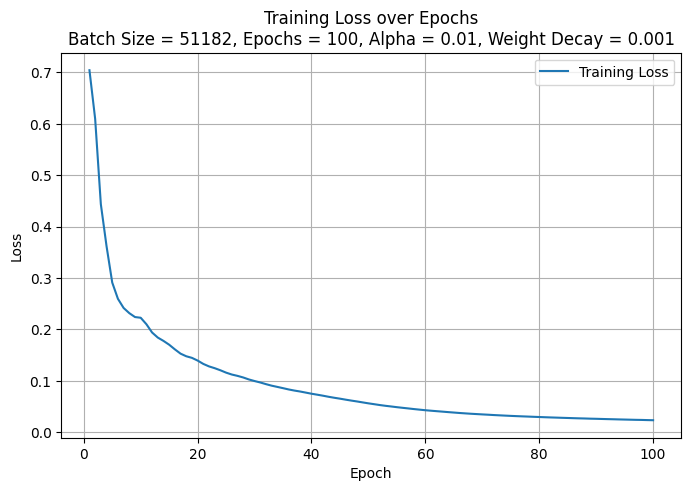

Train loss 0.0247 | Valid loss 0.4561
Valid ROC AUC: 0.961
              precision    recall  f1-score   support

           0      0.995     0.873     0.930     13892
           1      0.445     0.962     0.609      1475

    accuracy                          0.881     15367
   macro avg      0.720     0.917     0.769     15367
weighted avg      0.943     0.881     0.899     15367

[[12123  1769]
 [   56  1419]]


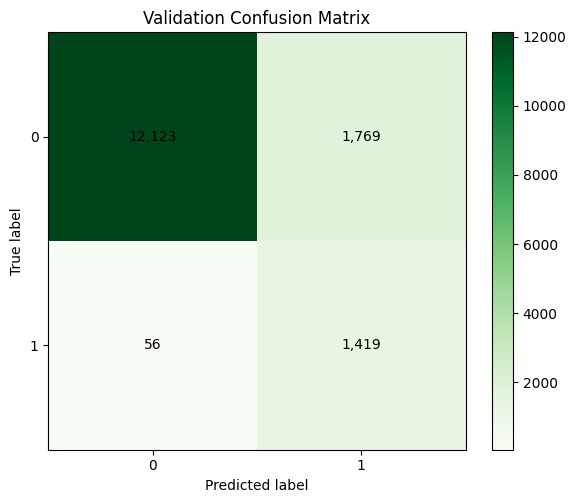

Iteration elapsed: 36.92s
 ==========     ==========     ==========     ==========
ITERATION [86/96]: 11:21:21 PM
    Batch Size:   51182
    Epochs:       100
    α:            0.001
    Weight Decay: 0.01
    
Epoch 1/100, Loss: 0.7041 | 0.023s
Epoch 2/100, Loss: 0.6193 | 0.025s
Epoch 3/100, Loss: 0.5583 | 0.030s
Epoch 4/100, Loss: 0.5166 | 0.037s
Epoch 5/100, Loss: 0.4859 | 0.049s
Epoch 6/100, Loss: 0.4604 | 0.060s
Epoch 7/100, Loss: 0.4377 | 0.046s
Epoch 8/100, Loss: 0.4169 | 0.047s
Epoch 9/100, Loss: 0.3977 | 0.054s
Epoch 10/100, Loss: 0.3802 | 0.020s
Epoch 11/100, Loss: 0.3644 | 0.015s
Epoch 12/100, Loss: 0.3505 | 0.018s
Epoch 13/100, Loss: 0.3381 | 0.012s
Epoch 14/100, Loss: 0.3269 | 0.015s
Epoch 15/100, Loss: 0.3167 | 0.011s
Epoch 16/100, Loss: 0.3073 | 0.021s
Epoch 17/100, Loss: 0.2986 | 0.013s
Epoch 18/100, Loss: 0.2905 | 0.046s
Epoch 19/100, Loss: 0.2829 | 0.056s
Epoch 20/100, Loss: 0.2758 | 0.057s
Epoch 21/100, Loss: 0.2693 | 0.045s
Epoch 22/100, Loss: 0.2632 | 0.042s
Epoch

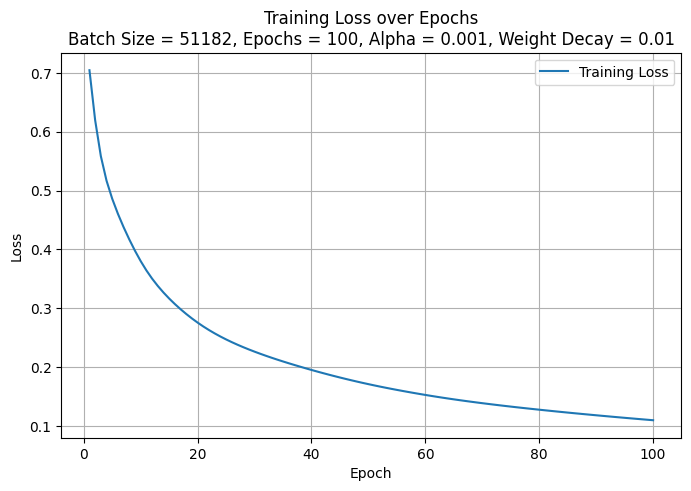

Train loss 0.1291 | Valid loss 0.3545
Valid ROC AUC: 0.947
              precision    recall  f1-score   support

           0      0.990     0.854     0.917     13892
           1      0.400     0.919     0.557      1475

    accuracy                          0.860     15367
   macro avg      0.695     0.886     0.737     15367
weighted avg      0.933     0.860     0.882     15367

[[11857  2035]
 [  119  1356]]


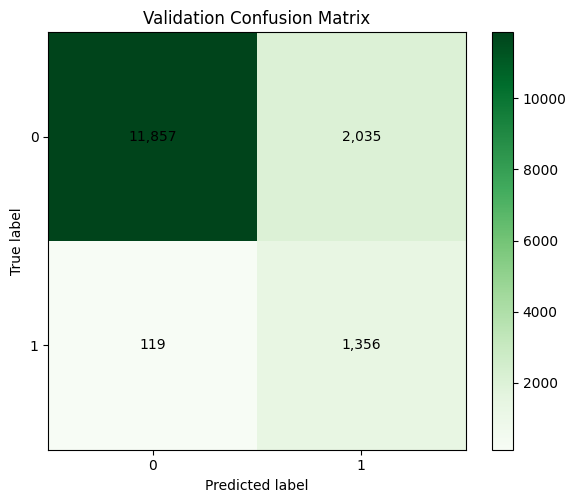

Iteration elapsed: 36.67s
 ==========     ==========     ==========     ==========
ITERATION [87/96]: 11:21:58 PM
    Batch Size:   51182
    Epochs:       100
    α:            0.001
    Weight Decay: 0.001
    
Epoch 1/100, Loss: 0.7041 | 0.047s
Epoch 2/100, Loss: 0.6192 | 0.043s
Epoch 3/100, Loss: 0.5582 | 0.053s
Epoch 4/100, Loss: 0.5166 | 0.034s
Epoch 5/100, Loss: 0.4860 | 0.010s
Epoch 6/100, Loss: 0.4604 | 0.018s
Epoch 7/100, Loss: 0.4377 | 0.012s
Epoch 8/100, Loss: 0.4168 | 0.019s
Epoch 9/100, Loss: 0.3975 | 0.013s
Epoch 10/100, Loss: 0.3799 | 0.039s
Epoch 11/100, Loss: 0.3641 | 0.058s
Epoch 12/100, Loss: 0.3501 | 0.040s
Epoch 13/100, Loss: 0.3376 | 0.045s
Epoch 14/100, Loss: 0.3264 | 0.054s
Epoch 15/100, Loss: 0.3161 | 0.037s
Epoch 16/100, Loss: 0.3066 | 0.046s
Epoch 17/100, Loss: 0.2979 | 0.045s
Epoch 18/100, Loss: 0.2897 | 0.017s
Epoch 19/100, Loss: 0.2821 | 0.009s
Epoch 20/100, Loss: 0.2750 | 0.017s
Epoch 21/100, Loss: 0.2684 | 0.009s
Epoch 22/100, Loss: 0.2623 | 0.018s
Epoc

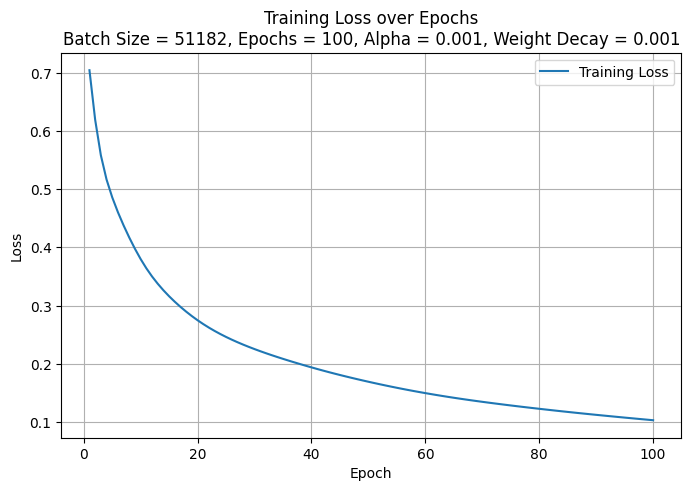

Train loss 0.1203 | Valid loss 0.3892
Valid ROC AUC: 0.944
              precision    recall  f1-score   support

           0      0.990     0.836     0.906     13892
           1      0.373     0.918     0.530      1475

    accuracy                          0.844     15367
   macro avg      0.681     0.877     0.718     15367
weighted avg      0.930     0.844     0.870     15367

[[11613  2279]
 [  121  1354]]


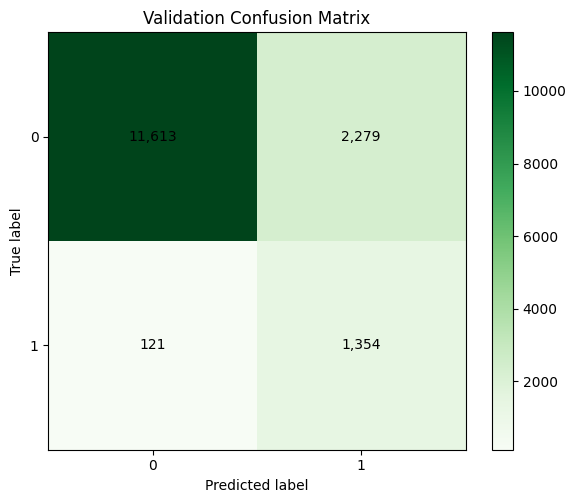

Iteration elapsed: 35.98s
 ==========     ==========     ==========     ==========
ITERATION [88/96]: 11:22:34 PM
    Batch Size:   51182
    Epochs:       150
    α:            0.01
    Weight Decay: 0.01
    
Epoch 1/150, Loss: 0.7041 | 0.053s
Epoch 2/150, Loss: 0.6073 | 0.045s
Epoch 3/150, Loss: 0.4434 | 0.053s
Epoch 4/150, Loss: 0.3614 | 0.049s
Epoch 5/150, Loss: 0.2904 | 0.057s
Epoch 6/150, Loss: 0.2589 | 0.063s
Epoch 7/150, Loss: 0.2407 | 0.012s
Epoch 8/150, Loss: 0.2304 | 0.017s
Epoch 9/150, Loss: 0.2221 | 0.016s
Epoch 10/150, Loss: 0.2186 | 0.018s
Epoch 11/150, Loss: 0.2040 | 0.014s
Epoch 12/150, Loss: 0.1866 | 0.044s
Epoch 13/150, Loss: 0.1762 | 0.016s
Epoch 14/150, Loss: 0.1695 | 0.017s
Epoch 15/150, Loss: 0.1615 | 0.017s
Epoch 16/150, Loss: 0.1522 | 0.045s
Epoch 17/150, Loss: 0.1456 | 0.046s
Epoch 18/150, Loss: 0.1429 | 0.046s
Epoch 19/150, Loss: 0.1399 | 0.052s
Epoch 20/150, Loss: 0.1334 | 0.020s
Epoch 21/150, Loss: 0.1271 | 0.015s
Epoch 22/150, Loss: 0.1229 | 0.017s
Epoch 

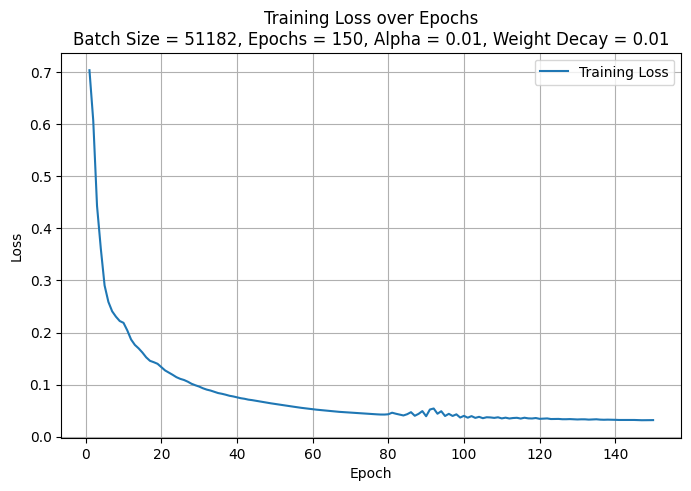

Train loss 0.0372 | Valid loss 0.3362
Valid ROC AUC: 0.965
              precision    recall  f1-score   support

           0      0.996     0.873     0.931     13892
           1      0.448     0.968     0.612      1475

    accuracy                          0.882     15367
   macro avg      0.722     0.921     0.771     15367
weighted avg      0.943     0.882     0.900     15367

[[12130  1762]
 [   47  1428]]


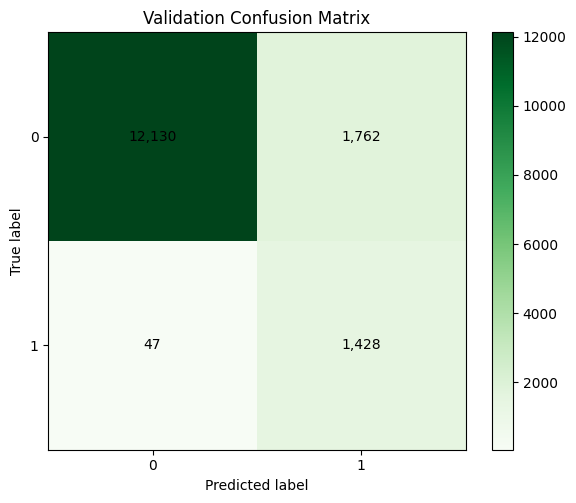

Iteration elapsed: 52.54s
 ==========     ==========     ==========     ==========
ITERATION [89/96]: 11:23:27 PM
    Batch Size:   51182
    Epochs:       150
    α:            0.01
    Weight Decay: 0.001
    
Epoch 1/150, Loss: 0.7041 | 0.019s
Epoch 2/150, Loss: 0.6096 | 0.024s
Epoch 3/150, Loss: 0.4434 | 0.047s
Epoch 4/150, Loss: 0.3619 | 0.049s
Epoch 5/150, Loss: 0.2911 | 0.039s
Epoch 6/150, Loss: 0.2594 | 0.062s
Epoch 7/150, Loss: 0.2416 | 0.040s
Epoch 8/150, Loss: 0.2316 | 0.039s
Epoch 9/150, Loss: 0.2240 | 0.052s
Epoch 10/150, Loss: 0.2226 | 0.053s
Epoch 11/150, Loss: 0.2101 | 0.010s
Epoch 12/150, Loss: 0.1939 | 0.019s
Epoch 13/150, Loss: 0.1841 | 0.010s
Epoch 14/150, Loss: 0.1776 | 0.015s
Epoch 15/150, Loss: 0.1702 | 0.011s
Epoch 16/150, Loss: 0.1611 | 0.048s
Epoch 17/150, Loss: 0.1528 | 0.039s
Epoch 18/150, Loss: 0.1477 | 0.043s
Epoch 19/150, Loss: 0.1446 | 0.056s
Epoch 20/150, Loss: 0.1393 | 0.019s
Epoch 21/150, Loss: 0.1328 | 0.011s
Epoch 22/150, Loss: 0.1280 | 0.019s
Epoch

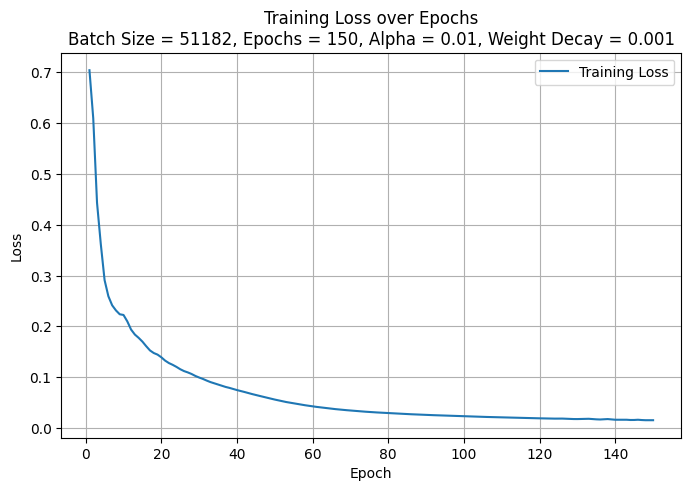

Train loss 0.0152 | Valid loss 0.4629
Valid ROC AUC: 0.955
              precision    recall  f1-score   support

           0      0.994     0.877     0.932     13892
           1      0.450     0.951     0.611      1475

    accuracy                          0.884     15367
   macro avg      0.722     0.914     0.771     15367
weighted avg      0.942     0.884     0.901     15367

[[12177  1715]
 [   72  1403]]


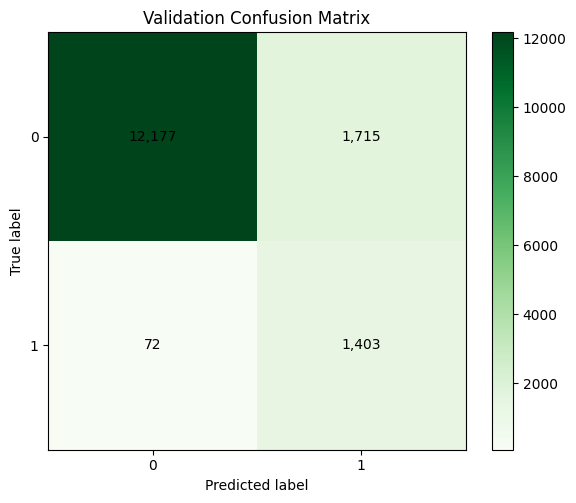

Iteration elapsed: 54.28s
 ==========     ==========     ==========     ==========
ITERATION [90/96]: 11:24:22 PM
    Batch Size:   51182
    Epochs:       150
    α:            0.001
    Weight Decay: 0.01
    
Epoch 1/150, Loss: 0.7041 | 0.061s
Epoch 2/150, Loss: 0.6193 | 0.044s
Epoch 3/150, Loss: 0.5583 | 0.029s
Epoch 4/150, Loss: 0.5166 | 0.047s
Epoch 5/150, Loss: 0.4859 | 0.030s
Epoch 6/150, Loss: 0.4604 | 0.017s
Epoch 7/150, Loss: 0.4377 | 0.013s
Epoch 8/150, Loss: 0.4169 | 0.020s
Epoch 9/150, Loss: 0.3977 | 0.009s
Epoch 10/150, Loss: 0.3802 | 0.019s
Epoch 11/150, Loss: 0.3644 | 0.046s
Epoch 12/150, Loss: 0.3505 | 0.043s
Epoch 13/150, Loss: 0.3381 | 0.034s
Epoch 14/150, Loss: 0.3269 | 0.045s
Epoch 15/150, Loss: 0.3167 | 0.037s
Epoch 16/150, Loss: 0.3073 | 0.022s
Epoch 17/150, Loss: 0.2986 | 0.010s
Epoch 18/150, Loss: 0.2905 | 0.020s
Epoch 19/150, Loss: 0.2829 | 0.012s
Epoch 20/150, Loss: 0.2758 | 0.014s
Epoch 21/150, Loss: 0.2693 | 0.052s
Epoch 22/150, Loss: 0.2632 | 0.041s
Epoch

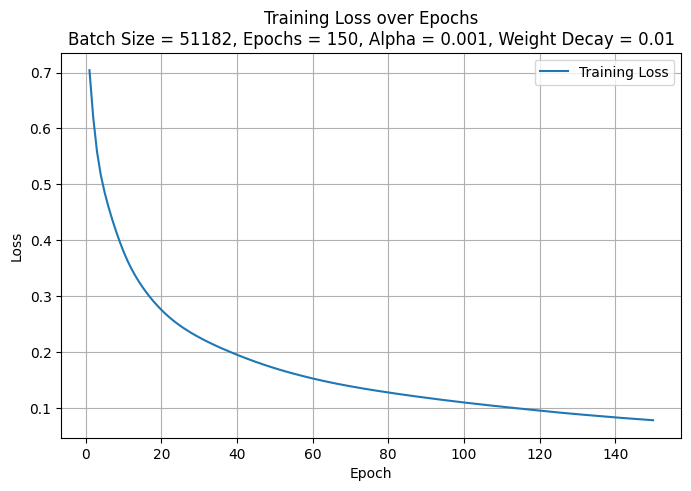

Train loss 0.0915 | Valid loss 0.3319
Valid ROC AUC: 0.959
              precision    recall  f1-score   support

           0      0.993     0.878     0.932     13892
           1      0.451     0.943     0.610      1475

    accuracy                          0.884     15367
   macro avg      0.722     0.911     0.771     15367
weighted avg      0.941     0.884     0.901     15367

[[12201  1691]
 [   84  1391]]


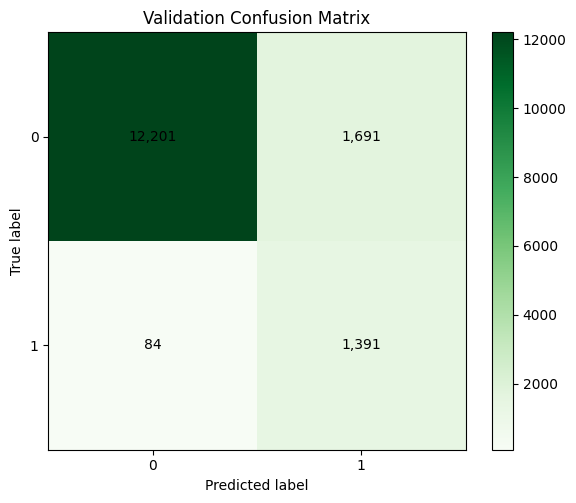

Iteration elapsed: 55.00s
 ==========     ==========     ==========     ==========
ITERATION [91/96]: 11:25:17 PM
    Batch Size:   51182
    Epochs:       150
    α:            0.001
    Weight Decay: 0.001
    
Epoch 1/150, Loss: 0.7041 | 0.059s
Epoch 2/150, Loss: 0.6192 | 0.049s
Epoch 3/150, Loss: 0.5582 | 0.043s
Epoch 4/150, Loss: 0.5166 | 0.041s
Epoch 5/150, Loss: 0.4860 | 0.044s
Epoch 6/150, Loss: 0.4604 | 0.018s
Epoch 7/150, Loss: 0.4377 | 0.014s
Epoch 8/150, Loss: 0.4168 | 0.020s
Epoch 9/150, Loss: 0.3975 | 0.010s
Epoch 10/150, Loss: 0.3799 | 0.015s
Epoch 11/150, Loss: 0.3641 | 0.051s
Epoch 12/150, Loss: 0.3501 | 0.046s
Epoch 13/150, Loss: 0.3376 | 0.047s
Epoch 14/150, Loss: 0.3264 | 0.047s
Epoch 15/150, Loss: 0.3161 | 0.022s
Epoch 16/150, Loss: 0.3066 | 0.016s
Epoch 17/150, Loss: 0.2979 | 0.015s
Epoch 18/150, Loss: 0.2897 | 0.017s
Epoch 19/150, Loss: 0.2821 | 0.010s
Epoch 20/150, Loss: 0.2750 | 0.016s
Epoch 21/150, Loss: 0.2684 | 0.057s
Epoch 22/150, Loss: 0.2623 | 0.051s
Epoc

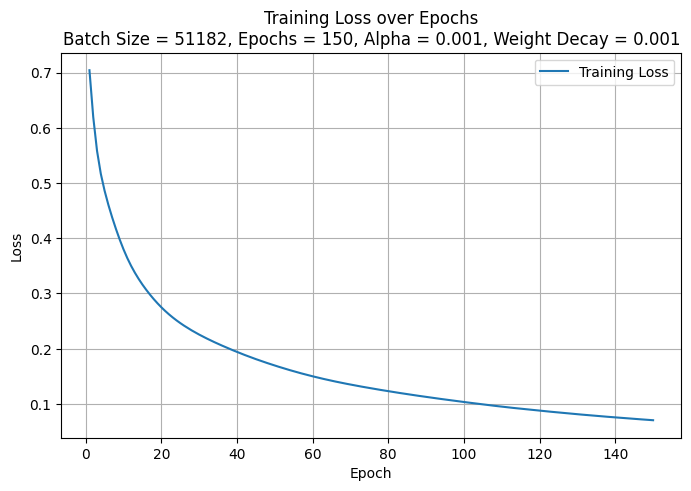

Train loss 0.0808 | Valid loss 0.3812
Valid ROC AUC: 0.956
              precision    recall  f1-score   support

           0      0.992     0.863     0.923     13892
           1      0.421     0.936     0.581      1475

    accuracy                          0.870     15367
   macro avg      0.707     0.900     0.752     15367
weighted avg      0.937     0.870     0.890     15367

[[11994  1898]
 [   94  1381]]


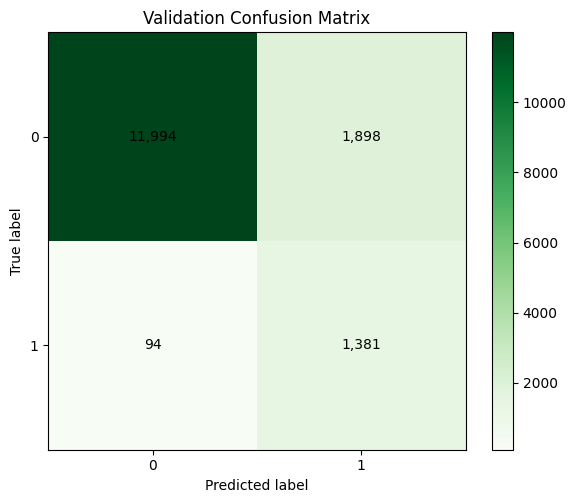

Iteration elapsed: 55.07s
 ==========     ==========     ==========     ==========
ITERATION [92/96]: 11:26:12 PM
    Batch Size:   51182
    Epochs:       200
    α:            0.01
    Weight Decay: 0.01
    
Epoch 1/200, Loss: 0.7041 | 0.060s
Epoch 2/200, Loss: 0.6073 | 0.050s
Epoch 3/200, Loss: 0.4434 | 0.053s
Epoch 4/200, Loss: 0.3614 | 0.055s
Epoch 5/200, Loss: 0.2904 | 0.029s
Epoch 6/200, Loss: 0.2589 | 0.037s
Epoch 7/200, Loss: 0.2407 | 0.039s
Epoch 8/200, Loss: 0.2304 | 0.037s
Epoch 9/200, Loss: 0.2221 | 0.058s
Epoch 10/200, Loss: 0.2186 | 0.043s
Epoch 11/200, Loss: 0.2040 | 0.057s
Epoch 12/200, Loss: 0.1866 | 0.019s
Epoch 13/200, Loss: 0.1762 | 0.010s
Epoch 14/200, Loss: 0.1695 | 0.016s
Epoch 15/200, Loss: 0.1615 | 0.010s
Epoch 16/200, Loss: 0.1522 | 0.018s
Epoch 17/200, Loss: 0.1456 | 0.033s
Epoch 18/200, Loss: 0.1429 | 0.046s
Epoch 19/200, Loss: 0.1399 | 0.047s
Epoch 20/200, Loss: 0.1334 | 0.040s
Epoch 21/200, Loss: 0.1271 | 0.063s
Epoch 22/200, Loss: 0.1229 | 0.018s
Epoch 

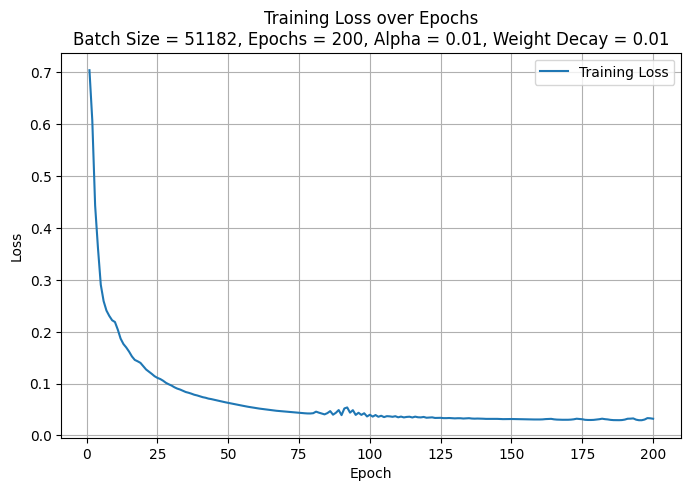

Train loss 0.0321 | Valid loss 0.3309
Valid ROC AUC: 0.962
              precision    recall  f1-score   support

           0      0.996     0.875     0.932     13892
           1      0.451     0.967     0.615      1475

    accuracy                          0.884     15367
   macro avg      0.723     0.921     0.773     15367
weighted avg      0.944     0.884     0.901     15367

[[12154  1738]
 [   48  1427]]


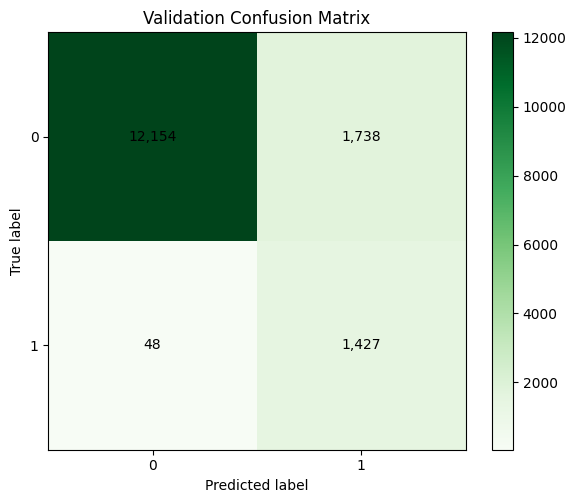

Iteration elapsed: 72.50s
 ==========     ==========     ==========     ==========
ITERATION [93/96]: 11:27:25 PM
    Batch Size:   51182
    Epochs:       200
    α:            0.01
    Weight Decay: 0.001
    
Epoch 1/200, Loss: 0.7041 | 0.018s
Epoch 2/200, Loss: 0.6096 | 0.019s
Epoch 3/200, Loss: 0.4434 | 0.056s
Epoch 4/200, Loss: 0.3619 | 0.046s
Epoch 5/200, Loss: 0.2911 | 0.037s
Epoch 6/200, Loss: 0.2594 | 0.045s
Epoch 7/200, Loss: 0.2416 | 0.015s
Epoch 8/200, Loss: 0.2316 | 0.023s
Epoch 9/200, Loss: 0.2240 | 0.009s
Epoch 10/200, Loss: 0.2226 | 0.014s
Epoch 11/200, Loss: 0.2101 | 0.010s
Epoch 12/200, Loss: 0.1939 | 0.017s
Epoch 13/200, Loss: 0.1841 | 0.038s
Epoch 14/200, Loss: 0.1776 | 0.049s
Epoch 15/200, Loss: 0.1702 | 0.036s
Epoch 16/200, Loss: 0.1611 | 0.073s
Epoch 17/200, Loss: 0.1528 | 0.012s
Epoch 18/200, Loss: 0.1477 | 0.016s
Epoch 19/200, Loss: 0.1446 | 0.010s
Epoch 20/200, Loss: 0.1393 | 0.020s
Epoch 21/200, Loss: 0.1328 | 0.009s
Epoch 22/200, Loss: 0.1280 | 0.019s
Epoch

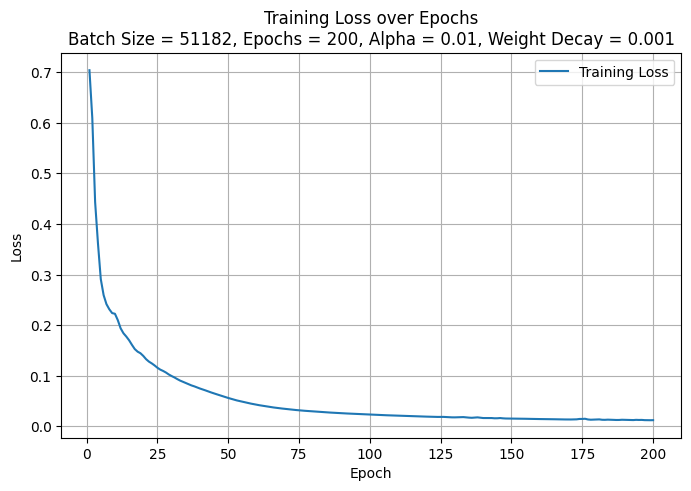

Train loss 0.0113 | Valid loss 0.4595
Valid ROC AUC: 0.950
              precision    recall  f1-score   support

           0      0.991     0.879     0.932     13892
           1      0.448     0.927     0.604      1475

    accuracy                          0.884     15367
   macro avg      0.720     0.903     0.768     15367
weighted avg      0.939     0.884     0.900     15367

[[12210  1682]
 [  108  1367]]


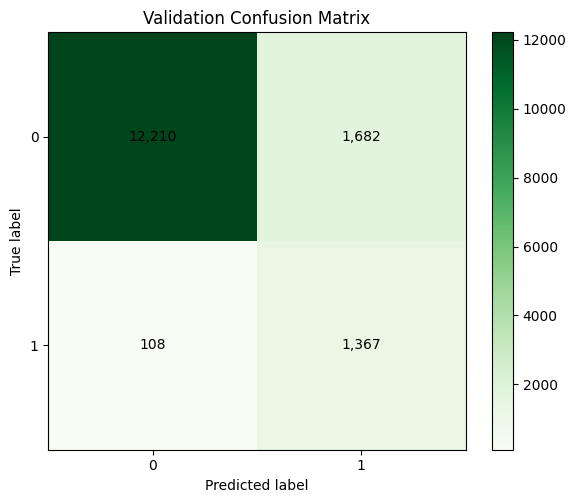

Iteration elapsed: 70.87s
 ==========     ==========     ==========     ==========
ITERATION [94/96]: 11:28:36 PM
    Batch Size:   51182
    Epochs:       200
    α:            0.001
    Weight Decay: 0.01
    
Epoch 1/200, Loss: 0.7041 | 0.073s
Epoch 2/200, Loss: 0.6193 | 0.040s
Epoch 3/200, Loss: 0.5583 | 0.048s
Epoch 4/200, Loss: 0.5166 | 0.044s
Epoch 5/200, Loss: 0.4859 | 0.042s
Epoch 6/200, Loss: 0.4604 | 0.018s
Epoch 7/200, Loss: 0.4377 | 0.013s
Epoch 8/200, Loss: 0.4169 | 0.025s
Epoch 9/200, Loss: 0.3977 | 0.025s
Epoch 10/200, Loss: 0.3802 | 0.019s
Epoch 11/200, Loss: 0.3644 | 0.055s
Epoch 12/200, Loss: 0.3505 | 0.042s
Epoch 13/200, Loss: 0.3381 | 0.030s
Epoch 14/200, Loss: 0.3269 | 0.046s
Epoch 15/200, Loss: 0.3167 | 0.039s
Epoch 16/200, Loss: 0.3073 | 0.044s
Epoch 17/200, Loss: 0.2986 | 0.037s
Epoch 18/200, Loss: 0.2905 | 0.016s
Epoch 19/200, Loss: 0.2829 | 0.010s
Epoch 20/200, Loss: 0.2758 | 0.019s
Epoch 21/200, Loss: 0.2693 | 0.015s
Epoch 22/200, Loss: 0.2632 | 0.018s
Epoch

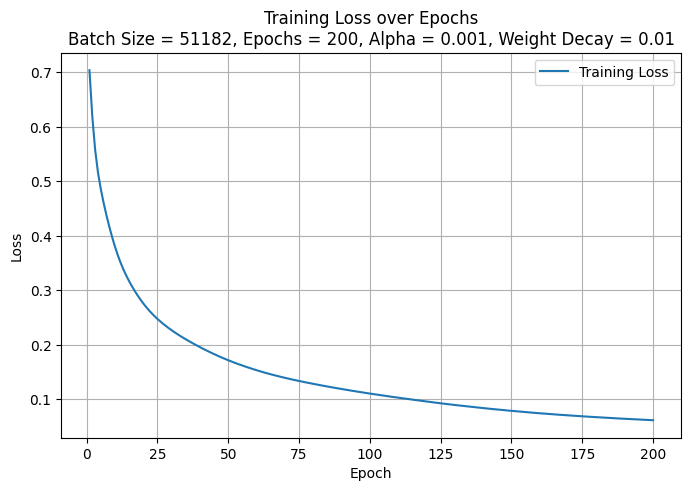

Train loss 0.0711 | Valid loss 0.3220
Valid ROC AUC: 0.965
              precision    recall  f1-score   support

           0      0.994     0.879     0.933     13892
           1      0.454     0.950     0.614      1475

    accuracy                          0.886     15367
   macro avg      0.724     0.914     0.774     15367
weighted avg      0.942     0.886     0.902     15367

[[12207  1685]
 [   74  1401]]


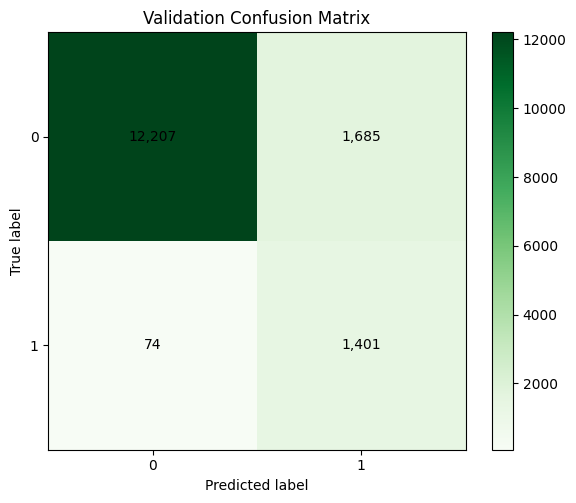

Iteration elapsed: 70.95s
 ==========     ==========     ==========     ==========
ITERATION [95/96]: 11:29:47 PM
    Batch Size:   51182
    Epochs:       200
    α:            0.001
    Weight Decay: 0.001
    
Epoch 1/200, Loss: 0.7041 | 0.063s
Epoch 2/200, Loss: 0.6192 | 0.040s
Epoch 3/200, Loss: 0.5582 | 0.051s
Epoch 4/200, Loss: 0.5166 | 0.045s
Epoch 5/200, Loss: 0.4860 | 0.040s
Epoch 6/200, Loss: 0.4604 | 0.013s
Epoch 7/200, Loss: 0.4377 | 0.012s
Epoch 8/200, Loss: 0.4168 | 0.016s
Epoch 9/200, Loss: 0.3975 | 0.012s
Epoch 10/200, Loss: 0.3799 | 0.020s
Epoch 11/200, Loss: 0.3641 | 0.013s
Epoch 12/200, Loss: 0.3501 | 0.020s
Epoch 13/200, Loss: 0.3376 | 0.038s
Epoch 14/200, Loss: 0.3264 | 0.051s
Epoch 15/200, Loss: 0.3161 | 0.037s
Epoch 16/200, Loss: 0.3066 | 0.060s
Epoch 17/200, Loss: 0.2979 | 0.010s
Epoch 18/200, Loss: 0.2897 | 0.020s
Epoch 19/200, Loss: 0.2821 | 0.020s
Epoch 20/200, Loss: 0.2750 | 0.017s
Epoch 21/200, Loss: 0.2684 | 0.016s
Epoch 22/200, Loss: 0.2623 | 0.040s
Epoc

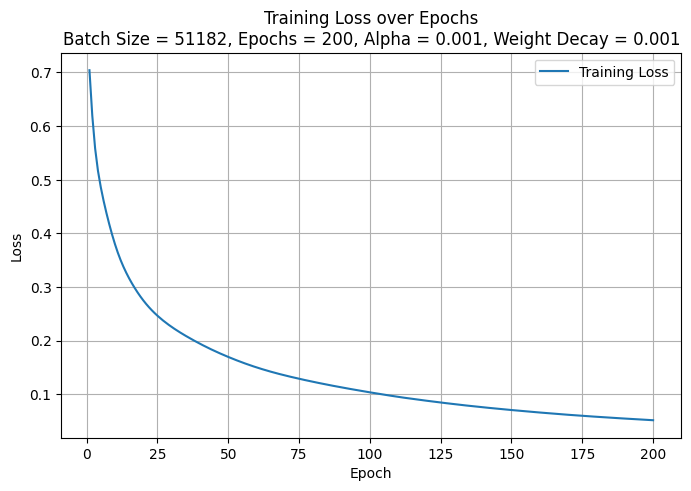

Train loss 0.0589 | Valid loss 0.3852
Valid ROC AUC: 0.960
              precision    recall  f1-score   support

           0      0.993     0.871     0.928     13892
           1      0.435     0.940     0.595      1475

    accuracy                          0.877     15367
   macro avg      0.714     0.905     0.761     15367
weighted avg      0.939     0.877     0.896     15367

[[12095  1797]
 [   89  1386]]


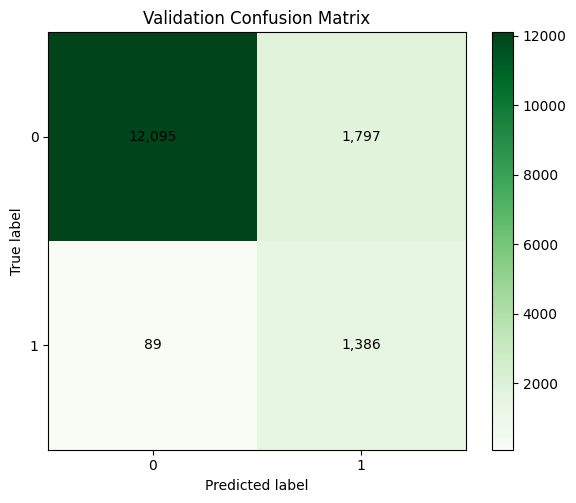

Iteration elapsed: 73.02s


In [20]:
# %%script false --no-raise-error

for i, (batch_size_, epoch_, alpha_, weightDecay_) in enumerate(product(*params)):
    # Time
    model_now   = datetime.now()
    model_start = perf_counter() # Start timer
    print(
    f""" ==========     ==========     ==========     ==========
ITERATION [{i}/{len(BATCHES)*len(EPOCHS)*len(ALPHAS)*len(WEIGHT_DECAY)}]: {model_now.strftime("%I:%M:%S %p")}
    Batch Size:   {batch_size_}
    Epochs:       {epoch_}
    α:            {alpha_}
    Weight Decay: {weightDecay_}
    """
    )

    # Training
    MLP_MODEL, MLP_MODEL_epoch_log, MLP_MODEL_loss_log = fit(
        MLP, train_data,
        ITER_epochs      =epoch_,
        ITER_batchSize   =batch_size_,
        ITER_alpha       =alpha_,
        ITER_weight_decay=weightDecay_
    )

    # Training Loss / Epochs
    Path("images/optimize").mkdir(parents=True, exist_ok=True)
    plt.figure(figsize=(8, 5))
    plt.plot(MLP_MODEL_epoch_log, MLP_MODEL_loss_log, label='Training Loss')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.title(f"Training Loss over Epochs\nBatch Size = {batch_size_}, Epochs = {epoch_}, Alpha = {alpha_}, Weight Decay = {weightDecay_}")
    plt.legend()
    plt.grid(True)
    plt.savefig(f'images/optimize/MLP_Optimize-Training_Loss_over_Epochs-batchSize-{batch_size_}_epoch-{epoch_}_alpha-{alpha_}_weightDecay{weightDecay_}.png', dpi=300, bbox_inches='tight')
    plt.show()

    # Evaluation
    valid_loss, valid_probs, valid_labels = evaluate(MLP_MODEL, valid_loader)
    train_loss, train_probs, train_labels = evaluate(MLP_MODEL, train_loader)

    THRESHOLD = 0.5
    valid_preds = (valid_probs >= THRESHOLD).astype(int)

    cm = confusion_matrix(valid_labels, valid_preds)

    print(f"Train loss {train_loss:.4f} | Valid loss {valid_loss:.4f}")
    print(f"Valid ROC AUC: {roc_auc_score(valid_labels, valid_probs):.3f}")
    print(classification_report(valid_labels, valid_preds, digits=3))
    print(cm)

    # Validation Confusion Matrix
    fig, ax = plt.subplots(figsize=(6, 5))
    image = ax.imshow(cm, cmap="Greens")
    fig.colorbar(image, ax=ax)

    ax.set(
        xticks=np.arange(2),
        yticks=np.arange(2),
        xticklabels=["0", "1"],
        yticklabels=["0", "1"],
        xlabel="Predicted label",
        ylabel="True label",
        title="Validation Confusion Matrix",
    )

    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            ax.text(j, i, f"{cm[i, j]:,}", ha="center", va="center")

    plt.tight_layout()
    plt.savefig(f'images/optimize/MLP_Manual-Validation_Confusion_Matrix-batchSize-{batch_size_}_epoch-{epoch_}_alpha-{alpha_}_weightDecay{weightDecay_}.png', dpi=300, bbox_inches='tight')
    plt.show()
    plt.close("all")

    # Define and log current run parameters
    F1 = f1_score(valid_labels, valid_preds, pos_label=1)
    run_parameters = {
        "Batch Size": batch_size_,
        "Epochs": epoch_,
        "Alpha": alpha_,
        "Weight Decay": weightDecay_,
        "F1": F1
    }
    runLog.append(run_parameters)

    model_elapsed = perf_counter() - model_start # End timer
    print(f"Iteration elapsed: {model_elapsed:.2f}s")

    del (
        MLP_MODEL, MLP_MODEL_epoch_log, MLP_MODEL_loss_log,
        valid_loss, valid_probs, valid_labels, train_loss,
        train_probs, train_labels, valid_preds, cm,
        fig, ax, image,
        F1, run_parameters, model_elapsed
    )

    if torch.cuda.is_available():
        torch.cuda.synchronize()
        torch.cuda.empty_cache()
    gc.collect()

In [21]:
f1_list = [item["F1"] for item in runLog]
max_index = max(range(len(f1_list)), key=f1_list.__getitem__)
max_index, f1_list[max_index]
f"[{max_index}]: F1 Score - {f1_list[max_index]}"

'[27]: F1 Score - 0.6203473945409429'

In [22]:
runLog[max_index]

{'Batch Size': 1024,
 'Epochs': 150,
 'Alpha': 0.001,
 'Weight Decay': 0.001,
 'F1': 0.6203473945409429}

In [23]:
final_parameters = {
    "Batch Size": runLog[max_index]['Batch Size'],
    "Epochs": runLog[max_index]['Epochs'],
    "Alpha": runLog[max_index]['Alpha'],
    "Weight Decay": runLog[max_index]['Weight Decay'],
    "F1": runLog[max_index]['F1']
}
"""Saved parameters of run"""

final_parameters

{'Batch Size': 1024,
 'Epochs': 150,
 'Alpha': 0.001,
 'Weight Decay': 0.001,
 'F1': 0.6203473945409429}

## Finalized
Aims to isolate and rerun the model with the best F1.
### Training

In [ ]:
MLP_MODEL_Final, MLP_MODEL_epoch_log_Final, MLP_MODEL_loss_log_Final = fit(
    MLP, train_data,
    ITER_epochs      =final_parameters['Epochs'],      
    ITER_batchSize   =final_parameters['Batch Size'],  
    ITER_alpha       =final_parameters['Alpha'],       
    ITER_weight_decay=final_parameters['Weight Decay'] 
)

Epoch 1/150, Loss: 0.6346 | 0.003s
Epoch 2/150, Loss: 0.2883 | 0.005s
Epoch 3/150, Loss: 0.2271 | 0.003s
Epoch 4/150, Loss: 0.1880 | 0.002s
Epoch 5/150, Loss: 0.1633 | 0.003s
Epoch 6/150, Loss: 0.1456 | 0.011s
Epoch 7/150, Loss: 0.1316 | 0.002s
Epoch 8/150, Loss: 0.1197 | 0.002s
Epoch 9/150, Loss: 0.1093 | 0.002s
Epoch 10/150, Loss: 0.1002 | 0.003s
Epoch 11/150, Loss: 0.0920 | 0.003s
Epoch 12/150, Loss: 0.0849 | 0.011s
Epoch 13/150, Loss: 0.0785 | 0.005s
Epoch 14/150, Loss: 0.0728 | 0.002s
Epoch 15/150, Loss: 0.0676 | 0.002s
Epoch 16/150, Loss: 0.0629 | 0.002s
Epoch 17/150, Loss: 0.0587 | 0.011s
Epoch 18/150, Loss: 0.0549 | 0.004s
Epoch 19/150, Loss: 0.0514 | 0.003s
Epoch 20/150, Loss: 0.0486 | 0.004s
Epoch 21/150, Loss: 0.0459 | 0.002s
Epoch 22/150, Loss: 0.0434 | 0.007s
Epoch 23/150, Loss: 0.0416 | 0.008s
Epoch 24/150, Loss: 0.0396 | 0.002s
Epoch 25/150, Loss: 0.0379 | 0.003s
Epoch 26/150, Loss: 0.0364 | 0.002s
Epoch 27/150, Loss: 0.0350 | 0.004s
Epoch 28/150, Loss: 0.0335 | 0.002s
E

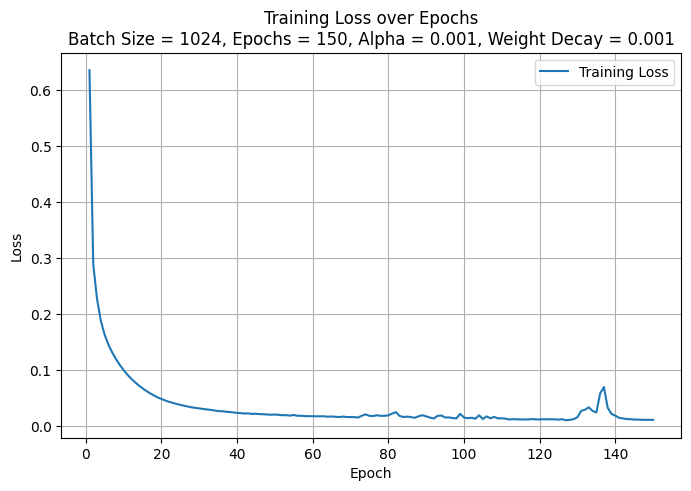

In [25]:
Path("images/final").mkdir(parents=True, exist_ok=True)
plt.figure(figsize=(8, 5))
plt.plot(MLP_MODEL_epoch_log_Final, MLP_MODEL_loss_log_Final, label='Training Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title(f"Training Loss over Epochs\nBatch Size = {final_parameters['Batch Size']}, Epochs = {final_parameters['Epochs']}, Alpha = {final_parameters['Alpha']}, Weight Decay = {final_parameters['Weight Decay']}")
plt.legend()
plt.grid(True)
plt.savefig(f'images/final/FINAL_MLP_Optimize-Training_Loss_over_Epochs-batchSize-{final_parameters['Batch Size']}_epoch-{final_parameters['Epochs']}_alpha-{final_parameters['Alpha']}_weightDecay{final_parameters['Weight Decay']}.png', dpi=300, bbox_inches='tight')
plt.show()

### Evaluate Model

In [26]:
valid_loss, valid_probs, valid_labels = evaluate(MLP_MODEL_Final, valid_loader)
train_loss, train_probs, train_labels = evaluate(MLP_MODEL_Final, train_loader)

THRESHOLD = 0.5
valid_preds = (valid_probs >= THRESHOLD).astype(int)

cm = confusion_matrix(valid_labels, valid_preds)

print(f"Train loss {train_loss:.4f} | Valid loss {valid_loss:.4f}")
print(f"Valid ROC AUC: {roc_auc_score(valid_labels, valid_probs):.3f}")
print(classification_report(valid_labels, valid_preds, digits=3))
print(cm)

Train loss 0.0082 | Valid loss 0.5325
Valid ROC AUC: 0.948
              precision    recall  f1-score   support

           0      0.992     0.886     0.936     13892
           1      0.465     0.932     0.620      1475

    accuracy                          0.890     15367
   macro avg      0.728     0.909     0.778     15367
weighted avg      0.941     0.890     0.906     15367

[[12309  1583]
 [  100  1375]]


### Validation Confusion Matrix

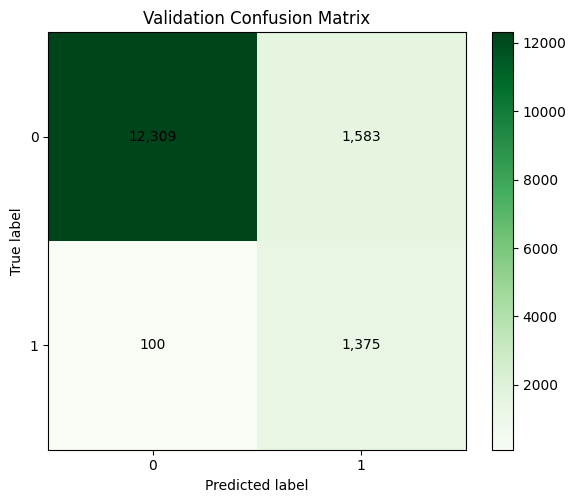

In [27]:
fig, ax = plt.subplots(figsize=(6, 5))
image = ax.imshow(cm, cmap="Greens")
fig.colorbar(image, ax=ax)

ax.set(
    xticks=np.arange(2),
    yticks=np.arange(2),
    xticklabels=["0", "1"],
    yticklabels=["0", "1"],
    xlabel="Predicted label",
    ylabel="True label",
    title="Validation Confusion Matrix",
)

for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        ax.text(j, i, f"{cm[i, j]:,}", ha="center", va="center")

plt.tight_layout()
plt.savefig(f'images/final/MLP_Manual-Validation_Confusion_Matrix-batchSize-{final_parameters['Batch Size']}_epoch-{final_parameters['Epochs']}_alpha-{final_parameters['Alpha']}_weightDecay{final_parameters['Weight Decay']}.png', dpi=300, bbox_inches='tight')
plt.show()
plt.close("all")

In [28]:
if torch.cuda.is_available():
    torch.cuda.synchronize()
    torch.cuda.empty_cache()

### Dump results to new file

In [29]:
import json

Path("contingency_parameters.txt").write_text("", encoding="utf-8")
with open("contingency_parameters.txt", "w", encoding="utf-8") as f:
    json.dump(final_parameters, f, indent=4)


‼️‼️‼️**DO NOT** DO THE FOLLOWING‼️‼️‼️
- **DO NOT** `Shift` + `F1` (personal shortcut for restarting/rerunning)
- **DO NOT** RESTART the server
- **DO NOT** RESET the server

✔️✔️✔️OK to do✔️✔️✔️
- `Ctrl` + `Alt` + `Enter` cells below

## Test